# Credit-card default classification — development notebook

**INFS7203 Track 1** · Student number **49769959** · UQ username **s4976995**

This notebook records the full development process: data audit, preprocessing comparisons, the four
required model families, tuning, threshold selection and the final model implemented in `main.py`.
The target is `defaulted_next_month` with `yes` as the positive class; `client_id` is never used as a predictor.

| Phase | Content |
|---|---|
| 0 | Sources, conventions and staff clarifications |
| 1 | Data audit |
| 2, 2b | First baseline and numeric imputation; repayment-status encoding |
| 3 | Baselines for naive Bayes, k-NN, decision tree and random forest |
| 4, 4b | Tuning and class weights; probability-threshold comparison |
| 4c | Unweighted forests with tuned thresholds |
| 4d | Missing-value handling and split criterion (final model selected) |
| 4e, 4f | Final parameter check; further preprocessing and model checks |
| 5 | Ensembles (Random Forest only) |
| 6 | Final model, cross-validation, test predictions and checks against `main.py` |
| 7 | Summary, limitations, course evidence and AI acknowledgement |

Run `python main.py` first, then run this notebook from the project folder with `data/development.csv`
and `data/test.csv` in place. Neither file is modified.

## Sources used

The brief (`references/brief/`, not submitted) is the academic specification. Lecture slides and coding
guides establish course coverage; for example, Week 4's coding guide teaches GridSearchCV and GaussianNB.
Staff clarifications from Ed Discussion (as of 14 October 2026) are summarised in the next cell;
their full text is kept in `docs/COURSE_CLARIFICATIONS.md`, which is not part of the submission.

## Phase 0 — sources and conventions

The full brief has been read and lecture references recorded in `docs/PROJECT_BRIEF.md` and `docs/LECTURE_EVIDENCE.md`. These documents separate supported techniques, covered concepts that are unsuitable here, and techniques settled by later staff clarifications (next cell).

Starting conventions: 5 stratified folds, shuffle enabled, random seed 42, F1(yes) for selection. All learned preprocessing belongs inside the CV training fold. These are proposed project choices, not results.

**How I would explain the setup:** I compare models using the same held-out folds. The preprocessing learns only from the training part of each fold, so the validation rows simulate unseen clients. I favour the simpler model when a more complex approach has little demonstrated benefit.

**Likely questions:**
- Why exclude `client_id`? It identifies a client and the brief explicitly disallows it as a predictor.
- Why use F1(yes)? It is the assignment's target metric, combining precision and recall for default cases.
- Why not impute using each row's known class? The class is unavailable when predicting new clients, and validation labels must not enter preprocessing.

## Staff clarifications that shape the method

Summary of the relevant Ed Discussion staff answers (as of 14 October 2026); links and full text are in
`docs/COURSE_CLARIFICATIONS.md`.

| Topic | Staff guidance | What this notebook does |
|---|---|---|
| Repayment status and imputation | Use repayment status as provided; use ordinary taught imputation; deriving financial rules is not the goal | Mode imputation initially; native missing handling in Phase 4d; nothing reconstructed from bills/payments; no rows "corrected" |
| Grid search and thresholds | GridSearchCV and selecting a probability threshold on development data are permitted | Bounded grids and disclosed threshold comparisons on out-of-fold probabilities |
| Class imbalance | `class_weight="balanced"` may be explored; random over/undersampling not permitted | `class_weight` compared for the tree and forest only; no resampling or SMOTE |
| Missing values | Off-the-shelf `KNNImputer` not acceptable; built-in tree/forest missing support may be explored | Simple imputation, taught missing indicators/categories, and native forest handling |
| Feature engineering | Keep to taught imputation, encoding and scaling | No ratios, aggregates, delay counts or reconstructed features |
| Ensembles | Use only Random Forest for ensembles | No voting, bagging, boosting or stacking model |
| Metric | Assessed F1 is F1 for `yes`, not macro-F1 | Select by F1(yes); report macro-F1 separately |
| Comparisons | One final classifier is fine with comparative evidence | Baselines for all four families before choosing |
| Reproducibility / oral | Document exact package versions; oral = presentation then questions (~10 min) | Versions printed in Phase 7 and listed in the README |

The latest announcement also discourages chasing tiny validation gains and calls the score ranges a
rough guide; it does not set a new formula or guarantee a mark. These answers do not show that the
variables are statistically independent, and they do not confirm our ordinal order for the three
non-delay repayment labels.

## Phase 1 — data audit

No model is trained in this phase.

This section only *looks at* the data. It does not delete, fill or change anything, because
every learned change (imputation, encoding, scaling) must later happen inside the
cross-validation training folds. Plots are saved in `figures/` so the README shows the same images.

The test file is only checked as an input contract (columns, row count, no target).
Its distribution is not used to choose any modelling method.

In [1]:
# Phase 1 setup: libraries, fixed names and the two original input files.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
FIGURE_DIR = Path("figures")
TARGET = "defaulted_next_month"
ID_COLUMN = "client_id"
POSITIVE_CLASS = "yes"

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
FIGURE_DIR.mkdir(exist_ok=True)

# Read the files without editing them; the originals in data/ are never overwritten.
development = pd.read_csv(DATA_DIR / "development.csv")
test = pd.read_csv(DATA_DIR / "test.csv")


def save_figure(fig, filename):
    """Save a plot in figures/ so the notebook and README show the same image."""
    fig.savefig(FIGURE_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

### 1.1 Dimensions and feature types

In [2]:
# Group the columns by role, following the column table in the brief (p.2).
predictor_columns = [c for c in development.columns if c not in (ID_COLUMN, TARGET)]
numeric_columns = development[predictor_columns].select_dtypes(include="number").columns.tolist()
demographic_columns = ["sex", "education", "marital_status"]
repayment_columns = [c for c in predictor_columns if c.startswith("repayment_status_")]
bill_columns = [c for c in predictor_columns if c.startswith("bill_amount_")]
payment_columns = [c for c in predictor_columns if c.startswith("payment_amount_")]

# Every predictor should belong to exactly one group, otherwise a column would be forgotten later.
assert sorted(numeric_columns + demographic_columns + repayment_columns) == sorted(predictor_columns)

print("Development shape (rows, columns):", development.shape)
print("Predictors (client_id and target excluded):", len(predictor_columns))
print("Numeric:", len(numeric_columns),
      "| demographic text:", len(demographic_columns),
      "| repayment-status text:", len(repayment_columns))

Development shape (rows, columns): (24000, 25)
Predictors (client_id and target excluded): 23
Numeric: 14 | demographic text: 3 | repayment-status text: 6


In [3]:
# One row per column: stored type, number of distinct values and a first non-missing example.
column_summary = pd.DataFrame({
    "dtype": development.dtypes.astype(str),
    "distinct_values": development.nunique(),
    "first_non_missing": development.apply(lambda column: column.dropna().iloc[0]),
})
column_summary

,dtype,distinct_values,first_non_missing
client_id,int64,24000,22789
credit_limit,float64,78,160000.0
sex,str,2,female
education,str,5,graduate_school
marital_status,str,4,single
age,float64,54,33.0
repayment_status_mar,str,11,payment_delayed_2_months
repayment_status_feb,str,11,payment_delayed_2_months
repayment_status_jan,str,11,paid_on_time
repayment_status_dec,str,10,revolving_credit


**What this shows.** The development file has 24,000 rows and 25 columns: `client_id`, 23 predictors
and the target. There are 14 numeric predictors (credit limit, age, six bill amounts and six payment
amounts) and 9 text predictors (3 demographic and 6 monthly repayment-status columns).
The numeric columns are stored as `float64` even though every value is a whole number; pandas uses
floats because the columns contain missing values (`NaN`). pandas 3 shows text columns as `str`.

**Modelling consequence.** The text columns must be converted to numbers before k-NN, naive Bayes or
the scikit-learn trees can use them, so Phase 2 needs a separate numeric and categorical
preprocessing branch (this is what `ColumnTransformer` is for).

**How I would explain this in the oral exam:** I first checked that the files match the brief:
24,000 labelled rows, 23 predictors, an identifier and a target. I grouped the predictors by type,
because numbers and text labels need different preparation, and I added an `assert` so a column
cannot silently be left out of a group.

**Likely questions:**
- *Why are age and credit limit floats?* A pandas integer column cannot hold `NaN`, so columns
  with missing values are read as floats. The values themselves are whole numbers (checked in 1.5).
- *Why is `client_id` not counted as a predictor?* It is an arbitrary identifier, and the brief
  forbids using it. A model could only memorise it, not learn a general pattern.
- *How many features will the model see?* 23 original predictors; after one-hot encoding the
  number of columns will be larger, depending on the encoding chosen in Phase 2.

### 1.2 Target-class balance

In [4]:
# How many clients defaulted? This decides whether accuracy alone is a sensible measure.
target_counts = development[TARGET].value_counts()
target_share = development[TARGET].value_counts(normalize=True)
print(pd.DataFrame({"count": target_counts, "share": target_share.round(3)}))
print("Missing target values:", development[TARGET].isna().sum())
print("Accuracy of always predicting 'no':", round(target_share["no"], 3))

                      count  share
defaulted_next_month              
no                    18691  0.779
yes                    5309  0.221
Missing target values: 0
Accuracy of always predicting 'no': 0.779


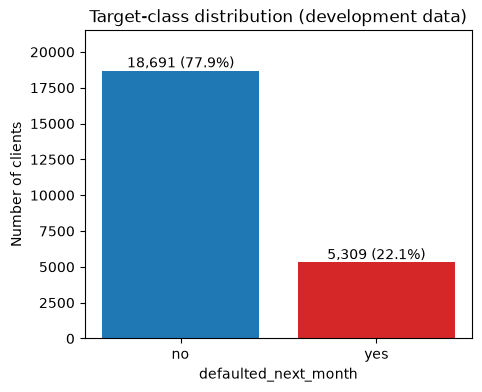

In [5]:
# Bar chart of the two classes, labelled with counts and percentages.
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(target_counts.index, target_counts.values, color=["tab:blue", "tab:red"])
ax.bar_label(bars, labels=[f"{n:,} ({p:.1%})" for n, p in zip(target_counts, target_share)])
ax.set_title("Target-class distribution (development data)")
ax.set_xlabel(TARGET)
ax.set_ylabel("Number of clients")
ax.set_ylim(0, target_counts.max() * 1.15)
save_figure(fig, "target_distribution.png")

**What the plot shows.** 18,691 clients (77.9%) did not default and 5,309 (22.1%) did.
The target has no missing values and contains only `no` and `yes`.

**Why it matters.** The classes are imbalanced. A useless model that always says `no` would score
77.9% accuracy but would find no defaulters, so its F1 for `yes` would be 0. This is why the brief
selects models by F1(yes), and why we also report precision, recall, macro-F1 and balanced accuracy.

**Modelling consequence.** Cross-validation must be *stratified*, so each fold keeps roughly 22%
defaulters. We will not resample or reweight the classes, because those techniques are not
established in the course evidence (see `docs/LECTURE_EVIDENCE.md`).

**How I would explain this in the oral exam:** About one client in five defaults. Because of this
imbalance, accuracy can look good while the model misses the clients we care about, so I select
models with F1 for the positive class and use stratified folds.

**Likely questions:**
- *What is F1(yes)?* The harmonic mean of precision and recall for `yes`: it is high only when the
  model finds many defaulters (recall) without too many false alarms (precision).
- *Why stratify?* With random folds, one fold could by chance contain fewer defaulters, which
  would make the fold scores noisier and less comparable.
- *Is 22% "severe" imbalance?* It is moderate: both classes have thousands of examples, but the
  majority-class baseline already reaches 77.9% accuracy, so accuracy alone is misleading.

### 1.3 Missing values

In [6]:
# Count missing values in every column, including the identifier and target.
missing_count = development.isna().sum()
missing_table = pd.DataFrame({
    "missing": missing_count,
    "percent": (100 * missing_count / len(development)).round(1),
})
missing_table

,missing,percent
client_id,0,0.0
credit_limit,9600,40.0
sex,9600,40.0
education,9600,40.0
marital_status,9600,40.0
age,9600,40.0
repayment_status_mar,9600,40.0
repayment_status_feb,9600,40.0
repayment_status_jan,9600,40.0
repayment_status_dec,9600,40.0


In [7]:
# Missingness per row: can we simply drop incomplete rows?
missing_per_row = development[predictor_columns].isna().sum(axis=1)
print("Rows with at least one missing predictor:", (missing_per_row > 0).sum(), "of", len(development))
print("Rows with no missing predictor:", (missing_per_row == 0).sum())
print("Missing predictors per row - min:", missing_per_row.min(),
      "median:", missing_per_row.median(), "max:", missing_per_row.max())

# Are gaps linked? If one column's gaps predicted another's, these correlations would be large.
missing_indicators = development[predictor_columns].isna().astype(int)
indicator_correlation = missing_indicators.corr().abs().to_numpy(copy=True)
np.fill_diagonal(indicator_correlation, 0)
print("Largest correlation between two columns' missing indicators:",
      indicator_correlation.max().round(3))

Rows with at least one missing predictor: 24000 of 24000
Rows with no missing predictor: 0
Missing predictors per row - min: 1 median: 9.0 max: 19
Largest correlation between two columns' missing indicators: 0.022


In [8]:
# Does a missing value tell us anything about default? Compare default rates for missing vs present.
is_default = development[TARGET] == POSITIVE_CLASS
default_rate_by_missingness = pd.DataFrame({
    "default_rate_if_missing": [is_default[development[c].isna()].mean() for c in predictor_columns],
    "default_rate_if_present": [is_default[development[c].notna()].mean() for c in predictor_columns],
}, index=predictor_columns)
default_rate_by_missingness["difference"] = (
    default_rate_by_missingness["default_rate_if_missing"]
    - default_rate_by_missingness["default_rate_if_present"]
)
print("Largest absolute difference in default rate:",
      default_rate_by_missingness["difference"].abs().max().round(3))
default_rate_by_missingness.round(3)

Largest absolute difference in default rate: 0.015


,default_rate_if_missing,default_rate_if_present,difference
credit_limit,0.219,0.223,-0.004
sex,0.223,0.220,0.004
education,0.221,0.221,-0.000
marital_status,0.215,0.225,-0.011
age,0.230,0.215,0.015
repayment_status_mar,0.223,0.220,0.004
repayment_status_feb,0.220,0.222,-0.002
repayment_status_jan,0.223,0.220,0.002
repayment_status_dec,0.221,0.221,-0.000
repayment_status_nov,0.219,0.223,-0.004


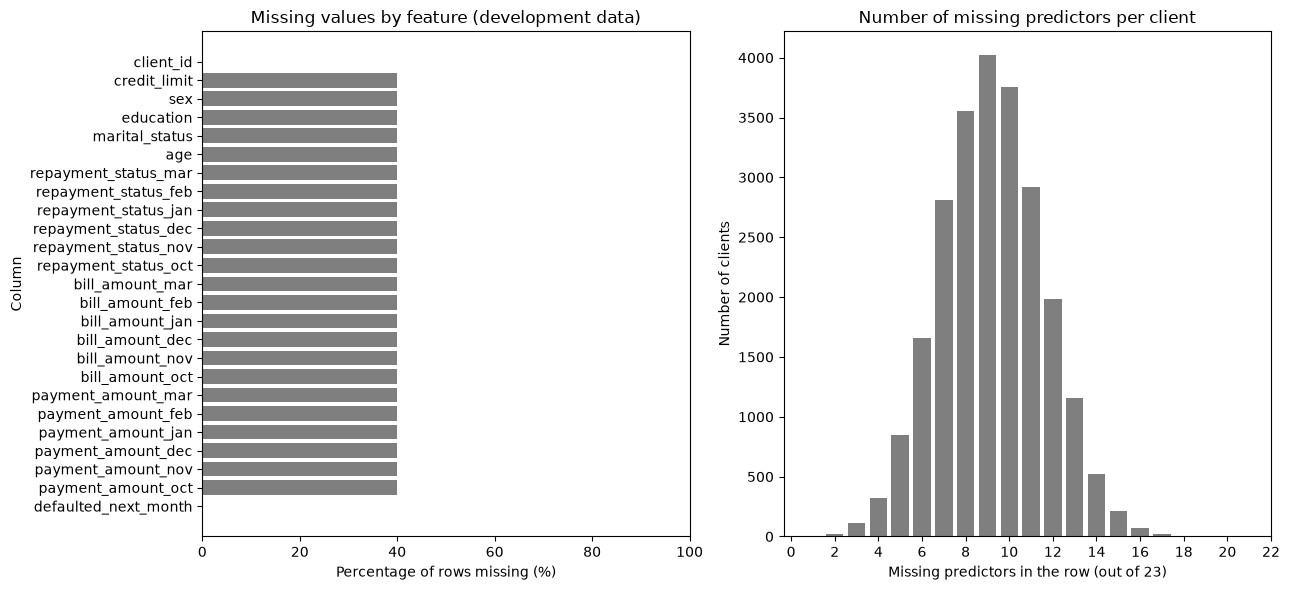

In [9]:
# Left: percentage missing per feature. Right: how many predictors are missing in each row.
fig, (ax_columns, ax_rows) = plt.subplots(1, 2, figsize=(13, 6))

ax_columns.barh(missing_table.index, missing_table["percent"], color="tab:gray")
ax_columns.invert_yaxis()
ax_columns.set_title("Missing values by feature (development data)")
ax_columns.set_xlabel("Percentage of rows missing (%)")
ax_columns.set_ylabel("Column")
ax_columns.set_xlim(0, 100)

row_counts = missing_per_row.value_counts().sort_index()
ax_rows.bar(row_counts.index, row_counts.values, color="tab:gray")
ax_rows.set_title("Number of missing predictors per client")
ax_rows.set_xlabel("Missing predictors in the row (out of 23)")
ax_rows.set_xticks(range(0, 24, 2))
ax_rows.set_ylabel("Number of clients")

fig.tight_layout()
save_figure(fig, "missingness.png")

**What the plot shows.** Every one of the 23 predictors is missing in exactly 9,600 rows (40.0%).
`client_id` and the target are complete. Every client has at least one missing predictor
(minimum 1, median 9, maximum 19 of 23), so no row is complete.

**Is the missingness informative?** These simple checks found little association. Missing
indicators in different columns are weakly correlated (largest correlation 0.022), and the default rate
changes little when a single value is missing (largest difference 0.015, i.e. 1.5 percentage points, for
`age`; most are below 0.01). This does **not** prove the gaps are random: the checks look at one column
at a time and would not detect every pattern (for example, combinations of gaps, or gaps related to
the unobserved values themselves). The identical 40% rate in every column might mean the gaps were
inserted deliberately, but that is a guess, not information from the data provider.

**Modelling consequence.**
- Dropping incomplete rows is impossible (it would delete all 24,000 rows), and dropping columns
  would delete every predictor. We must **impute**.
- Imputation statistics (mean/median for numbers, mode for categories) must be learned inside each
  training fold, as required by the brief.
- Phase 2 starts with simple median/mean and mode imputation. Because these checks found little
  association, missing indicators or a "missing" category are not the first thing to try, but the
  checks do not rule out that they could help; that could only be shown by a CV comparison.
- Note that roughly 40% of each validation fold is also imputed, so CV scores measure performance
  on incomplete inputs (see 1.6 for why this matters).

**How I would explain this in the oral exam:** Missing values are the biggest data-quality issue.
Each predictor is 40% missing and no row is complete, so I cannot delete rows; I must fill the gaps.
I checked whether a gap on its own is associated with default and found only small differences,
so simple imputation inside the pipeline is a reasonable starting point. That check does not prove
the gaps carry no information.

**Likely questions:**
- *Why not fill the gaps once, before cross-validation?* The imputer would then learn means or modes
  from the validation rows too, leaking information and making CV scores optimistic.
- *Why not use the class-specific mean taught in the lecture?* At prediction time we do not know the
  client's class, so that method cannot be applied to new clients and would leak the answer in CV.
- *Mean or median?* Bills and payments are strongly right-skewed (section 1.5), so the median is less
  affected by very large values. Phase 2 compares both rather than assuming.

### 1.4 Demographic and repayment-status categories

In [10]:
# Show every demographic label, with missing values counted explicitly.
for column in demographic_columns:
    print(development[column].fillna("(missing)").value_counts().to_string(), "\n")

sex
(missing)    9600
female       8766
male         5634 

education
(missing)          9600
university         6802
graduate_school    4994
high_school        2381
unknown             173
other                50 

marital_status
(missing)    9600
single       7699
married      6521
other         152
unknown        28 



In [11]:
# The brief's repayment-status labels, in the order used later for ordinal codes
# (delays in their natural order; the order of the first three labels is an assumption).
STATUS_ORDER = [
    "no_balance", "paid_on_time", "revolving_credit",
    "payment_delayed_1_month", "payment_delayed_2_months", "payment_delayed_3_months",
    "payment_delayed_4_months", "payment_delayed_5_months", "payment_delayed_6_months",
    "payment_delayed_7_months", "payment_delayed_8_months",
]
observed_statuses = set(development[repayment_columns].stack().dropna().unique())
print("Labels not in STATUS_ORDER:", observed_statuses - set(STATUS_ORDER) or "none")

# Count each label in each month (columns run from March back to October).
repayment_counts = pd.DataFrame({
    column.replace("repayment_status_", ""): development[column].fillna("(missing)").value_counts()
    for column in repayment_columns
}).reindex(STATUS_ORDER + ["(missing)"]).fillna(0).astype(int)
repayment_counts

Labels not in STATUS_ORDER: none


,mar,feb,jan,dec,nov,oct
no_balance,1359,1816,1954,2071,2181,2385
paid_on_time,2746,2873,2877,2743,2617,2768
revolving_credit,7002,7590,7537,7921,8165,7763
payment_delayed_1_month,1797,12,3,1,0,0
payment_delayed_2_months,1261,1871,1849,1511,1274,1330
payment_delayed_3_months,157,156,114,86,80,98
payment_delayed_4_months,40,52,35,34,41,23
payment_delayed_5_months,12,14,8,15,10,5
payment_delayed_6_months,6,7,8,2,3,6
payment_delayed_7_months,7,8,13,16,28,22


In [12]:
# Default rate for each March status: does the label order match the risk order?
march_status = development["repayment_status_mar"].fillna("(missing)")
march_summary = is_default.groupby(march_status).agg(clients="size", default_rate="mean")
march_summary = march_summary.reindex(STATUS_ORDER + ["(missing)"])
march_summary.round(3)

,clients,default_rate
repayment_status_mar,,
no_balance,1359,0.129
paid_on_time,2746,0.158
revolving_credit,7002,0.128
payment_delayed_1_month,1797,0.347
payment_delayed_2_months,1261,0.692
payment_delayed_3_months,157,0.745
payment_delayed_4_months,40,0.650
payment_delayed_5_months,12,0.500
payment_delayed_6_months,6,0.500


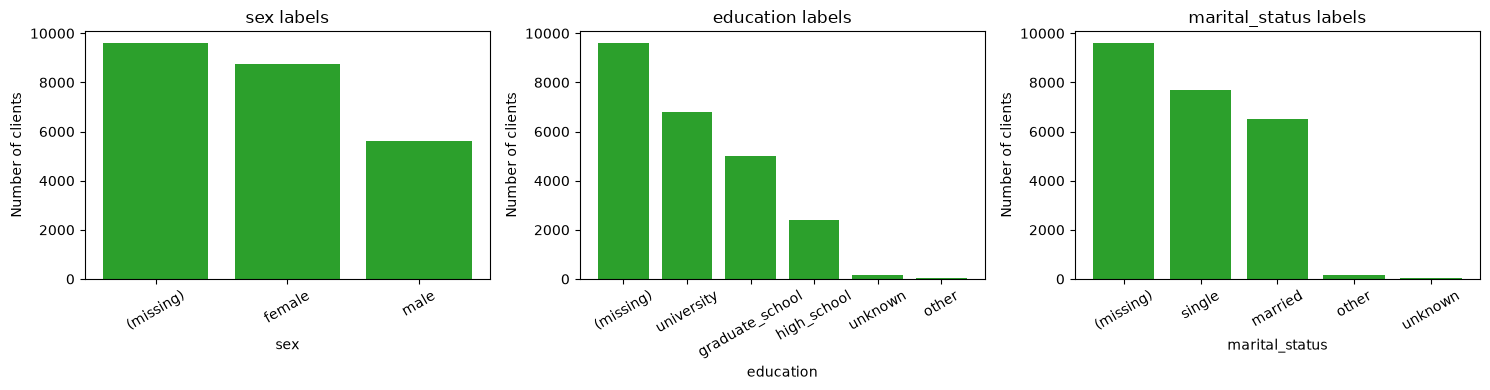

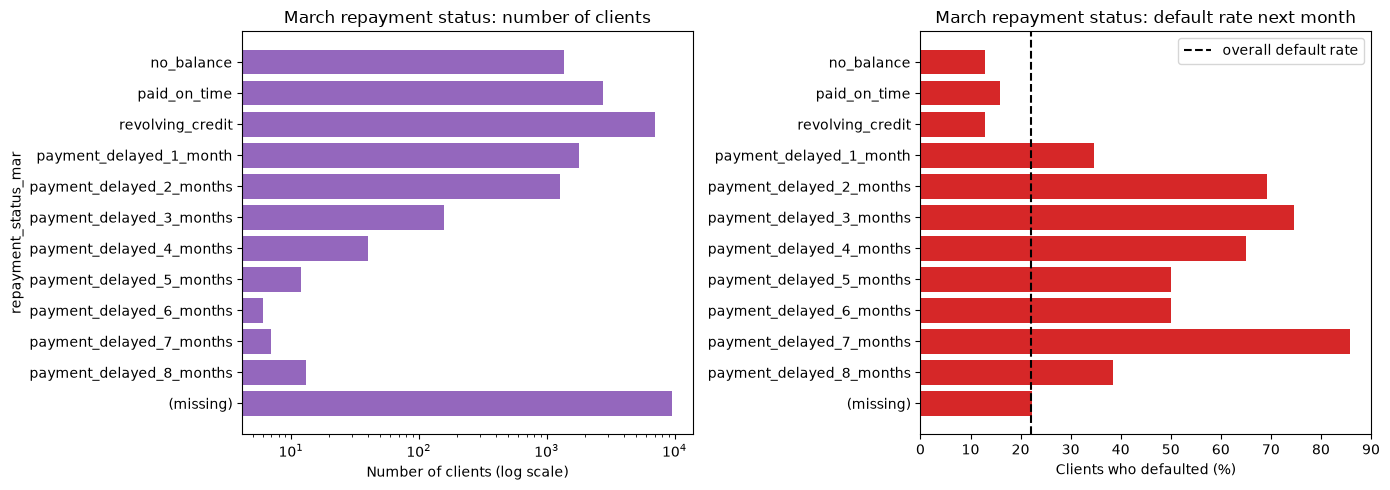

In [13]:
# Demographic label counts (missing shown as its own bar so the 40% gap stays visible).
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, demographic_columns):
    counts = development[column].fillna("(missing)").value_counts()
    ax.bar(counts.index, counts.values, color="tab:green")
    ax.set_title(f"{column} labels")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of clients")
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
save_figure(fig, "demographic_distributions.png")

# March repayment status: how common each label is, and how often those clients default.
fig, (ax_count, ax_rate) = plt.subplots(1, 2, figsize=(14, 5))
labels = march_summary.index
ax_count.barh(labels, march_summary["clients"], color="tab:purple")
ax_count.invert_yaxis()
ax_count.set_xscale("log")
ax_count.set_title("March repayment status: number of clients")
ax_count.set_xlabel("Number of clients (log scale)")
ax_count.set_ylabel("repayment_status_mar")

ax_rate.barh(labels, 100 * march_summary["default_rate"], color="tab:red")
ax_rate.invert_yaxis()
ax_rate.axvline(100 * is_default.mean(), color="black", linestyle="--", label="overall default rate")
ax_rate.set_title("March repayment status: default rate next month")
ax_rate.set_xlabel("Clients who defaulted (%)")
ax_rate.legend()
fig.tight_layout()
save_figure(fig, "repayment_status_march.png")

**What the outputs show.**
- `sex`: female 8,766, male 5,634. `education`: university 6,802, graduate_school 4,994,
  high_school 2,381, plus small `unknown` (173) and `other` (50) groups. `marital_status`: single 7,699,
  married 6,521, plus `other` (152) and `unknown` (28). Each also has 9,600 missing values.
- `unknown` is a **recorded label**, different from a missing value (`NaN`). We keep it as given
  rather than merging it with missing values, because we do not know how the provider created it.
- The repayment-status labels are exactly those described in the brief (no unexpected spellings).
  Most clients are `revolving_credit`, `paid_on_time` or `no_balance`. Delays of 3+ months are rare
  (for example only 6-13 March clients in each of the 5-8 month groups).
- **Surprising pattern:** `payment_delayed_1_month` appears 1,797 times in March but only
  0-12 times in each earlier month. The earlier months seem to use the other labels instead.
  We record this rather than "correcting" it; it means the six monthly columns may not use labels
  in exactly the same way.

**Default-rate plot.** The overall default rate is 22.1% (dashed line). In March, clients with
`no_balance` (12.9%), `revolving_credit` (12.8%) and `paid_on_time` (15.8%) default less often, while
`payment_delayed_1_month` reaches 34.7% and `payment_delayed_2_months` 69.2%. The rare 5-8 month groups
have unstable rates (for example 38.5% for 8 months, from only 13 clients), so their estimates are noisy.
Missing March status has the overall rate (22.3%), matching section 1.3.

**Modelling consequence (ordinal vs categorical, asked in the brief p.2).** The delay labels have a
natural order and risk generally rises from 0 to 2-3 months of delay, which supports an ordinal encoding.
However, the three non-delay labels do not have an obvious order and their risk is not monotonic
(`paid_on_time` is slightly riskier than `revolving_credit`). One-hot encoding avoids imposing an order.
Phase 2 will compare one-hot encoding with a documented ordinal mapping using CV, instead of deciding now.
Rare labels can be missing from a CV training fold, so the encoder must tolerate unseen labels.

**How I would explain this in the oral exam:** I listed every label to make sure there were no typos
and to see which groups are rare. Repayment status is clearly related to default: delayed clients
default much more often. Because the delays are ordered but the three non-delay labels are not clearly
ordered, I will test both one-hot and ordinal encoding rather than assume one.

**Likely questions:**
- *Why not treat `unknown` as missing?* It is an explicit label in the file, and merging it with
  missing values would be an assumption; it is also small, so the choice has little effect.
- *What is the risk of ordinal encoding?* It tells distance-based models that adjacent codes are
  "close", which is only appropriate if the order and spacing are meaningful.
- *Why are the 5-8 month default rates erratic?* They come from 6-13 clients each, so one client
  changes the rate by several percentage points; they should not drive conclusions.

### 1.5 Duplicates and suspicious numeric values

In [14]:
# An identifier should appear once; identical rows (apart from the ID) could signal copied records.
print("Duplicate client_id values:", development[ID_COLUMN].duplicated().sum())
print("Duplicate rows when client_id is ignored:", development.drop(columns=ID_COLUMN).duplicated().sum())
print("client_id range:", development[ID_COLUMN].min(), "to", development[ID_COLUMN].max())

Duplicate client_id values: 0
Duplicate rows when client_id is ignored: 0
client_id range: 1 to 30000


In [15]:
# Summary of the observed (non-missing) numeric values, with the 1st and 99th percentiles.
development[numeric_columns].describe(percentiles=[0.01, 0.5, 0.99]).T.round(0)

,count,mean,std,min,1%,50%,99%,max
credit_limit,14400.0,166952.0,129539.0,10000.0,10000.0,140000.0,500000.0,1000000.0
age,14400.0,35.0,9.0,21.0,22.0,34.0,60.0,74.0
bill_amount_mar,14400.0,51837.0,74669.0,-165580.0,-109.0,22750.0,355346.0,964511.0
bill_amount_feb,14400.0,48705.0,70470.0,-33350.0,-150.0,21212.0,329179.0,983931.0
bill_amount_jan,14400.0,46615.0,67597.0,-61506.0,-180.0,20012.0,321020.0,693131.0
bill_amount_dec,14400.0,43316.0,64444.0,-81334.0,-212.0,19134.0,306083.0,891586.0
bill_amount_nov,14400.0,39779.0,59579.0,-81334.0,-222.0,18225.0,283437.0,530672.0
bill_amount_oct,14400.0,38926.0,59501.0,-73895.0,-371.0,16971.0,284598.0,568638.0
payment_amount_mar,14400.0,5574.0,14974.0,0.0,0.0,2100.0,65669.0,423903.0
payment_amount_feb,14400.0,5901.0,19749.0,0.0,0.0,2014.0,79192.0,1024516.0


In [16]:
# Count negatives, zeros and fractional values in each numeric column (missing values are not counted).
numeric_values = development[numeric_columns]
value_checks = pd.DataFrame({
    "negative": (numeric_values < 0).sum(),
    "zero": (numeric_values == 0).sum(),
    "non_whole_number": (numeric_values % 1 > 0).sum(),
})
print("Age range:", development["age"].min(), "to", development["age"].max())
print("Distinct credit limits:", development["credit_limit"].nunique(),
      "| smallest:", sorted(development["credit_limit"].dropna().unique())[:4])
value_checks

Age range: 21.0 to 74.0
Distinct credit limits: 78 | smallest: [np.float64(10000.0), np.float64(16000.0), np.float64(20000.0), np.float64(30000.0)]


,negative,zero,non_whole_number
credit_limit,0,0,0
age,0,0,0
bill_amount_mar,287,946,0
bill_amount_feb,307,1182,0
bill_amount_jan,296,1443,0
bill_amount_dec,323,1534,0
bill_amount_nov,325,1668,0
bill_amount_oct,352,1916,0
payment_amount_mar,0,2482,0
payment_amount_feb,0,2583,0


In [17]:
# Negative bills: how many, and what repayment status is recorded in the same month?
negative_bill = development[bill_columns] < 0
client_has_negative_bill = negative_bill.any(axis=1)
print("Observed negative bill values (individual monthly amounts):", negative_bill.sum().sum())
print("Clients with at least one observed negative bill:", client_has_negative_bill.sum())
print("Observed bill values below -50,000:", (development[bill_columns] < -50000).sum().sum())
# "No observed negative bill" includes clients whose missing bills might have been negative.
print("Default rate, clients with >= 1 observed negative bill:",
      is_default[client_has_negative_bill].mean().round(3),
      "| clients with none observed:", is_default[~client_has_negative_bill].mean().round(3))

# Compare the March status label with the sign of the March bill.
march_bill_sign = np.sign(development["bill_amount_mar"]).map({-1: "negative", 0: "zero", 1: "positive"})
pd.crosstab(development["repayment_status_mar"], march_bill_sign).reindex(STATUS_ORDER)

Observed negative bill values (individual monthly amounts): 1890
Clients with at least one observed negative bill: 1166
Observed bill values below -50,000: 7
Default rate, clients with >= 1 observed negative bill: 0.166 | clients with none observed: 0.224


bill_amount_mar,negative,positive,zero
repayment_status_mar,,,
no_balance,62,546,182
paid_on_time,2,1658,1
revolving_credit,0,4190,0
payment_delayed_1_month,103,584,382
payment_delayed_2_months,0,775,0
payment_delayed_3_months,0,98,0
payment_delayed_4_months,0,22,0
payment_delayed_5_months,0,8,0
payment_delayed_6_months,0,6,0


In [18]:
# A bill above the credit limit is possible (interest, fees, over-limit spending) but worth counting.
highest_bill = development[bill_columns].max(axis=1)
print("Clients whose highest observed bill exceeds their observed credit limit:",
      (highest_bill > development["credit_limit"]).sum())

# The most extreme negative bill, shown with that client's other amounts.
most_negative_row = development["bill_amount_mar"].idxmin()
development.loc[most_negative_row, ["credit_limit"] + bill_columns + ["repayment_status_mar"]]

Clients whose highest observed bill exceeds their observed credit limit: 1415


credit_limit            300000.0
bill_amount_mar        -165580.0
bill_amount_feb         324392.0
bill_amount_jan         296931.0
bill_amount_dec          30355.0
bill_amount_nov          26771.0
bill_amount_oct              NaN
repayment_status_mar         NaN
Name: 6861, dtype: object

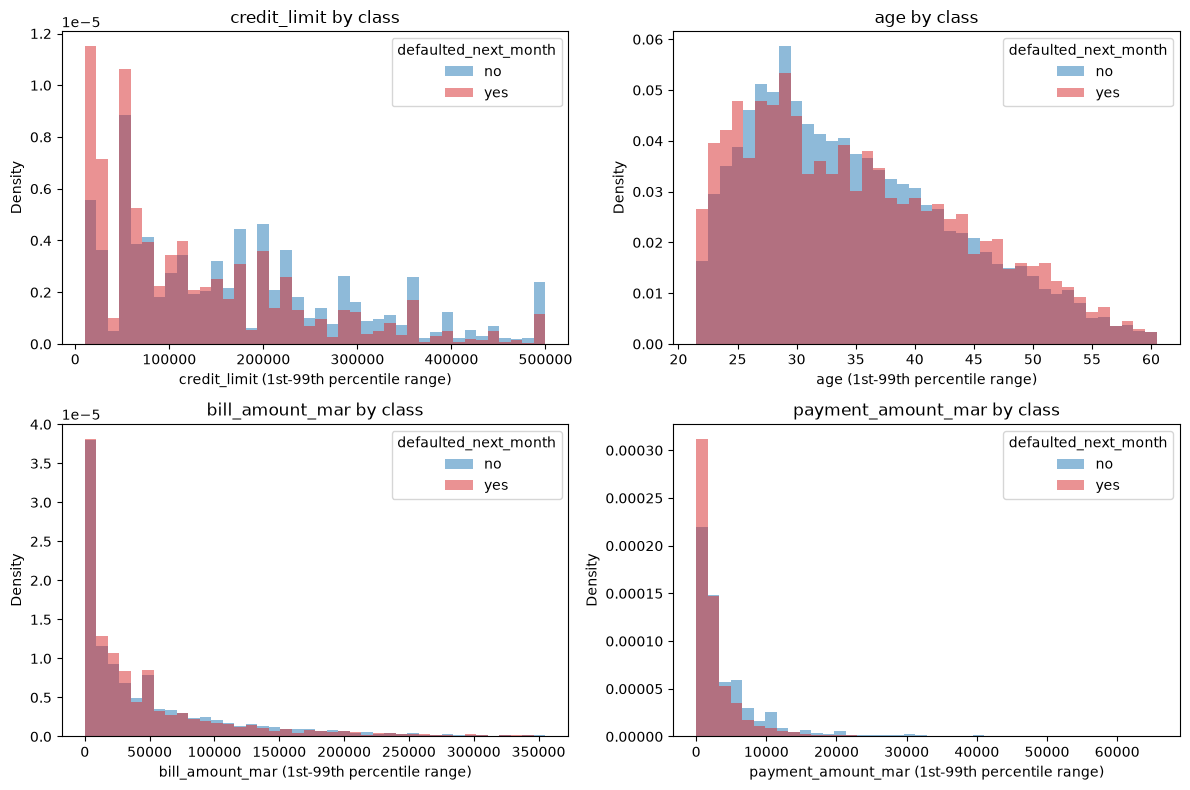

In [19]:
def percentile_bin_edges(column, n_bins=40):
    """Equal-width bins over the 1st-99th percentile, so a few huge values do not squash the plot."""
    low, high = development[column].quantile([0.01, 0.99])
    return np.linspace(low, high, n_bins + 1)


def plot_numeric_by_class(ax, column, bin_edges):
    """Overlay the defaulter and non-defaulter histograms for one numeric column."""
    for label, colour in [("no", "tab:blue"), ("yes", "tab:red")]:
        values = development.loc[development[TARGET] == label, column].dropna()
        ax.hist(values, bins=bin_edges, density=True, alpha=0.5, color=colour, label=label)
    ax.set_title(f"{column} by class")
    ax.set_xlabel(f"{column} (1st-99th percentile range)")
    ax.set_ylabel("Density")
    ax.legend(title=TARGET)


# Ages are whole numbers, so edges at 21.5, 22.5, ... give every age (22 to 60) its own bar.
age_low, age_high = development["age"].quantile([0.01, 0.99])
bin_edges_per_column = {
    "credit_limit": percentile_bin_edges("credit_limit"),
    "age": np.arange(age_low - 0.5, age_high + 1.0),
    "bill_amount_mar": percentile_bin_edges("bill_amount_mar"),
    "payment_amount_mar": percentile_bin_edges("payment_amount_mar"),
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (column, bin_edges) in zip(axes.ravel(), bin_edges_per_column.items()):
    plot_numeric_by_class(ax, column, bin_edges)
fig.tight_layout()
save_figure(fig, "numeric_distributions.png")

**Duplicates.** There are no duplicate `client_id` values and no duplicate rows (even ignoring the ID),
so no records need to be removed.

**Suspicious values investigated (none deleted or changed).**
- All numeric values are whole numbers. Age runs from 21 to 74 and credit limits from 10,000 to
  1,000,000 (78 distinct values, mostly multiples of 10,000): plausible.
- **Negative bills:** there are 1,890 observed negative bill *values* (about 2.0-2.4% of observed
  bills per month). They belong to 1,166 *clients* who have at least one observed negative bill (some
  clients have several). Most are small (the 1st percentile is only about -100 to -370); only 7 values
  are below -50,000. One possible reading is that the client is in credit, for example after
  overpaying or receiving a refund. The brief does not define negative bills, so this interpretation is
  tentative, and negative values are not automatically errors. Clients with at least one observed
  negative bill default less often (16.6%) than clients with none observed (22.4%); this is compatible
  with the credit-balance reading but does not confirm it. The most extreme value (-165,580 in March)
  belongs to a client whose February and January bills were about 300,000; it could be a large refund
  or a recording error, and we cannot tell which, so it is kept.
- **Bills above the credit limit:** 1,415 clients have an observed bill above their observed credit
  limit. Interest, fees or over-limit spending could explain this, but that is also tentative; it is kept.
- **Labels versus amounts:** 546 March `no_balance` clients still have a positive March bill, and
  `payment_delayed_1_month` occurs with negative (103) or zero (382) bills. So the status labels do not
  map neatly onto the bill amount. This is recorded as a data-meaning uncertainty, not "fixed".
- Payments of 0 are common (about 17-24% of observed values per month), and very large payments exist
  (maximum 1,024,516 in February). Payment amounts are extremely right-skewed (pandas skewness above 10).

**What the numeric plot shows.** Histograms are scaled to density so the smaller `yes` group can be
compared with `no`. Defaulters are concentrated at lower credit limits (below about 60,000). The age distributions are
broadly similar, with slightly more defaulters among the youngest clients. The bill and payment plots
show strong right skew, with most values close to zero. March bills look similar for both classes,
while defaulters have relatively more March payments near zero.

**Modelling consequence.**
- Keep negative and extreme values: we cannot show they are errors, and every test client needs a
  prediction anyway.
- Trees generally do not need scaling, because each split compares one feature with a threshold and
  rescaling a feature keeps the same possible splits. Unusual values can still matter for trees:
  a few extreme clients can be isolated in small leaves, and with **mean** imputation they shift the
  value used to fill gaps. The Phase 2 mean-versus-median comparison tests that second effect.
- k-NN uses distances, so features measured in hundreds of thousands (bills) would dominate age unless
  we **scale** inside the pipeline. The skew also means extreme clients can sit far from everyone else.
- Gaussian naive Bayes assumes bell-shaped numeric features within each class; these skewed amounts
  violate that assumption, which may limit its performance. This is recorded as a limitation.

**How I would explain this in the oral exam:** I checked for duplicate clients and impossible values.
The main unusual values were negative bills and bills above the limit. Both have possible
financial explanations, but I cannot confirm them, so I kept the values rather than guess they are errors. The large, skewed amounts are mainly an issue for distance-based
k-NN, which is why scaling is part of that pipeline.

**Likely questions:**
- *Why not remove outliers?* They may be genuine clients, the test set will contain similar clients
  who still need predictions, and outlier removal is not part of the supported starting workflow.
- *Why does scaling matter for k-NN but not trees?* k-NN adds up feature differences in a distance, so
  large-unit features dominate; a tree compares one feature with a threshold, so rescaling it does not
  change which split is possible.
- *Why plot densities instead of counts?* There are about 3.5 times more `no` clients, so counts would
  hide the shape of the `yes` distribution.

### 1.6 Test-file input contract

In [20]:
# Only structural checks: we need the test file to be usable, not to learn from it.
expected_test_columns = [c for c in development.columns if c != TARGET]
print("Test shape (rows, columns):", test.shape)
print("Same columns in the same order as development minus the target:",
      list(test.columns) == expected_test_columns)
print("Target column absent from test:", TARGET not in test.columns)
print("Duplicate test client_id values:", test[ID_COLUMN].duplicated().sum())
print("Test client_id values also present in development:", test[ID_COLUMN].isin(development[ID_COLUMN]).sum())
print("Total missing values in test:", test.isna().sum().sum())

# Text labels in test that never appear in the same development column.
for column in demographic_columns + repayment_columns:
    unseen_labels = set(test[column].dropna()) - set(development[column].dropna())
    if unseen_labels:
        print("Label in test but not in development", column, "->", unseen_labels)

Test shape (rows, columns): (6000, 24)
Same columns in the same order as development minus the target: True
Target column absent from test: True
Duplicate test client_id values: 0
Test client_id values also present in development: 0
Total missing values in test: 0
Label in test but not in development repayment_status_dec -> {'payment_delayed_8_months'}
Label in test but not in development repayment_status_oct -> {'payment_delayed_8_months'}


In [21]:
# Columns whose stored type differs between the files.
dtype_comparison = pd.DataFrame({
    "development": development[expected_test_columns].dtypes.astype(str),
    "test": test.dtypes.astype(str),
})
dtype_comparison[dtype_comparison["development"] != dtype_comparison["test"]]

,development,test
credit_limit,float64,int64
age,float64,int64
bill_amount_mar,float64,int64
bill_amount_feb,float64,int64
bill_amount_jan,float64,int64
bill_amount_dec,float64,int64
bill_amount_nov,float64,int64
bill_amount_oct,float64,int64
payment_amount_mar,float64,int64
payment_amount_feb,float64,int64


**What this shows.** `test.csv` has 6,000 rows and 24 columns, with the same column names in the same
order as development minus the target. The target is absent, client IDs are unique and none overlap
with development. All category labels in test also appear somewhere in development, but
`payment_delayed_8_months` appears in the test `repayment_status_dec` and `repayment_status_oct` columns
even though no development row has that label in those two months.

**An unexpected structural difference.** The test file contains **no missing values**, so its numeric
columns are read as `int64` instead of `float64`. Development predictors are 40% missing.
This is reported as an input fact. It is *not* used to choose methods: we will still select
imputation, encoding and models using development CV only, as the brief requires (p.3).

**Modelling consequence.**
- The final pipeline must accept integer columns and complete rows; imputers do this without change.
- The encoder must not fail on a label unseen during fitting (for example one-hot with
  `handle_unknown="ignore"`, or an ordinal mapping that already lists all labels from the brief).
- CV folds contain about 40% imputed values, but test rows are complete, so CV scores may not predict
  the hidden-test score closely. This is a limitation to state in the README, not a reason to tune on test.

**How I would explain this in the oral exam:** I checked that the test file has the right columns,
6,000 rows and no target, so the final program can predict every row in order. I noticed the test file
is complete while development has many gaps; I noted this but did not use the test file to make choices.

**Likely questions:**
- *Why not tune using the test file?* Its labels are hidden, and the brief requires all choices to come
  from development data; using its distribution would also be a form of test-set leakage.
- *Why does an unseen label matter?* A one-hot encoder fitted on training data has no column for a new
  label and, by default, raises an error at prediction time.
- *Does the missing-value difference change the plan?* Not the selection procedure. It does mean the
  CV estimate is an approximation of the hidden-test result.

### 1.7 Audit summary and decisions for Phase 2

| Finding | Effect on the plan |
|---|---|
| 24,000 rows; 14 numeric, 9 text predictors; `client_id` excluded | Separate numeric and categorical branches in a `ColumnTransformer` |
| 22.1% `yes` | Stratified 5-fold CV; select by F1(yes); accuracy reported but not used to select |
| Every predictor 40% missing; no complete row; little association with default in simple checks | Impute inside folds; compare mean vs median (numeric), mode for categories |
| Repayment labels ordered for delays, unclear for non-delay labels | Compare one-hot vs a documented ordinal mapping |
| Rare labels; unseen test label | Encoder must handle unseen labels |
| Negative bills, bills above limit, extreme payments | Kept unchanged; scale for k-NN; trees unscaled |
| No duplicates | Nothing removed |
| Test complete, development 40% missing | Stated as a limitation; not used for selection |

Nothing was removed or modified in this phase. Next: Phase 2, a first baseline pipeline and small
preprocessing comparisons on the same stratified folds.

## Phase 2 — first baseline and numeric imputation

This phase builds the first baseline and compares mean and median numeric imputation. Repayment-status encoding
is compared in Phase 2b, and the other three classifiers in Phase 3.

Plan for this section:
1. Separate the predictors from the target and drop `client_id`.
2. Define one set of five stratified folds and reuse it for every comparison.
3. Build the preprocessing inside a `Pipeline`, so it is re-fitted on each training fold only.
4. Score one simple decision tree with median imputation (the baseline).
5. Change **only** the numeric imputation statistic to the mean and compare on the same folds.

In [22]:
# Phase 2 setup: scikit-learn tools for preprocessing pipelines and cross-validation.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

# Predictors exclude client_id (an identifier) and the target itself.
X = development[predictor_columns]
y = development[TARGET]
categorical_columns = demographic_columns + repayment_columns
print("X shape:", X.shape, "| client_id in X:", ID_COLUMN in X.columns, "| target in X:", TARGET in X.columns)

# One fixed set of folds; with an integer random_state, every call to split() gives the same folds.
cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# The six reported metrics; "yes" is the positive class for precision, recall and F1.
scoring = {
    "accuracy": "accuracy",
    "precision_yes": make_scorer(precision_score, pos_label=POSITIVE_CLASS),
    "recall_yes": make_scorer(recall_score, pos_label=POSITIVE_CLASS),
    "f1_yes": make_scorer(f1_score, pos_label=POSITIVE_CLASS),
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
}

X shape: (24000, 23) | client_id in X: False | target in X: False


In [23]:
# Check the stratification: each validation fold should hold about 22.1% "yes".
fold_rows = []
for fold_number, (train_index, valid_index) in enumerate(cv_folds.split(X, y), start=1):
    fold_rows.append({
        "fold": fold_number,
        "train_rows": len(train_index),
        "validation_rows": len(valid_index),
        "validation_yes_share": (y.iloc[valid_index] == POSITIVE_CLASS).mean().round(3),
    })
pd.DataFrame(fold_rows)

,fold,train_rows,validation_rows,validation_yes_share
0,1,19200,4800,0.221
1,2,19200,4800,0.221
2,3,19200,4800,0.221
3,4,19200,4800,0.221
4,5,19200,4800,0.221


**What this does.** `X` holds the 23 predictors and `y` the target; `client_id` is not in `X`. The five
folds each validate on 4,800 clients and train on the other 19,200. Each validation fold has a `yes`
share of 0.221 (the overall rate), which is what stratification should achieve. Because the splitter
has a fixed integer seed, every later `cross_validate` call uses exactly the same five folds.
Precision, recall and F1 are computed for the positive class `yes`, not averaged over both classes.

**How I would explain this in the oral exam:** I split the labelled data into five stratified folds
once, with seed 42, and reuse them for every comparison. Each model is trained five times, each time
validated on the fold it did not see. Using the same folds means differences between pipelines are not
caused by different random splits.

**Likely questions:**
- *Why does `random_state=42` matter here?* With shuffling, the folds depend on the random seed; fixing
  it makes the folds, and therefore the scores, reproducible and identical across comparisons.
- *Why define custom scorers?* The built-in `"f1"` scorer assumes the positive label is `1`; our labels
  are strings, so we tell scikit-learn that `"yes"` is positive.
- *Why is accuracy in the list if we do not select with it?* The brief requires reporting it; it is
  useful context but misleading on its own with 22% positives.

In [24]:
def make_preprocessor(numeric_strategy):
    """Impute numbers with the given statistic; impute categories with the mode, then one-hot encode."""
    categorical_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        # Unseen labels (e.g. a rare status missing from a training fold) become all-zero columns.
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy=numeric_strategy), numeric_columns),
        ("categorical", categorical_steps, categorical_columns),
    ])


def make_tree_pipeline(numeric_strategy):
    """Preprocessing followed by one small decision tree with fixed, documented settings."""
    tree = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=RANDOM_STATE)
    return Pipeline([
        ("preprocess", make_preprocessor(numeric_strategy)),
        ("model", tree),
    ])


def evaluate_pipeline(pipeline):
    """Fit on each training fold, score on its validation fold; one row of scores per fold."""
    results = cross_validate(pipeline, X, y, cv=cv_folds, scoring=scoring)
    fold_scores = pd.DataFrame({metric: results[f"test_{metric}"] for metric in scoring})
    fold_scores.index = pd.RangeIndex(1, len(fold_scores) + 1, name="fold")
    return fold_scores


def summarise(fold_scores):
    """Mean and sample standard deviation (ddof=1) of each metric over the five folds."""
    return fold_scores.agg(["mean", "std"]).T.round(3)

In [25]:
# Illustration only: fit the preprocessor on the first training fold to see what the tree receives.
first_train_index, _ = next(cv_folds.split(X, y))
example_preprocessor = make_preprocessor("median").fit(X.iloc[first_train_index])
encoded_feature_names = example_preprocessor.get_feature_names_out()
print("Columns after preprocessing:", len(encoded_feature_names))
print("Numeric columns kept as numbers:", len(numeric_columns))
print("One-hot columns from 9 categorical features:", len(encoded_feature_names) - len(numeric_columns))
print("Example one-hot names:", list(encoded_feature_names[len(numeric_columns):len(numeric_columns) + 4]))

Columns after preprocessing: 86
Numeric columns kept as numbers: 14
One-hot columns from 9 categorical features: 72
Example one-hot names: ['categorical__sex_female', 'categorical__sex_male', 'categorical__education_graduate_school', 'categorical__education_high_school']


**What this does.** `make_preprocessor` sends the 14 numeric columns to a `SimpleImputer` and the
9 categorical columns to mode imputation followed by one-hot encoding. Fitted on one training fold,
this produces 86 columns: the 14 numbers plus 72 one-hot indicator columns. `cross_validate` re-fits the
whole pipeline, imputer and encoder included, on each training fold, so the medians, modes and category
lists are never learned from the validation fold.

**Decision-tree settings (fixed, not tuned).**
- `criterion="gini"`: Gini impurity, one of the splitting measures in L3 p.20 (also scikit-learn's default).
- `max_depth=5`: at most five questions from root to leaf. This is pre-pruning (L3 pp.62-67): a fully grown
  tree can memorise the training fold. Depth 5 is a readable starting value chosen before seeing any
  scores; it is not claimed to be the best depth. Tuning comes later.
- `random_state=42`: ties between equally good splits are broken reproducibly.
- All other settings are scikit-learn defaults (for example `min_samples_leaf=1`). No scaling is used,
  because tree splits do not depend on feature units.

**How I would explain this in the oral exam:** The pipeline is a recipe: fill numeric gaps with the
median, fill categorical gaps with the most common label, turn labels into 0/1 columns, then fit a
depth-5 tree. Because the recipe is inside the pipeline, cross-validation re-learns it on every training
fold, so no validation information leaks into the preprocessing.

**Likely questions:**
- *What does `handle_unknown="ignore"` do?* If a label appears that was not seen when the encoder was
  fitted, all of that feature's one-hot columns are 0 instead of raising an error. This matters for rare
  repayment labels and the test-only `payment_delayed_8_months` label in two months.
- *Why one-hot and not label codes?* Integer codes would impose an arbitrary order on categories;
  one-hot avoids that. An ordinal encoding for repayment status is a later comparison.
- *Why fit the preprocessor in the illustration on a training fold, not on all data?* To keep the habit
  of only learning from training rows; the illustration does not affect any score.

In [26]:
# Baseline: median imputation for numeric features, decision tree with max_depth=5.
median_fold_scores = evaluate_pipeline(make_tree_pipeline("median"))
print("Held-out score in each fold (median imputation):")
print(median_fold_scores.round(3))
print()
print("Mean and standard deviation over the 5 folds:")
summarise(median_fold_scores)

Held-out score in each fold (median imputation):
      accuracy  precision_yes  recall_yes  f1_yes  macro_f1  balanced_accuracy
fold                                                                          
1        0.804          0.630       0.272   0.380     0.632              0.613
2        0.805          0.670       0.235   0.348     0.617              0.601
3        0.802          0.613       0.284   0.388     0.635              0.617
4        0.797          0.587       0.277   0.376     0.627              0.611
5        0.804          0.647       0.253   0.364     0.624              0.607

Mean and standard deviation over the 5 folds:


,mean,std
accuracy,0.802,0.003
precision_yes,0.629,0.032
recall_yes,0.264,0.020
f1_yes,0.371,0.016
macro_f1,0.627,0.007
balanced_accuracy,0.610,0.006


**Measured baseline (held-out folds, mean +/- sample std).** Accuracy 0.802 +/- 0.003, precision(yes)
0.629 +/- 0.032, recall(yes) 0.264 +/- 0.020, **F1(yes) 0.371 +/- 0.016**, macro-F1 0.627 +/- 0.007,
balanced accuracy 0.610 +/- 0.006.

**Interpretation.** Accuracy (0.802) is only slightly above the 0.779 obtained by always predicting
`no`. When this tree predicts `yes` it is right about 63% of the time, but it finds only about 26% of the
actual defaulters, so F1(yes) is low. This is a reference point for later comparisons, not a good final
model: it is well below the 0.55 F1 level mentioned in the brief's marking ladder (and CV F1 is not the
hidden-test F1 anyway).

**How I would explain this in the oral exam:** The first tree is cautious: it labels relatively few
clients as defaulters, so its precision is reasonable but its recall is low, giving F1(yes) of about 0.37.
The fold standard deviations show how much the score moves between different validation sets.

**Likely questions:**
- *Why is accuracy 0.80 but F1(yes) only 0.37?* Accuracy is dominated by the many `no` clients that are
  easy to classify correctly; F1(yes) only looks at how well defaulters are found.
- *What does the standard deviation mean here?* It is the sample standard deviation of the five fold
  scores; it shows variation across validation sets, not a confidence interval or significance test.
- *Why might recall be low?* A depth-5 tree has few leaves, and a leaf predicts `yes` only when most of
  its training clients defaulted. This is a hypothesis for later experiments, not a measured result.

In [27]:
# Controlled comparison: identical model and folds; only the numeric imputation statistic changes.
mean_fold_scores = evaluate_pipeline(make_tree_pipeline("mean"))
print("Held-out score in each fold (mean imputation):")
print(mean_fold_scores.round(3))

imputation_comparison = pd.concat(
    {"median": summarise(median_fold_scores), "mean": summarise(mean_fold_scores)}, axis=1
)
imputation_comparison

Held-out score in each fold (mean imputation):
      accuracy  precision_yes  recall_yes  f1_yes  macro_f1  balanced_accuracy
fold                                                                          
1        0.805          0.629       0.282   0.389     0.637              0.617
2        0.800          0.655       0.207   0.315     0.599              0.588
3        0.803          0.624       0.277   0.384     0.633              0.615
4        0.799          0.595       0.283   0.384     0.632              0.614
5        0.803          0.644       0.246   0.356     0.620              0.604


median          mean       
                    mean    std   mean    std
accuracy           0.802  0.003  0.802  0.002
precision_yes      0.629  0.032  0.630  0.023
recall_yes         0.264  0.020  0.259  0.033
f1_yes             0.371  0.016  0.365  0.031
macro_f1           0.627  0.007  0.624  0.015
balanced_accuracy  0.610  0.006  0.608  0.012

In [28]:
# Same folds, so compare fold by fold: positive values mean "mean imputation scored higher".
f1_difference = mean_fold_scores["f1_yes"] - median_fold_scores["f1_yes"]
print("F1(yes) difference per fold (mean - median):", f1_difference.round(3).tolist())
print("Average difference:", round(f1_difference.mean(), 3),
      "| folds where median was higher:", (f1_difference < 0).sum(), "of", len(f1_difference))

F1(yes) difference per fold (mean - median): [0.009, -0.034, -0.005, 0.008, -0.008]
Average difference: -0.006 | folds where median was higher: 3 of 5


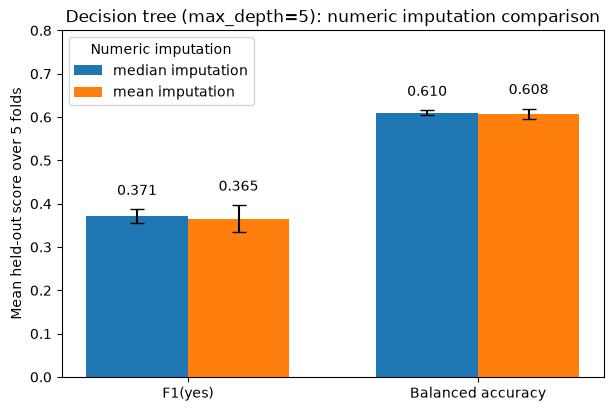

In [29]:
# Bar chart of F1(yes) and balanced accuracy, with error bars showing +/- 1 fold standard deviation.
plot_metrics = ["f1_yes", "balanced_accuracy"]
bar_width = 0.35
positions = np.arange(len(plot_metrics))

fig, ax = plt.subplots(figsize=(7, 4.5))
for offset, (name, fold_scores) in zip([-bar_width / 2, bar_width / 2],
                                       [("median", median_fold_scores), ("mean", mean_fold_scores)]):
    bars = ax.bar(positions + offset, fold_scores[plot_metrics].mean(), bar_width,
                  yerr=fold_scores[plot_metrics].std(), capsize=5, label=f"{name} imputation")
    ax.bar_label(bars, fmt="%.3f", padding=8)
ax.set_xticks(positions, ["F1(yes)", "Balanced accuracy"])
ax.set_ylim(0, 0.8)
ax.set_ylabel("Mean held-out score over 5 folds")
ax.set_title("Decision tree (max_depth=5): numeric imputation comparison")
ax.legend(title="Numeric imputation")
save_figure(fig, "baseline_imputation_comparison.png")

**Measured comparison (same tree, same folds).**

| Numeric imputation | F1(yes) | Balanced accuracy | Precision(yes) | Recall(yes) | Accuracy | Macro-F1 |
|---|---|---|---|---|---|---|
| Median | 0.371 +/- 0.016 | 0.610 +/- 0.006 | 0.629 +/- 0.032 | 0.264 +/- 0.020 | 0.802 +/- 0.003 | 0.627 +/- 0.007 |
| Mean | 0.365 +/- 0.031 | 0.608 +/- 0.012 | 0.630 +/- 0.023 | 0.259 +/- 0.033 | 0.802 +/- 0.002 | 0.624 +/- 0.015 |

The plot shows the F1(yes) and balanced-accuracy means with +/- 1 standard-deviation error bars.
Median imputation has a slightly higher mean F1(yes), by 0.006. Fold by fold, median was higher in
3 of 5 folds; the largest single gap is fold 2, where mean imputation dropped to 0.315 (versus 0.348);
without that fold, mean imputation would be slightly ahead. The difference
is small compared with the fold-to-fold variation, so this run does **not** show that median is
genuinely better; the two choices perform similarly with this tree.

**Decision.** Keep **median imputation** for the numeric features in the next steps. Reasons, in order:
it has the (slightly) higher mean F1(yes), its fold scores vary less (std 0.016 versus 0.031), and
it is less influenced by the very large bill and payment values found in Phase 1. The two options are
equally simple, so simplicity does not separate them. This choice was made on development CV only, and
it may be revisited for k-NN and naive Bayes, which use the numeric values differently from a tree.

**How I would explain this in the oral exam:** I changed one thing, the numeric imputation statistic,
and kept the model and folds the same, so any difference comes from that change. The scores were very
close; I kept the median because it scored slightly higher and more consistently and is robust to the
skewed amounts, but I would not claim it is significantly better.

**Likely questions:**
- *Why compare on the same folds?* Then both pipelines face identical training and validation clients,
  and fold-by-fold differences isolate the effect of the imputation choice.
- *Is a 0.006 difference meaningful?* Not on this evidence: it is smaller than the fold standard
  deviations, and one fold accounts for most of it. Std alone is not a significance test either.
- *Why could mean and median differ for a tree?* The fill value decides which side of a split the
  imputed clients fall on. Skewed amounts pull the mean far above the median, so imputed clients look
  like higher-bill clients under mean imputation.

## Phase 2b — repayment-status encoding: one-hot versus ordinal

The brief (p.2) asks whether repayment status is best treated as
ordinal or categorical. This section answers that question **for the depth-5 decision tree only**.

Kept identical to the baseline: median numeric imputation, most-frequent imputation for categories,
one-hot encoding for `sex`/`education`/`marital_status`, `DecisionTreeClassifier(max_depth=5)`, and the
same five folds (`cv_folds`). The **only** change is how the six `repayment_status_*` columns are encoded.

In [30]:
# OrdinalEncoder turns each label into one number, using an order we supply.
from sklearn.preprocessing import OrdinalEncoder

# The ordinal mapping: a label's code is its position in STATUS_ORDER (defined in section 1.4).
repayment_mapping = pd.DataFrame({
    "label": STATUS_ORDER,
    "ordinal_code": range(len(STATUS_ORDER)),
    "basis_for_position": ["assumed order"] * 3 + ["natural order of delay length"] * 8,
})

# Without an explicit order, OrdinalEncoder would sort the labels alphabetically:
print("Alphabetical order:", sorted(STATUS_ORDER))
repayment_mapping

Alphabetical order: ['no_balance', 'paid_on_time', 'payment_delayed_1_month', 'payment_delayed_2_months', 'payment_delayed_3_months', 'payment_delayed_4_months', 'payment_delayed_5_months', 'payment_delayed_6_months', 'payment_delayed_7_months', 'payment_delayed_8_months', 'revolving_credit']


,label,ordinal_code,basis_for_position
0,no_balance,0,assumed order
1,paid_on_time,1,assumed order
2,revolving_credit,2,assumed order
3,payment_delayed_1_month,3,natural order of delay length
4,payment_delayed_2_months,4,natural order of delay length
5,payment_delayed_3_months,5,natural order of delay length
6,payment_delayed_4_months,6,natural order of delay length
7,payment_delayed_5_months,7,natural order of delay length
8,payment_delayed_6_months,8,natural order of delay length
9,payment_delayed_7_months,9,natural order of delay length


**What goes in, what happens, what comes out.** The input is the list `STATUS_ORDER` from section 1.4.
The cell numbers each label by its position, giving a lookup table from label to code (0 to 10), and prints
the alphabetical order the encoder would use if we did not supply one.
`OrdinalEncoder(categories=[STATUS_ORDER] * 6)` will apply exactly this table to each of the six months.

**The codes are ordered status codes, not quantities.** A code is only the label's rank in this list.
Code 4 is `payment_delayed_2_months`, not "4 months", and no code measures an amount owed. A tree uses
only the order of the codes.

**Two different kinds of order in this table.**
- **Codes 3-10 (delays): natural order.** A 2-month delay is longer than a 1-month delay, and so on.
  This order comes from the meaning of the labels themselves.
- **Codes 0-2 (`no_balance` < `paid_on_time` < `revolving_credit`): a modelling assumption.** The brief
  does not define the labels, Phase 1 found labels that do not match the bill amounts (for example `no_balance` with a positive
  bill), and neither the course material nor the staff clarifications confirm an order. It was **not**
  chosen from the default rates in section 1.4 (that would use the target to design a feature).
  Placing all three before every delay is part of the same assumption.
- The codes are evenly spaced (0, 1, 2, ...). For a tree only the *order* matters, because a split
  asks "code <= threshold?". The spacing would matter for distance-based k-NN.

**Why we need it.** An ordinal encoder must be told the order. If it learned the categories from the
data, scikit-learn would sort them alphabetically (printed above): `no_balance` and `paid_on_time` come
before the eight `payment_delayed_*` labels, and `revolving_credit` comes after all of them. That would
give `revolving_credit` the highest code (10), ranking it above every delay status: an order based on
spelling, not meaning.

**Likely questions:**
- *Is the order of `no_balance`, `paid_on_time`, `revolving_credit` correct?* We do not know; it is a
  documented modelling assumption, not a confirmed financial ordering.
- *Why not order the labels by their default rate?* That would use the target to build the feature and,
  done outside the folds, would leak validation labels; it would also no longer be a meaning-based order.
- *Why are the delay codes 3-10 rather than 1-8?* The code is the list position, a rank, not a number of
  months. For a tree, any increasing numbering gives the same possible splits.

In [31]:
# Four example clients' March status, encoded both ways (a toy illustration, not project data).
example = pd.DataFrame({"repayment_status_mar": [
    "paid_on_time", "revolving_credit", "payment_delayed_2_months", "payment_delayed_3_months",
]})

# One-hot: the encoder learns the labels it sees and makes one 0/1 column per label.
example_one_hot = OneHotEncoder(handle_unknown="ignore").fit(example)
one_hot_table = pd.DataFrame(example_one_hot.transform(example).toarray().astype(int),
                             columns=example_one_hot.get_feature_names_out())
print("One-hot encoding (4 columns):")
print(pd.concat([example, one_hot_table], axis=1).to_string(index=False))

# Ordinal: one column holding each label's position in STATUS_ORDER.
example_ordinal = OrdinalEncoder(categories=[STATUS_ORDER]).fit(example)
print("\nOrdinal encoding (1 column):")
print(example.assign(ordinal_code=example_ordinal.transform(example)[:, 0].astype(int)).to_string(index=False))

# A label that was not in the example: one-hot gives all zeros; ordinal still knows its position.
unseen = pd.DataFrame({"repayment_status_mar": ["payment_delayed_8_months"]})
print("\nUnseen label 'payment_delayed_8_months' -> one-hot:", example_one_hot.transform(unseen).toarray()[0].astype(int),
      "| ordinal:", int(example_ordinal.transform(unseen)[0, 0]))

One-hot encoding (4 columns):
    repayment_status_mar  repayment_status_mar_paid_on_time  repayment_status_mar_payment_delayed_2_months  repayment_status_mar_payment_delayed_3_months  repayment_status_mar_revolving_credit
            paid_on_time                                  1                                              0                                              0                                      0
        revolving_credit                                  0                                              0                                              0                                      1
payment_delayed_2_months                                  0                                              1                                              0                                      0
payment_delayed_3_months                                  0                                              0                                              1                                      0

Ordi

**What goes in.** Four labels for one month. **What happens.** One-hot creates a separate 0/1 column for
each label it saw; ordinal replaces each label with one number from the mapping table.
**What comes out.** One-hot: four columns, exactly one `1` per row. Ordinal: one column with codes
1, 2, 4 and 5.

**Why the difference matters for a tree.** With the ordinal column, one split such as
`ordinal_code >= 4` sends every client whose status is `payment_delayed_2_months` or a longer delay to one
side in a single question (4 is that label's rank, not a number of months).
With one-hot, each delay label is its own column, so the tree needs a separate split for each label to
group them, and a depth-5 tree only has room for a few questions. One-hot makes no order assumption;
ordinal uses the order, including our assumed order for the first three labels.

**Unseen labels.** `payment_delayed_8_months` was not in the example. The one-hot encoder, with
`handle_unknown="ignore"`, outputs all zeros for it (the client looks like "none of the known labels").
The ordinal encoder knows the label from the predefined list, so it keeps its defined code, 10. The
same applies in CV: a label that is absent from one training fold but present in `STATUS_ORDER` still
receives its defined code. Only a genuinely unknown label, one that is not in `STATUS_ORDER` at all (for
example a typo), would receive `unknown_value=-1` through `handle_unknown="use_encoded_value"`.

**Likely questions:**
- *How many columns does each approach create for the six repayment features?* Ordinal: 6. One-hot:
  one per label seen in each month's training data (61 on fold 1, shown below).
- *What does a client with code -1 mean?* A label that is not in `STATUS_ORDER`. For a tree, -1 sits
  below every known code; no such label occurs in development or test, so this is a safety net.

In [32]:
def make_repayment_encoder(encoding):
    """Return a new encoder for the six repayment-status columns: "one_hot" or "ordinal"."""
    if encoding == "one_hot":
        return OneHotEncoder(handle_unknown="ignore")
    return OrdinalEncoder(
        categories=[STATUS_ORDER] * len(repayment_columns),  # the same fixed order for every month
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    )


def make_encoding_tree_pipeline(encoding):
    """Baseline tree pipeline; only the repayment-status encoding changes."""
    demographic_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ])
    repayment_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", make_repayment_encoder(encoding)),
    ])
    preprocessor = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric_columns),
        ("demographic", demographic_steps, demographic_columns),
        ("repayment", repayment_steps, repayment_columns),
    ])
    tree = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=RANDOM_STATE)
    return Pipeline([("preprocess", preprocessor), ("model", tree)])


# Illustration only: fit each preprocessor on the first training fold and count its output columns.
for encoding in ["one_hot", "ordinal"]:
    fitted = make_encoding_tree_pipeline(encoding).named_steps["preprocess"].fit(X.iloc[first_train_index])
    repayment_output = [name for name in fitted.get_feature_names_out() if name.startswith("repayment__")]
    print(f"{encoding:8s} total columns: {len(fitted.get_feature_names_out())} | repayment columns: {len(repayment_output)}")

one_hot  total columns: 86 | repayment columns: 61


ordinal  total columns: 31 | repayment columns: 6


**What goes in.** The word `"one_hot"` or `"ordinal"`. **What happens.** `make_repayment_encoder` builds
a fresh encoder; `make_encoding_tree_pipeline` places it after mode imputation in a separate
`repayment` branch of the `ColumnTransformer`, next to unchanged numeric and demographic branches.
**What comes out.** An unfitted pipeline. On the first training fold, one-hot gives 86 columns
(61 for repayment status), the same as the baseline; ordinal gives 31 columns (6 for repayment status).

**Why we need it.** Separating the repayment columns into their own branch lets us change their encoder
while keeping everything else fixed. Building a new encoder each time avoids sharing one fitted object
between pipelines. The mode imputer is learned inside each training fold; mode imputation runs
*before* encoding, so a missing status becomes the fold's most common label and then gets its code.
The ordinal categories come from the brief's label list, not from the data, so the encoder learns
nothing from the validation fold either; a listed label missing from a training fold keeps its code.

**Likely questions:**
- *Why impute before encoding?* The encoders expect a label in every cell; filling first means a missing
  status is treated like the most common status in that training fold.
- *Does the ordinal encoder learn anything during `fit`?* Not the categories, which are fixed in advance.
  It is still inside the pipeline so the whole recipe is applied the same way in every fold.
- *Why is the one-hot pipeline rebuilt instead of reusing `make_tree_pipeline`?* So both versions are
  built by the same function and differ only in the one argument; the next cell checks it reproduces the baseline.

In [33]:
# Same folds, same tree; only the repayment encoding differs.
one_hot_fold_scores = evaluate_pipeline(make_encoding_tree_pipeline("one_hot"))
ordinal_fold_scores = evaluate_pipeline(make_encoding_tree_pipeline("ordinal"))

# Sanity check: the rebuilt one-hot pipeline should give exactly the Phase 2 baseline scores.
print("One-hot version matches the median baseline:", np.allclose(one_hot_fold_scores, median_fold_scores))
print("\nHeld-out score in each fold (ordinal repayment encoding):")
print(ordinal_fold_scores.round(3))

encoding_comparison = pd.concat(
    {"one_hot": summarise(one_hot_fold_scores), "ordinal": summarise(ordinal_fold_scores)}, axis=1
)
encoding_comparison

One-hot version matches the median baseline: True

Held-out score in each fold (ordinal repayment encoding):
      accuracy  precision_yes  recall_yes  f1_yes  macro_f1  balanced_accuracy
fold                                                                          
1        0.807          0.643       0.284   0.394     0.639              0.620
2        0.810          0.701       0.245   0.363     0.626              0.608
3        0.804          0.608       0.320   0.419     0.651              0.631
4        0.804          0.612       0.317   0.418     0.650              0.630
5        0.801          0.600       0.300   0.400     0.640              0.622


one_hot        ordinal       
                     mean    std    mean    std
accuracy            0.802  0.003   0.805  0.003
precision_yes       0.629  0.032   0.633  0.041
recall_yes          0.264  0.020   0.293  0.031
f1_yes              0.371  0.016   0.399  0.023
macro_f1            0.627  0.007   0.641  0.010
balanced_accuracy   0.610  0.006   0.622  0.009

In [34]:
# Fold-by-fold differences for all six metrics: positive values mean ordinal scored higher.
encoding_differences = (ordinal_fold_scores - one_hot_fold_scores).round(3)
print(encoding_differences)
print("\nFolds where ordinal had the higher F1(yes):", (encoding_differences["f1_yes"] > 0).sum(), "of 5")
print("Average F1(yes) difference:", round((ordinal_fold_scores - one_hot_fold_scores)["f1_yes"].mean(), 3))

      accuracy  precision_yes  recall_yes  f1_yes  macro_f1  balanced_accuracy
fold                                                                          
1        0.003          0.014       0.011   0.013     0.008              0.006
2        0.005          0.031       0.009   0.014     0.009              0.006
3        0.002         -0.004       0.036   0.031     0.016              0.014
4        0.007          0.025       0.040   0.042     0.023              0.019
5       -0.003         -0.047       0.047   0.036     0.016              0.015

Folds where ordinal had the higher F1(yes): 5 of 5
Average F1(yes) difference: 0.027


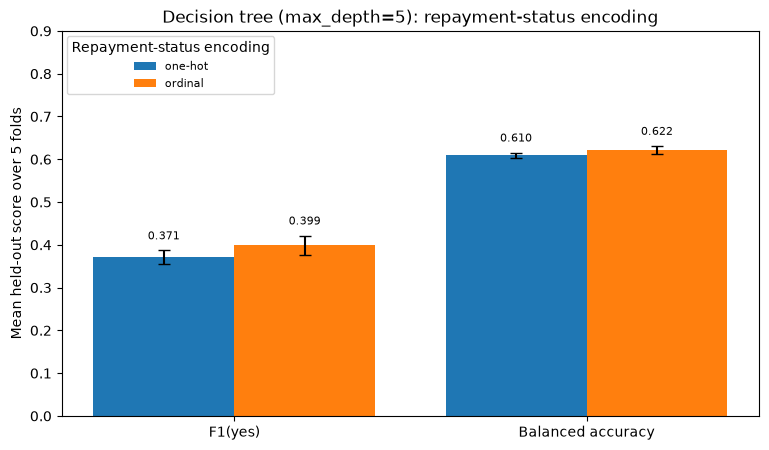

In [35]:
def plot_metric_comparison(scores_by_name, title, filename, legend_title):
    """Bar chart of mean F1(yes) and balanced accuracy for each pipeline, with +/- 1 fold std."""
    plot_metrics = ["f1_yes", "balanced_accuracy"]
    bar_width = 0.8 / len(scores_by_name)
    positions = np.arange(len(plot_metrics))
    fig, ax = plt.subplots(figsize=(9, 5))
    for i, (name, fold_scores) in enumerate(scores_by_name.items()):
        # Shift each pipeline's bars sideways so the bars for one metric sit side by side.
        offset = (i - (len(scores_by_name) - 1) / 2) * bar_width
        bars = ax.bar(positions + offset, fold_scores[plot_metrics].mean(), bar_width,
                      yerr=fold_scores[plot_metrics].std(), capsize=4, label=name)
        ax.bar_label(bars, fmt="%.3f", padding=6, fontsize=8)
    ax.set_xticks(positions, ["F1(yes)", "Balanced accuracy"])
    ax.set_ylim(0, 0.9)
    ax.set_ylabel("Mean held-out score over 5 folds")
    ax.set_title(title)
    ax.legend(title=legend_title, fontsize=8, loc="upper left")
    save_figure(fig, filename)


plot_metric_comparison(
    {"one-hot": one_hot_fold_scores, "ordinal": ordinal_fold_scores},
    "Decision tree (max_depth=5): repayment-status encoding",
    "repayment_encoding_comparison.png",
    "Repayment-status encoding",
)

**Measured comparison (same tree, same folds; mean +/- sample std over 5 folds).**

| Repayment encoding | F1(yes) | Balanced accuracy | Precision(yes) | Recall(yes) | Accuracy | Macro-F1 |
|---|---|---|---|---|---|---|
| One-hot (baseline) | 0.371 +/- 0.016 | 0.610 +/- 0.006 | 0.629 +/- 0.032 | 0.264 +/- 0.020 | 0.802 +/- 0.003 | 0.627 +/- 0.007 |
| Ordinal | 0.399 +/- 0.023 | 0.622 +/- 0.009 | 0.633 +/- 0.041 | 0.293 +/- 0.031 | 0.805 +/- 0.003 | 0.641 +/- 0.010 |

**What the outputs show.** The rebuilt one-hot pipeline reproduces the baseline exactly, so the
comparison is controlled. Ordinal encoding raised mean F1(yes) by 0.027, and it was higher in **all five
folds** (differences 0.013, 0.014, 0.031, 0.042, 0.036). Recall(yes) rose in every fold (by 0.009 to 0.047),
while precision(yes) went up in three folds and down in two. So the gain comes mainly from finding more
defaulters. Balanced accuracy and macro-F1 also improved in every fold. The plot shows the F1(yes) and
balanced-accuracy means with +/- 1 std error bars.

**Decision (for this tree).** Use **ordinal encoding for the six repayment-status columns** in the
decision-tree pipeline. Reasons: higher mean F1(yes), a consistent direction in every fold with a gain
larger than either fold std, and a simpler input (31 columns instead of 86). The result supports the
encoding for this tree; it does not confirm the assumed order of the first three labels. We do not claim statistical significance: five folds that share most of
their training data are not independent tests.

**Limits of this conclusion.**
- It holds for this depth-5 tree. A tree can use one threshold on the ordinal column; k-NN and naive Bayes
  use the numbers differently (distance, or a Gaussian per class), so the tree result is not transferred
  to them automatically (Phase 3 explains their representation).
- It depends on our **assumed** order of `no_balance`, `paid_on_time`, `revolving_credit`. We did not test
  other orders of these three labels, and this result does not confirm the assumption.
- The encoding was chosen using the same folds that report its score, so 0.399 may be optimistic as an
  estimate for new clients. This possible optimism was not quantified.

**How I would explain this in the oral exam:** I changed only the repayment-status encoding and kept
the tree, imputation and folds fixed. Ordinal encoding lets the tree ask one question like "is the status
`payment_delayed_2_months` or a longer delay?" instead of checking each delay label separately, and it improved F1(yes) in
all five folds, mainly through higher recall. The order of the three non-delay labels is my assumption.

**Likely questions:**
- *Why might ordinal help a shallow tree?* It packs the delay information into one ordered number per
  month, so a single split can separate long delays from short ones; one-hot spreads it over 61 columns.
- *Does this prove ordinal encoding is better in general?* No: it was measured for one tree, on one set of
  folds, using an assumed order for three labels. Other classifiers need their own comparison.
- *Precision fell in two folds; is that a problem?* F1 balances both; recall rose in every fold, which
  outweighed the small precision changes, so F1(yes) still rose in every fold.

## Phase 3 — baseline comparison of the four model families

Each family gets one fixed starting setting, scored on the same five folds with
the same median (numeric) and most-frequent (categorical) imputation. Nothing here is tuned.

| Family | Starting setting | Repayment encoding | Numeric scaling |
|---|---|---|---|
| Decision tree | `max_depth=5`, Gini (from Phase 2) | ordinal (chosen for this tree in Phase 2b) | none |
| Random forest | `n_estimators=100`, `random_state=42`; all else scikit-learn defaults, including unrestricted depth (`max_depth=None`) | **compared: one-hot vs ordinal** | none |
| k-NN | `n_neighbors=5`, Euclidean distance, uniform votes | one-hot | `StandardScaler` |
| Gaussian naive Bayes | scikit-learn defaults | one-hot | `StandardScaler` (same inputs as k-NN) |

Demographic columns are one-hot encoded for every family. For k-NN and naive Bayes we use one-hot
repayment encoding as the simple default that assumes no order and no spacing between labels; the
tree's ordinal result is not transferred automatically, and no further encoding comparison is run for
these two families (to keep the experiment budget small).

In [36]:
# Phase 3 setup: the other classifier families, the scaler for k-NN, and one shared pipeline builder.
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler


def make_model_pipeline(model, repayment_encoding, scale_numeric=False):
    """Median/mode imputation, one-hot demographics, chosen repayment encoding, optional scaling, then the model."""
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale_numeric:
        # Standardise with the training fold's mean and standard deviation (learned inside the fold).
        numeric_steps.append(("scale", StandardScaler()))
    demographic_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ])
    repayment_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", make_repayment_encoder(repayment_encoding)),
    ])
    preprocessor = ColumnTransformer(
        [
            ("numeric", Pipeline(numeric_steps), numeric_columns),
            ("demographic", demographic_steps, demographic_columns),
            ("repayment", repayment_steps, repayment_columns),
        ],
        sparse_threshold=0,  # always output a dense array: GaussianNB needs one and forests train faster
    )
    return Pipeline([("preprocess", preprocessor), ("model", model)])


def comparison_table(fold_scores_by_name):
    """One row per pipeline: mean and sample std (ddof=1) of every metric over the 5 folds."""
    rows = {}
    for name, fold_scores in fold_scores_by_name.items():
        rows[name] = {}
        for metric in scoring:
            rows[name][f"{metric}_mean"] = fold_scores[metric].mean()
            rows[name][f"{metric}_std"] = fold_scores[metric].std()
    return pd.DataFrame(rows).T.round(3)

**What it does.** `make_model_pipeline` takes any classifier and wraps it in the same preprocessing used
so far, with two switches: the repayment encoding and whether numeric columns are standardised.
`comparison_table` turns the per-fold scores of several pipelines into one table of means and sample
standard deviations. `sparse_threshold=0` makes the `ColumnTransformer` return an ordinary dense array.
This was needed after two problems observed in a first (scratch) run: `GaussianNB` raised
`TypeError: Sparse data was passed for X, but dense data is required`, and the one-hot random forest took
about 138 s on sparse input with a single core, against about 7 s on dense input with `n_jobs=-1`.

**Why scaling and encoding matter for k-NN.** k-NN classifies a client by the 5 nearest training clients
under Euclidean distance, which adds up squared differences over all columns. Unscaled, a bill difference
of 10,000 would swamp an age difference of 10 years, so numeric columns are standardised (mean 0,
std 1, learned in the training fold). One-hot columns are 0/1: two clients with different labels for a
feature differ in two columns, adding 2 to the squared distance, the same as two standard deviations of
difference in one numeric feature. With 9 categorical features (61+ one-hot columns), the categories carry
a lot of weight in the distance. Median and mode imputation also put many clients at exactly the same
value on about 40% of features, which can make neighbours less distinctive.

**What GaussianNB assumes.** It assumes the features are independent of each other *within each class*,
and that each feature follows a normal (Gaussian) distribution within each class, estimated by a class
mean and variance (L4 pp.58-60; G4 pp.1, 4-5). Applying it to one-hot 0/1 columns is an approximation,
because a 0/1 variable is not a bell-shaped measurement. Bills and payments are strongly skewed and
imputation adds spikes at the median, so the Gaussian shape is also a rough fit for numbers. The Phase 1
histograms show the *overall* shape per class but cannot verify the class-conditional independence or
normality assumptions. The Gaussian model itself is not affected by rescaling a feature; standardising
mainly keeps scikit-learn's small `var_smoothing` term (a fraction of the largest feature variance)
from swamping the 0/1 columns, and lets naive Bayes share the k-NN inputs.

**Likely questions:**
- *Why does the forest not need scaling?* Like a single tree, each split compares one feature with a
  threshold, so rescaling does not change the possible splits. Unusual values can still affect trees,
  for example by being isolated in small leaves.
- *Why is `random_state` not passed to k-NN or GaussianNB?* Neither has any randomness; their results
  depend only on the data.
- *What does `n_jobs=-1` change for the forest?* Only speed: trees are built on all CPU cores. Each tree's
  random seed comes from `random_state`, so results are identical (checked in Phase 6).

In [37]:
# The forest's starting settings: the values we set, plus the scikit-learn defaults that shape each tree.
starting_forest = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
forest_settings = starting_forest.get_params()
for setting in ["n_estimators", "random_state", "n_jobs", "criterion", "max_depth", "min_samples_split",
                "min_samples_leaf", "max_features", "bootstrap", "max_samples", "class_weight"]:
    print(f"{setting:18s} {forest_settings[setting]}")

# Random feature selection: with max_features="sqrt", each split looks at int(sqrt(columns)) random columns.
for encoding in ["one_hot", "ordinal"]:
    preprocessor = make_model_pipeline(starting_forest, encoding).named_steps["preprocess"]
    n_columns = len(preprocessor.fit(X.iloc[first_train_index]).get_feature_names_out())
    print(f"{encoding:8s}: {n_columns} input columns -> {int(np.sqrt(n_columns))} candidate columns per split")

# Bootstrap illustration (numpy's generator, not the forest's own draws): draw 19,200 rows with replacement.
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_rows = rng.integers(0, len(first_train_index), size=len(first_train_index))
print(f"Bootstrap illustration: {len(np.unique(bootstrap_rows)) / len(first_train_index):.3f} of the "
      f"{len(first_train_index):,} training rows appear at least once")

n_estimators       100
random_state       42
n_jobs             -1
criterion          gini
max_depth          None
min_samples_split  2
min_samples_leaf   1
max_features       sqrt
bootstrap          True
max_samples        None
class_weight       None
one_hot : 86 input columns -> 9 candidate columns per split
ordinal : 31 input columns -> 5 candidate columns per split
Bootstrap illustration: 0.634 of the 19,200 training rows appear at least once


**What it does.** Creates the starting forest, `RandomForestClassifier(n_estimators=100, random_state=42,
n_jobs=-1)`, and prints the settings that shape its trees. Only `n_estimators` and `random_state` were
chosen; `n_jobs=-1` uses all CPU cores and changes speed only (checked in Phase 6); everything else is a
scikit-learn 1.9.1 default. The cell also counts the input columns for each repayment encoding on fold 1's
training rows and simulates one bootstrap sample.

**Defaults that matter. These are starting settings, not tuned choices.**
- `max_depth=None`: **tree depth is unrestricted.** Each tree keeps splitting until its leaves are pure or
  a node has fewer than `min_samples_split=2` rows, and `min_samples_leaf=1` allows one-row leaves. The
  Phase 2 tree, in contrast, stops at depth 5.
- `criterion="gini"`: the same split measure as the decision tree.
- `bootstrap=True` with `max_samples=None`: every tree is trained on a bootstrap sample as large as the
  training fold.
- `max_features="sqrt"`: a random subset of columns at every split.
- `class_weight=None`: `yes` and `no` clients count equally.

**Bootstrap sampling.** For each tree, scikit-learn draws 19,200 rows *with replacement* from the 19,200
training-fold rows. Some clients are drawn several times and others not at all: in the illustration 0.634
of the rows appear at least once (the theoretical share is about 1 - 1/e = 0.632). Each tree therefore
learns from a slightly different data set. The draws come only from the training fold; validation rows
are never used for fitting.

**Random feature selection.** At each split (not once per tree), a tree considers only a random subset of
the columns and picks the best split among them: int(sqrt(31)) = 5 of the 31 ordinal-pipeline columns, or
9 of the 86 one-hot-pipeline columns. Different trees therefore start from different columns instead of
all choosing the same strongest one first, so their errors differ more and averaging can cancel some of them.

**What `n_estimators` controls.** The number of trees, 100 here (the scikit-learn default). More trees make
the averaged prediction depend less on the random draws, at a roughly proportional cost in training time
and memory; it does not make any single tree deeper or more complex. Other values were not compared.

**Identical settings in both encoding runs.** Both forests use exactly these settings, including
`random_state=42`, so the trees receive the same random seeds. Because the one-hot and ordinal pipelines
produce different columns (86 versus 31), the random column subsets still differ; that is part of the
encoding difference, not a separate setting.

**Likely questions:**
- *Does `max_depth=None` mean each tree overfits?* Each fully grown tree can fit its own bootstrap sample
  very closely; averaging 100 different trees is meant to reduce that variance. This baseline does not
  test other depths.
- *What is a bootstrap sample?* A sample of the same size as the training data, drawn with replacement,
  so roughly 63% of the clients appear at least once and some appear several times.
- *What does `n_estimators` change, and what does it not change?* It sets how many trees are averaged. It
  does not change how each individual tree is grown.

In [38]:
# How scikit-learn combines the 100 trees (illustration on fold 1 only; nothing is scored or chosen here).
first_valid_index = next(cv_folds.split(X, y))[1]  # fold 1's validation rows (training rows: first_train_index)
demo_pipeline = make_model_pipeline(
    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1), "ordinal")
demo_pipeline.fit(X.iloc[first_train_index], y.iloc[first_train_index])
demo_forest = demo_pipeline.named_steps["model"]
demo_rows = X.iloc[first_valid_index[:8]]
demo_inputs = demo_pipeline.named_steps["preprocess"].transform(demo_rows)

# Each tree's P(yes) for each of the 8 validation clients (one row per tree).
yes_column = list(demo_forest.classes_).index(POSITIVE_CLASS)
tree_yes = np.array([tree.predict_proba(demo_inputs)[:, yes_column] for tree in demo_forest.estimators_])
combination = pd.DataFrame({
    "trees_voting_yes": (tree_yes > 0.5).mean(axis=0),
    "mean_tree_P_yes": tree_yes.mean(axis=0),
    "forest_P_yes": demo_forest.predict_proba(demo_inputs)[:, yes_column],
    "forest_label": demo_pipeline.predict(demo_rows),
})
print("Number of trees:", len(demo_forest.estimators_))
print("Forest P(yes) equals the mean of the trees' P(yes):",
      np.allclose(combination["mean_tree_P_yes"], combination["forest_P_yes"]))
print("Forest label is 'yes' exactly when forest P(yes) > 0.5:",
      (combination["forest_label"] == np.where(combination["forest_P_yes"] > 0.5, "yes", "no")).all())
print("Share of all tree outputs that are exactly 0 or 1:", round(np.isin(tree_yes, [0.0, 1.0]).mean(), 3))
combination.round(3)

Number of trees: 100
Forest P(yes) equals the mean of the trees' P(yes): True
Forest label is 'yes' exactly when forest P(yes) > 0.5: True
Share of all tree outputs that are exactly 0 or 1: 1.0


,trees_voting_yes,mean_tree_P_yes,forest_P_yes,forest_label
0,0.38,0.38,0.38,no
1,0.17,0.17,0.17,no
2,0.38,0.38,0.38,no
3,0.50,0.50,0.50,no
4,0.17,0.17,0.17,no
5,0.29,0.29,0.29,no
6,0.08,0.08,0.08,no
7,0.20,0.20,0.20,no


**What it does.** Fits one ordinal-encoded forest on fold 1's training rows and looks at 8 of fold 1's
validation clients. For each client it shows the share of the 100 trees that predict `yes`, the mean of
the trees' P(yes), the forest's own `predict_proba` and its final label. This is an illustration only:
it is not scored, and no choice depends on it.

**How scikit-learn combines the trees.** `RandomForestClassifier` averages probabilities rather than
counting votes. Each tree's P(yes) is the proportion of `yes` training rows (counting repeated bootstrap
rows) in the leaf the client reaches, and the forest's P(yes) is the mean over the 100 trees; the check
prints True. `predict` then chooses the class with the higher average probability. A tie at exactly 0.5 goes
to the first class in `classes_`, which is `no`: client 3 has P(yes) = 0.50 and is labelled `no`.

Here every tree output is exactly 0 or 1 (the printed share is 1.0), because unrestricted trees grow until
their leaves are pure. The average is therefore the same as the share of trees voting `yes`. With
depth-limited trees, leaves can be mixed, and the average probability and the vote share can differ.

**Likely questions:**
- *Is a random forest a majority vote?* scikit-learn averages the trees' probabilities. For these fully
  grown trees each probability is 0 or 1, so the average equals the share of trees voting `yes`.
- *Why is client 3 labelled `no` with P(yes) = 0.50?* `predict` takes the class with the highest
  probability, and on a tie it takes the first class in `classes_`, `no`.
- *Could this demonstration leak information?* No. The forest is fitted on fold 1's training rows only,
  applied to that fold's validation rows, and not used for any decision.

In [39]:
# One fixed starting configuration per family, all scored on the same cv_folds.
baseline_pipelines = {
    "Decision tree, depth 5 (ordinal)": make_model_pipeline(
        DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=RANDOM_STATE), "ordinal"),
    "Random forest, 100 trees (one-hot)": make_model_pipeline(
        RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1), "one_hot"),
    "Random forest, 100 trees (ordinal)": make_model_pipeline(
        RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1), "ordinal"),
    "k-NN, k=5 (one-hot, scaled)": make_model_pipeline(
        KNeighborsClassifier(n_neighbors=5), "one_hot", scale_numeric=True),
    "Gaussian naive Bayes (one-hot, scaled)": make_model_pipeline(
        GaussianNB(), "one_hot", scale_numeric=True),
}
baseline_fold_scores = {name: evaluate_pipeline(pipeline) for name, pipeline in baseline_pipelines.items()}

print("Tree rebuilt with make_model_pipeline matches Phase 2b:",
      np.allclose(baseline_fold_scores["Decision tree, depth 5 (ordinal)"], ordinal_fold_scores))
comparison_table(baseline_fold_scores)

Tree rebuilt with make_model_pipeline matches Phase 2b: True


,accuracy_mean,accuracy_std,precision_yes_mean,precision_yes_std,recall_yes_mean,recall_yes_std,f1_yes_mean,f1_yes_std,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
"Decision tree, depth 5 (ordinal)",0.805,0.003,0.633,0.041,0.293,0.031,0.399,0.023,0.641,0.010,0.622,0.009
"Random forest, 100 trees (one-hot)",0.809,0.004,0.656,0.025,0.288,0.011,0.400,0.014,0.643,0.008,0.623,0.006
"Random forest, 100 trees (ordinal)",0.809,0.005,0.647,0.028,0.299,0.011,0.408,0.013,0.647,0.008,0.626,0.006
"k-NN, k=5 (one-hot, scaled)",0.778,0.006,0.498,0.027,0.236,0.015,0.320,0.018,0.594,0.011,0.584,0.008
"Gaussian naive Bayes (one-hot, scaled)",0.790,0.003,0.639,0.037,0.115,0.023,0.194,0.032,0.536,0.016,0.548,0.009


In [40]:
# Random forest: ordinal minus one-hot repayment encoding, fold by fold (positive = ordinal higher).
forest_encoding_difference = (baseline_fold_scores["Random forest, 100 trees (ordinal)"]
                              - baseline_fold_scores["Random forest, 100 trees (one-hot)"])
print(forest_encoding_difference.round(3))
print("Folds where ordinal had the higher F1(yes):", (forest_encoding_difference["f1_yes"] > 0).sum(), "of 5")
print("Average F1(yes) difference:", round(forest_encoding_difference["f1_yes"].mean(), 3))

      accuracy  precision_yes  recall_yes  f1_yes  macro_f1  balanced_accuracy
fold                                                                          
1       -0.003         -0.027       0.009   0.003     0.001              0.001
2        0.002          0.007       0.012   0.013     0.007              0.006
3       -0.001         -0.011       0.007   0.004     0.002              0.002
4        0.001          0.002       0.013   0.013     0.007              0.006
5       -0.002         -0.019       0.011   0.007     0.003              0.003
Folds where ordinal had the higher F1(yes): 5 of 5
Average F1(yes) difference: 0.008


In [41]:
# Forest (ordinal) minus the depth-5 tree (ordinal), fold by fold (positive = forest higher).
# The two models differ in several settings at once, so this does not measure ensembling alone.
forest_minus_tree = (baseline_fold_scores["Random forest, 100 trees (ordinal)"]
                     - baseline_fold_scores["Decision tree, depth 5 (ordinal)"])
print(forest_minus_tree.round(3))
print("Folds where the forest had the higher F1(yes):", (forest_minus_tree["f1_yes"] > 0).sum(), "of 5")
print("Average F1(yes) difference:", round(forest_minus_tree["f1_yes"].mean(), 3))

      accuracy  precision_yes  recall_yes  f1_yes  macro_f1  balanced_accuracy
fold                                                                          
1        0.004          0.007       0.030   0.030     0.016              0.013
2        0.006         -0.008       0.057   0.058     0.030              0.025
3        0.002          0.024      -0.028  -0.020    -0.009             -0.009
4        0.001          0.017      -0.019  -0.013    -0.006             -0.006
5        0.004          0.028      -0.014  -0.007    -0.002             -0.003
Folds where the forest had the higher F1(yes): 2 of 5
Average F1(yes) difference: 0.01


**Random-forest baseline results (same five folds; mean +/- sample std).**

| Pipeline | F1(yes) | Balanced accuracy | Precision(yes) | Recall(yes) | Accuracy | Macro-F1 |
|---|---|---|---|---|---|---|
| Decision tree, depth 5 (ordinal) | 0.399 +/- 0.023 | 0.622 +/- 0.009 | 0.633 +/- 0.041 | 0.293 +/- 0.031 | 0.805 +/- 0.003 | 0.641 +/- 0.010 |
| Random forest (one-hot) | 0.400 +/- 0.014 | 0.623 +/- 0.006 | 0.656 +/- 0.025 | 0.288 +/- 0.011 | 0.809 +/- 0.004 | 0.643 +/- 0.008 |
| Random forest (ordinal) | 0.408 +/- 0.013 | 0.626 +/- 0.006 | 0.647 +/- 0.028 | 0.299 +/- 0.011 | 0.809 +/- 0.005 | 0.647 +/- 0.008 |

**One-hot versus ordinal for the forest.** Only the repayment encoding differs; the forest settings,
imputation, demographic encoding and folds are identical. Ordinal F1(yes) was higher in all 5 folds, but
only by 0.003-0.013 (mean 0.008), which is smaller than either run's fold std (0.013-0.014). Recall rose in
every fold (by 0.007-0.013), precision fell in three folds and rose in two, and accuracy changed by at most
0.003. Decision: keep ordinal for the forest, because it was never worse in F1(yes), matches the tree
pipeline and uses 31 instead of 86 inputs. The evidence that it helps the forest is weak. As in Phase 2b,
the choice and its score come from the same folds, so the score may be optimistic; this was not quantified.

**Forest versus the depth-5 tree (both ordinal).** The forest's mean F1(yes) is 0.408 versus 0.399, but it
was higher in only **2 of 5 folds** (+0.030, +0.058) and lower in the other three (-0.020, -0.013, -0.007).
Accuracy was higher in all five folds (by 0.001-0.006), precision in four and recall in two. So this
untuned forest is not clearly better than the tree on F1(yes). Both miss most defaulters (recall about
0.29-0.30).

**This comparison does not isolate the effect of ensembling.** The two models differ in several ways at
once: the forest averages 100 trees trained on bootstrap samples with random column subsets, *and* its
trees have unrestricted depth with one-row leaves, while the single tree stops at depth 5. Any of these
differences could explain the gap. A single unrestricted tree, which would be needed to separate them, was
not run.

**How I would explain this in the oral exam:** I added a 100-tree random forest with scikit-learn's
default settings and changed only the repayment encoding between two runs. Ordinal encoding was slightly
better in every fold, but by less than the fold variation. The forest was a little ahead of the depth-5
tree on average but not in most folds, and because its trees are also much deeper, I cannot attribute
that difference to ensembling alone.

**Likely questions:**
- *Is the forest better than the tree because it is an ensemble?* We cannot tell. Ensembling and tree depth
  both differ between the two models, and the forest was higher in only 2 of 5 folds.
- *What changed between the two forest runs?* Only the encoder for the six repayment columns. That changes
  the input from 86 to 31 columns, and therefore the candidate columns per split from 9 to 5.
- *Why keep ordinal if the gain is smaller than the std?* It was never worse in any fold, it matches the tree
  pipeline and it is simpler; we do not claim the gain is reliable.

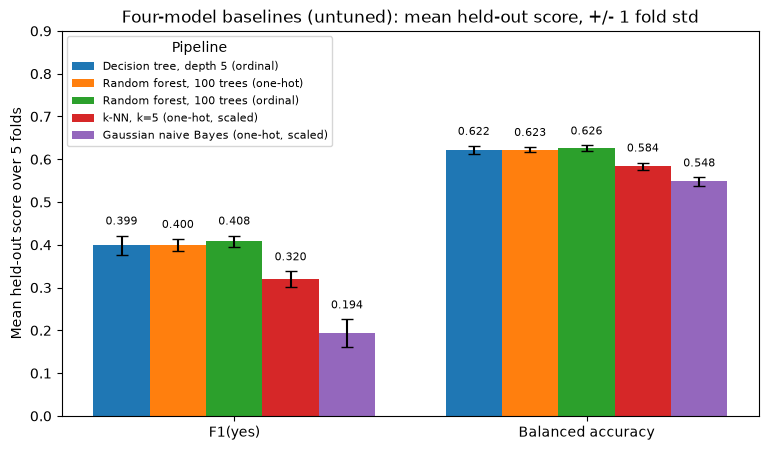

In [42]:
plot_metric_comparison(
    baseline_fold_scores,
    "Four-model baselines (untuned): mean held-out score, +/- 1 fold std",
    "baseline_model_comparison.png",
    "Pipeline",
)

**Measured baselines (mean +/- sample std over the same 5 folds).**

| Pipeline | F1(yes) | Balanced accuracy | Precision(yes) | Recall(yes) | Accuracy | Macro-F1 |
|---|---|---|---|---|---|---|
| Decision tree, depth 5 (ordinal) | 0.399 +/- 0.023 | 0.622 +/- 0.009 | 0.633 +/- 0.041 | 0.293 +/- 0.031 | 0.805 +/- 0.003 | 0.641 +/- 0.010 |
| Random forest (one-hot) | 0.400 +/- 0.014 | 0.623 +/- 0.006 | 0.656 +/- 0.025 | 0.288 +/- 0.011 | 0.809 +/- 0.004 | 0.643 +/- 0.008 |
| Random forest (ordinal) | 0.408 +/- 0.013 | 0.626 +/- 0.006 | 0.647 +/- 0.028 | 0.299 +/- 0.011 | 0.809 +/- 0.005 | 0.647 +/- 0.008 |
| k-NN, k=5 (one-hot, scaled) | 0.320 +/- 0.018 | 0.584 +/- 0.008 | 0.498 +/- 0.027 | 0.236 +/- 0.015 | 0.778 +/- 0.006 | 0.594 +/- 0.011 |
| Gaussian NB (one-hot, scaled) | 0.194 +/- 0.032 | 0.548 +/- 0.009 | 0.639 +/- 0.037 | 0.115 +/- 0.023 | 0.790 +/- 0.003 | 0.536 +/- 0.016 |

**What the outputs show.** The shared builder reproduces the Phase 2b tree exactly. Untuned, the random
forest with ordinal repayment encoding has the highest mean F1(yes), 0.408, but the decision tree and the
one-hot forest are close (0.399, 0.400), and the forest beat the tree in only 2 of 5 folds. For the forest, ordinal encoding was higher in all 5 folds but by
only 0.008 on average, which is smaller than the fold std; we keep ordinal for the forest because it is
never worse here, matches the tree pipeline and gives 31 instead of 86 inputs, not because the gap is
convincing on its own. k-NN (0.320) and especially Gaussian naive Bayes (0.194) are clearly weaker.
All five pipelines share the same weakness: recall(yes) is low (0.12-0.30), so most defaulters are missed.

**Naive Bayes result.** GaussianNB predicts `yes` rarely (recall 0.115) with moderate precision. A likely
reason is that its Gaussian approximation fits these 0/1 and skewed, imputed inputs poorly, but we did
not investigate further: this is a hypothesis, not a measured explanation.

**Decision for Phase 4.** Tune the two tree-based families, which are the most promising (random forest
and decision tree, both with ordinal repayment encoding). k-NN and naive Bayes are kept as reported
baselines; they are below the tree models by about 0.08-0.21 F1(yes), which is large relative to fold std.

**How I would explain this in the oral exam:** I gave each of the four model families one sensible
starting setting and scored them on identical folds. The tree-based models were best, the random forest
slightly ahead on average but not in most folds, while k-NN and naive Bayes were much weaker, so I spent the small tuning budget on the
tree and the forest.

**Likely questions:**
- *Why might k-NN do poorly here?* Distances mix 14 scaled numbers with many 0/1 columns, 40% of values
  are imputed to identical medians/modes, and k=5 neighbours vote with equal weight; these are plausible
  reasons, not tested ones.
- *Is it fair that k-NN and naive Bayes were not tuned?* They received a reasonable default each, as the
  baseline comparison requires; with a 12-configuration budget we tuned the families with the best evidence.
- *Why might a forest beat a single tree?* Averaging 100 trees, each trained on a bootstrap sample with
  random feature subsets at each split (L3 pp.72-74), can reduce the variance of a single tree. In this
  baseline the forest's trees are also unrestricted in depth, so the comparison with the depth-5 tree does
  not isolate ensembling, and the forest was higher in only 2 of 5 folds.

## Phase 4 — tuning and class-weight comparison

**Plan, written before running any of these configurations.**
Budget: at most 12 new configurations. Both families use ordinal repayment encoding and the Phase 3
preprocessing. `class_weight="balanced"` is permitted by staff (Clarification C) and is supported by
both estimators.

| Family | Candidate values | Combinations | New |
|---|---|---|---|
| Random forest (100 trees, `random_state=42`) | `class_weight` in {None, "balanced"}; `max_depth` in {None, 10}; `min_samples_leaf` in {1, 10} | 8 | 7 (None/None/1 is the Phase 3 baseline) |
| Decision tree (Gini, `random_state=42`) | `class_weight` in {None, "balanced"}; `max_depth` in {3, 5, 8} | 6 | 5 (None/5 is the Phase 3 baseline) |

Total: 12 new configurations, plus the two baselines re-run as a consistency check.

**Why these values.** `max_depth` limits how many questions a tree may ask (pre-pruning, L3 pp.62-67);
`min_samples_leaf=10` stops leaves being created for only a handful of clients. For the forest, `None`
(fully grown) is the scikit-learn default and 10 is a moderate limit. For the single tree, 3/5/8 brackets
the Phase 2 depth. `class_weight="balanced"` weights each class inversely to its frequency, so mistakes on
the 22% `yes` clients count about 3.5 times as much as mistakes on `no` clients when choosing splits.

**Selection rule.** Choose the highest mean F1(yes). If a candidate with fewer non-default settings is
within about one fold standard deviation, prefer it. This is a practical tie-break, not a significance
test. Precision and recall are inspected to explain the trade-off.

**Threshold candidates (Phase 4b), also fixed now:** 0.2, 0.3, 0.4, 0.5, 0.6, applied to the strongest
practical candidate from this phase.

In [43]:
from sklearn.model_selection import ParameterGrid

# The declared candidate lists; ParameterGrid lists every combination, as GridSearchCV would.
# We loop ourselves so that every configuration keeps its 5 fold scores and the same ddof=1 summary.
forest_grid = ParameterGrid({"class_weight": [None, "balanced"], "max_depth": [None, 10], "min_samples_leaf": [1, 10]})
tree_grid = ParameterGrid({"class_weight": [None, "balanced"], "max_depth": [3, 5, 8]})

tuning_fold_scores = {}
for settings in forest_grid:
    forest = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, **settings)
    name = (f"Random forest, weights={settings['class_weight']}, "
            f"depth={settings['max_depth']}, leaf={settings['min_samples_leaf']}")
    tuning_fold_scores[name] = evaluate_pipeline(make_model_pipeline(forest, "ordinal"))
for settings in tree_grid:
    tree = DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE, **settings)
    name = f"Decision tree, weights={settings['class_weight']}, depth={settings['max_depth']}"
    tuning_fold_scores[name] = evaluate_pipeline(make_model_pipeline(tree, "ordinal"))

# The two repeated baselines must give exactly the Phase 3 scores.
print("Forest baseline repeated exactly:", np.allclose(
    tuning_fold_scores["Random forest, weights=None, depth=None, leaf=1"],
    baseline_fold_scores["Random forest, 100 trees (ordinal)"]))
print("Tree baseline repeated exactly:", np.allclose(
    tuning_fold_scores["Decision tree, weights=None, depth=5"],
    baseline_fold_scores["Decision tree, depth 5 (ordinal)"]))
print("Configurations evaluated:", len(tuning_fold_scores), "(12 new + 2 repeated baselines)")

tuning_table = comparison_table(tuning_fold_scores).sort_values("f1_yes_mean", ascending=False)
tuning_table

Forest baseline repeated exactly: True
Tree baseline repeated exactly: True
Configurations evaluated: 14 (12 new + 2 repeated baselines)


,accuracy_mean,accuracy_std,precision_yes_mean,precision_yes_std,recall_yes_mean,recall_yes_std,f1_yes_mean,f1_yes_std,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
"Random forest, weights=balanced, depth=10, leaf=10",0.764,0.007,0.470,0.012,0.538,0.007,0.502,0.007,0.673,0.006,0.683,0.005
"Random forest, weights=balanced, depth=10, leaf=1",0.770,0.007,0.481,0.014,0.525,0.008,0.502,0.010,0.676,0.008,0.682,0.006
"Random forest, weights=balanced, depth=None, leaf=10",0.757,0.004,0.459,0.007,0.548,0.011,0.500,0.006,0.670,0.004,0.682,0.005
"Decision tree, weights=balanced, depth=5",0.775,0.013,0.494,0.030,0.479,0.018,0.485,0.012,0.671,0.010,0.669,0.007
"Random forest, weights=balanced, depth=None, leaf=1",0.798,0.003,0.556,0.008,0.426,0.006,0.483,0.006,0.679,0.004,0.665,0.004
"Decision tree, weights=balanced, depth=3",0.776,0.005,0.494,0.013,0.463,0.010,0.478,0.010,0.668,0.007,0.664,0.006
"Decision tree, weights=balanced, depth=8",0.759,0.015,0.461,0.026,0.488,0.035,0.473,0.014,0.658,0.010,0.662,0.010
"Random forest, weights=None, depth=None, leaf=10",0.810,0.004,0.654,0.025,0.296,0.013,0.408,0.015,0.647,0.008,0.626,0.007
"Random forest, weights=None, depth=None, leaf=1",0.809,0.005,0.647,0.028,0.299,0.011,0.408,0.013,0.647,0.008,0.626,0.006
"Decision tree, weights=None, depth=8",0.802,0.005,0.605,0.028,0.306,0.025,0.406,0.021,0.644,0.011,0.625,0.009


In [44]:
# Effect of class_weight="balanced": identical settings, only the weighting changes.
weight_effect = []
for name, fold_scores in tuning_fold_scores.items():
    if "weights=None" in name:
        balanced_scores = tuning_fold_scores[name.replace("weights=None", "weights=balanced")]
        weight_effect.append({
            "settings": name.replace("weights=None, ", ""),
            "f1_unweighted": fold_scores["f1_yes"].mean(),
            "f1_balanced": balanced_scores["f1_yes"].mean(),
            "precision_unweighted": fold_scores["precision_yes"].mean(),
            "precision_balanced": balanced_scores["precision_yes"].mean(),
            "recall_unweighted": fold_scores["recall_yes"].mean(),
            "recall_balanced": balanced_scores["recall_yes"].mean(),
        })
pd.DataFrame(weight_effect).set_index("settings").round(3)

,f1_unweighted,f1_balanced,precision_unweighted,precision_balanced,recall_unweighted,recall_balanced
settings,,,,,,
"Random forest, depth=None, leaf=1",0.408,0.483,0.647,0.556,0.299,0.426
"Random forest, depth=None, leaf=10",0.408,0.500,0.654,0.459,0.296,0.548
"Random forest, depth=10, leaf=1",0.402,0.502,0.663,0.481,0.289,0.525
"Random forest, depth=10, leaf=10",0.395,0.502,0.670,0.470,0.280,0.538
"Decision tree, depth=3",0.378,0.478,0.648,0.494,0.269,0.463
"Decision tree, depth=5",0.399,0.485,0.633,0.494,0.293,0.479
"Decision tree, depth=8",0.406,0.473,0.605,0.461,0.306,0.488


In [45]:
# Fold-by-fold F1(yes) for the leading candidates, plus the unweighted version of the top forest.
leading_names = [
    "Random forest, weights=balanced, depth=10, leaf=1",
    "Random forest, weights=balanced, depth=10, leaf=10",
    "Random forest, weights=balanced, depth=None, leaf=10",
    "Decision tree, weights=balanced, depth=5",
    "Random forest, weights=None, depth=10, leaf=1",
]
leader_f1 = pd.DataFrame({name: tuning_fold_scores[name]["f1_yes"] for name in leading_names})
print(leader_f1.round(3).T)
print("\nUnrounded mean F1(yes):")
print(leader_f1.mean().round(4).to_string())
forest_minus_tree = leader_f1[leading_names[0]] - leader_f1["Decision tree, weights=balanced, depth=5"]
print("\nTop forest minus best tree, per fold:", forest_minus_tree.round(3).tolist())

fold                                                    1      2      3      4      5
Random forest, weights=balanced, depth=10, leaf=1   0.506  0.514  0.499  0.487  0.505
Random forest, weights=balanced, depth=10, leaf=10  0.505  0.509  0.498  0.491  0.505
Random forest, weights=balanced, depth=None, le...  0.504  0.507  0.493  0.494  0.500
Decision tree, weights=balanced, depth=5            0.488  0.504  0.482  0.472  0.481
Random forest, weights=None, depth=10, leaf=1       0.423  0.405  0.406  0.411  0.367

Unrounded mean F1(yes):
Random forest, weights=balanced, depth=10, leaf=1       0.5022
Random forest, weights=balanced, depth=10, leaf=10      0.5016
Random forest, weights=balanced, depth=None, leaf=10    0.4996
Decision tree, weights=balanced, depth=5                0.4855
Random forest, weights=None, depth=10, leaf=1           0.4024

Top forest minus best tree, per fold: [0.018, 0.011, 0.016, 0.016, 0.023]


**Measured results (14 configurations; all six metrics in the table above).**
- **Class weighting is the dominant effect.** For every matched setting, `class_weight="balanced"` raised
  mean F1(yes): forests from 0.395-0.408 to 0.483-0.502, trees from 0.378-0.406 to 0.473-0.485. It works by
  trading precision for recall: for the depth-10 forest, recall rose from 0.289 to 0.525 while precision fell
  from 0.663 to 0.481. With the default 0.5 decision rule, the unweighted models are too cautious for F1(yes).
- **The leading forests are practically tied.** Balanced forests with depth 10/leaf 1 (0.502 +/- 0.010),
  depth 10/leaf 10 (0.502 +/- 0.007) and unlimited depth/leaf 10 (0.500 +/- 0.006) differ by about 0.002,
  far less than one fold std. The fully grown balanced forest (depth None, leaf 1) is lower, 0.483. A likely
  reason (not tested) is that fully grown trees end in nearly pure leaves, so the weights change the splits
  but hardly change each leaf's `yes` proportion.
- **Depth and leaf size matter little without weighting at threshold 0.5** (0.395-0.408 for these forests).
  This does not compare their best thresholds; Phase 4c supplies that missing comparison.
- **Forest versus tree.** The best balanced tree (depth 5) reaches 0.485 +/- 0.012. The top forest was
  higher in all 5 folds (by 0.011-0.023), a gap larger than either model's fold std.

**Selection.** Applying the declared rule: depth 10/leaf 1 and depth 10/leaf 10 both round to 0.502, so
the table above may list either first; unrounded, depth 10/leaf 1 is highest (0.5022 versus 0.5016 and
0.4996). The other candidates within one std do not use fewer non-default settings (depth 10/leaf 10 uses
one more; unlimited depth/leaf 10 uses the same number), so the tie-break does not move the choice. The
simpler single tree is not within one std. **Strongest practical candidate:**
`RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", random_state=42)`
with ordinal repayment encoding. Any of the three tied forests would be a reasonable choice.

**How I would explain this in the oral exam:** I wrote down a small grid before running it: depth, leaf
size and class weights for the forest, depth and class weights for the tree, 12 new settings in total.
Class weighting made the biggest difference because it makes the model pay more attention to defaulters,
which raises recall at the cost of some precision. Among the top forests the differences were tiny, so I
took the best mean without claiming it is truly better than its neighbours.

**Likely questions:**
- *What does `class_weight="balanced"` do?* Each `yes` client counts about 3.5 times as much as a `no` client
  when the trees choose splits and estimate leaf proportions, so more clients end up predicted `yes`.
- *Is that resampling?* No. No rows are duplicated or removed; the training data are unchanged and only
  their weights in the impurity calculation change. Random over/undersampling is not permitted (Clarification C).
- *Why is the 0.502 optimistic?* We picked it as the best of 14 configurations on the same folds used to
  report it; the true performance of this selection procedure on new clients is unknown and may be lower.

## Phase 4b — probability-threshold comparison

Staff permit selecting a probability threshold using development data (Clarifications B and C).
For each client, scikit-learn's random forest averages over its 100 trees the proportion of `yes`
(class-weighted) training clients in the leaf that client reaches; this average is P(yes). The default
rule predicts `yes` when that probability is at least 0.5. Here we compare the five thresholds declared in
the Phase 4 plan, 0.2, 0.3, 0.4, 0.5 and 0.6, for the balanced depth-10 forest.

Method: fit the pipeline once per training fold, store the `yes` probability for that fold's validation
rows (out-of-fold probabilities), then apply every threshold to the same stored probabilities. No model is
refitted per threshold. The prediction rule is `"yes" if probability >= threshold else "no"`, the same
operator used in `main.py`.

In [46]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, balanced_accuracy_score


def out_of_fold_yes_probabilities(pipeline, folds=None):
    """P(yes) for every development row, predicted by the fold model that did not train on that row."""
    folds = cv_folds if folds is None else folds
    yes_probability = np.full(len(y), np.nan)
    held_out_count = np.zeros(len(y), dtype=int)
    fold_of_row = np.zeros(len(y), dtype=int)
    for fold_number, (train_index, valid_index) in enumerate(folds.split(X, y), start=1):
        assert not np.intersect1d(train_index, valid_index).size
        held_out_count[valid_index] += 1
        model = clone(pipeline).fit(X.iloc[train_index], y.iloc[train_index])
        yes_column = list(model.classes_).index(POSITIVE_CLASS)  # column order comes from the fitted classes
        yes_probability[valid_index] = model.predict_proba(X.iloc[valid_index])[:, yes_column]
        fold_of_row[valid_index] = fold_number
    # Every development client must be predicted exactly once by a model that did not train on it.
    assert (held_out_count == 1).all() and np.isfinite(yes_probability).all()
    return yes_probability, fold_of_row


def labels_from_probability(yes_probability, threshold):
    """The project's prediction rule: "yes" when P(yes) >= threshold, otherwise "no"."""
    return np.where(yes_probability >= threshold, POSITIVE_CLASS, "no")


def score_labels(true_labels, predicted_labels):
    """The six reported metrics for one fold's true and predicted labels."""
    return {
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "precision_yes": precision_score(true_labels, predicted_labels, pos_label=POSITIVE_CLASS),
        "recall_yes": recall_score(true_labels, predicted_labels, pos_label=POSITIVE_CLASS),
        "f1_yes": f1_score(true_labels, predicted_labels, pos_label=POSITIVE_CLASS),
        "macro_f1": f1_score(true_labels, predicted_labels, average="macro"),
        "balanced_accuracy": balanced_accuracy_score(true_labels, predicted_labels),
    }


def threshold_fold_scores(yes_probability, fold_of_row, threshold):
    """Apply one threshold to the stored out-of-fold probabilities and score each fold separately."""
    true_labels = y.to_numpy()
    rows = []
    for fold_number in range(1, cv_folds.get_n_splits() + 1):
        in_fold = fold_of_row == fold_number
        rows.append(score_labels(true_labels[in_fold],
                                 labels_from_probability(yes_probability[in_fold], threshold)))
    return pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1, name="fold"))

In [47]:
CANDIDATE_NAME = "Random forest, weights=balanced, depth=10, leaf=1"
candidate_pipeline = make_model_pipeline(
    RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced",
                           random_state=RANDOM_STATE, n_jobs=-1),
    "ordinal",
)
candidate_yes_probability, candidate_fold_of_row = out_of_fold_yes_probabilities(candidate_pipeline)

CANDIDATE_THRESHOLDS = [0.2, 0.3, 0.4, 0.5, 0.6]
threshold_scores = {
    f"threshold {t}": threshold_fold_scores(candidate_yes_probability, candidate_fold_of_row, t)
    for t in CANDIDATE_THRESHOLDS
}

# At 0.5 the explicit rule should reproduce the model's own predict() scores from Phase 4.
print("Threshold 0.5 matches cross_validate predict():",
      np.allclose(threshold_scores["threshold 0.5"], tuning_fold_scores[CANDIDATE_NAME]))
print("Out-of-fold probabilities exactly equal to 0.5:", (candidate_yes_probability == 0.5).sum())
print("\nF1(yes) per fold at each threshold:")
print(pd.DataFrame({name: scores["f1_yes"] for name, scores in threshold_scores.items()}).round(3).T)
comparison_table(threshold_scores)

Threshold 0.5 matches cross_validate predict(): True
Out-of-fold probabilities exactly equal to 0.5: 0

F1(yes) per fold at each threshold:
fold               1      2      3      4      5
threshold 0.2  0.363  0.364  0.365  0.363  0.364
threshold 0.3  0.400  0.397  0.403  0.397  0.399
threshold 0.4  0.468  0.464  0.460  0.468  0.468
threshold 0.5  0.506  0.514  0.499  0.487  0.505
threshold 0.6  0.483  0.510  0.478  0.480  0.477


,accuracy_mean,accuracy_std,precision_yes_mean,precision_yes_std,recall_yes_mean,recall_yes_std,f1_yes_mean,f1_yes_std,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
threshold 0.2,0.227,0.003,0.222,0.001,0.999,0.001,0.364,0.001,0.189,0.005,0.503,0.002
threshold 0.3,0.376,0.008,0.254,0.002,0.936,0.004,0.399,0.003,0.375,0.008,0.577,0.004
threshold 0.4,0.614,0.010,0.336,0.005,0.759,0.012,0.465,0.003,0.582,0.007,0.666,0.003
threshold 0.5,0.770,0.007,0.481,0.014,0.525,0.008,0.502,0.010,0.676,0.008,0.682,0.006
threshold 0.6,0.801,0.005,0.569,0.017,0.424,0.014,0.486,0.014,0.681,0.008,0.666,0.008


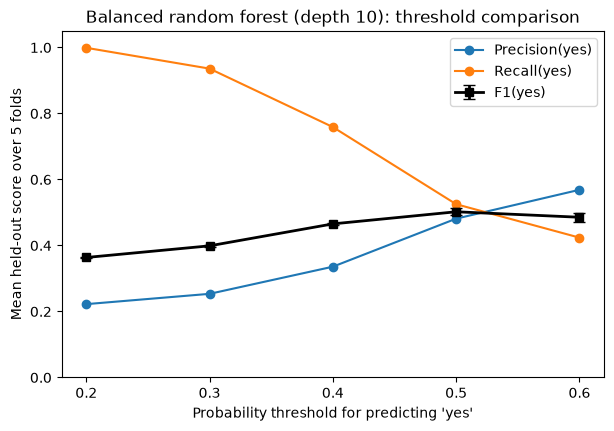

In [48]:
# Mean precision, recall and F1(yes) across the candidate thresholds (error bars: +/- 1 fold std of F1).
fig, ax = plt.subplots(figsize=(7, 4.5))
for metric, label in [("precision_yes", "Precision(yes)"), ("recall_yes", "Recall(yes)")]:
    ax.plot(CANDIDATE_THRESHOLDS, [s[metric].mean() for s in threshold_scores.values()], marker="o", label=label)
ax.errorbar(CANDIDATE_THRESHOLDS, [s["f1_yes"].mean() for s in threshold_scores.values()],
            yerr=[s["f1_yes"].std() for s in threshold_scores.values()],
            marker="s", capsize=4, linewidth=2, color="black", label="F1(yes)")
ax.set_title("Balanced random forest (depth 10): threshold comparison")
ax.set_xlabel("Probability threshold for predicting 'yes'")
ax.set_ylabel("Mean held-out score over 5 folds")
ax.set_xticks(CANDIDATE_THRESHOLDS)
ax.set_ylim(0, 1.05)
ax.legend()
save_figure(fig, "threshold_comparison.png")

**Measured results (same out-of-fold probabilities, five thresholds).**

| Threshold | F1(yes) | Precision(yes) | Recall(yes) |
|---|---|---|---|
| 0.2 | 0.364 +/- 0.001 | 0.222 | 0.999 |
| 0.3 | 0.399 +/- 0.003 | 0.254 | 0.936 |
| 0.4 | 0.465 +/- 0.003 | 0.336 | 0.759 |
| **0.5** | **0.502 +/- 0.010** | 0.481 | 0.525 |
| 0.6 | 0.486 +/- 0.014 | 0.569 | 0.424 |

The explicit rule at 0.5 reproduces the Phase 4 `predict()` scores exactly, and no out-of-fold probability
is exactly 0.5, so `>=` and scikit-learn's own tie rule agree here. Lower thresholds push recall towards 1
but precision collapses towards the 22% base rate; 0.6 gains precision but loses more recall. The default
0.5 has the highest mean F1(yes) and was higher than 0.6 in every fold. (Macro-F1 is marginally higher
at 0.6, 0.681 versus 0.676, but the assessed and selection metric is F1 for `yes`.)

**Decision at this stage.** Keep **threshold 0.5**. Class weighting had already moved this forest's predictions towards `yes`
(Phase 4: recall at the same 0.5 cut-off rose from 0.289 to 0.525), and the five tested thresholds did not improve this model. Phase 4c tests finer thresholds and
unweighted forests as well. This keeps one imbalance technique
(class weights) rather than combining two. The unweighted comparison remains visible in Phase 4.

**How I would explain this in the oral exam:** I took each client's out-of-fold probability of default
and tried five cut-offs without refitting the model. Lower cut-offs catch almost every defaulter but flag
far too many clients; higher ones miss too many. 0.5 gave the best balance, so the final program uses
the forest's probabilities with a 0.5 cut-off.

**Likely questions:**
- *Why use out-of-fold probabilities?* Each probability comes from a model that never saw that client, so
  the threshold is judged on held-out predictions, not on rows the model memorised.
- *How do you know which column is P(yes)?* From the fitted model's `classes_`; the code looks up the
  position of `"yes"` instead of assuming it is column 1.
- *Is the threshold result unbiased?* No. The folds were reused to choose the model, parameters and
  threshold, so these figures are selection-biased development estimates.

## Phase 4c — unweighted forests with tuned thresholds

The original search compared unweighted forests only at their default 0.5 threshold. That was
incomplete evidence about their best F1: changing the threshold is also a permitted way to handle
imbalance. A follow-up check was therefore planned, with this budget fixed before running:

- Eight 100-tree configurations: balanced depths 8/10/12, leaf 1; unweighted depths 8/10/12/None,
  leaf 1; unweighted depth None, leaf 10. Median/mode and ordinal repayment encoding stay fixed.
- Nine thresholds per configuration: 0.20 to 0.60 in steps of 0.05, including the existing 0.50.
  Reuse out-of-fold probabilities, so there are five fits per configuration, not per threshold.
- At most four one-change follow-ups around the leader: 300 trees, leaf 5, one-hot repayment
  encoding, or mean numeric imputation. This second stage is adaptive and adds selection bias.
- Prefer a simpler configuration within 0.002 of the best mean F1; a gain below about 0.003 alone
  is insufficient to replace the existing model. These are practical margins, not significance tests.
- Freeze one challenger and compare it with the incumbent on splitter seeds 17 and 83, five folds
  each. Keep model seed 42 and the selected threshold fixed; report both runs, without picking a seed.

The original selection folds remain seed 42. All transformations learn only from each training fold.
Test data play no role in these choices. Additional partitions reuse already-explored clients, so they
check sensitivity to the partition and are not an independent evaluation of the selection procedure.

In [49]:
IMPROVEMENT_THRESHOLDS = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
improvement_specs = [
    {"name": f"balanced_d{depth}_leaf1", "class_weight": "balanced",
     "max_depth": depth, "min_samples_leaf": 1}
    for depth in [8, 10, 12]
] + [
    {"name": f"unweighted_d{depth}_leaf1", "class_weight": None,
     "max_depth": depth, "min_samples_leaf": 1}
    for depth in [8, 10, 12, None]
] + [{"name": "unweighted_dNone_leaf10", "class_weight": None,
      "max_depth": None, "min_samples_leaf": 10}]


def improvement_pipeline(spec):
    """The established pipeline with only the explicit experimental settings changed."""
    model = RandomForestClassifier(
        n_estimators=spec.get("n_estimators", 100), max_depth=spec["max_depth"],
        min_samples_leaf=spec["min_samples_leaf"], class_weight=spec["class_weight"],
        random_state=RANDOM_STATE, n_jobs=-1)
    pipeline = make_model_pipeline(model, spec.get("repayment_encoding", "ordinal"))
    pipeline.set_params(preprocess__numeric__impute__strategy=spec.get("numeric_imputation", "median"))
    return pipeline

The list makes the search budget explicit and includes the incumbent so its earlier result can be
checked. `improvement_pipeline` reuses the same preprocessing branches, changing only settings named
in each specification. The default model seed remains 42; no seed is tuned.

- *Why include unweighted models?* Their weak results at 0.5 did not show how they perform with a
  lower threshold, which can recover recall.
- *Why not add new features or boosting?* Staff restricted those choices; this check uses the existing
  predictors, taught imputation/encoding, Random Forest and permitted threshold selection.

In [50]:
improvement_scores = {}
improvement_probabilities = {}


def compare_improvement_specs(specifications):
    """Five fits per configuration; reuse their held-out probabilities at all nine thresholds."""
    for spec in specifications:
        probability, fold_ids = out_of_fold_yes_probabilities(improvement_pipeline(spec))
        improvement_probabilities[spec["name"]] = (probability, fold_ids)
        for threshold in IMPROVEMENT_THRESHOLDS:
            improvement_scores[(spec["name"], threshold)] = threshold_fold_scores(
                probability, fold_ids, threshold)
        print("Completed:", spec["name"])


def best_improvement_thresholds(names):
    """Select by unrounded mean F1; the written simplicity/robustness decision follows below."""
    return {
        name: max(IMPROVEMENT_THRESHOLDS,
                  key=lambda t: improvement_scores[(name, t)]["f1_yes"].mean())
        for name in names
    }


def metric_summary_text(scores_by_name):
    """All six metrics as mean +/- sample std; this formatting is never used for selection."""
    return pd.DataFrame({
        name: {metric: f"{scores[metric].mean():.3f} +/- {scores[metric].std():.3f}"
               for metric in scoring}
        for name, scores in scores_by_name.items()
    }).T

Each probability comes from a model trained without that client's row, using training-fold
preprocessing. The same probabilities can be relabelled at nine thresholds without training nine
forests, and six metrics are calculated separately for each fold. Selection uses full precision;
rounding only makes the printed report readable.

- *Is choosing a threshold on out-of-fold predictions unbiased?* No: the predictions are held out
  from fitting, but choosing the best threshold and reporting on the same labels causes selection bias.
- *Why show all six metrics?* F1(yes) determines selection, while precision/recall reveal its trade-off
  and balanced accuracy, macro-F1 and accuracy supply the other required context.

In [51]:
compare_improvement_specs(improvement_specs)
stage1_thresholds = best_improvement_thresholds([spec["name"] for spec in improvement_specs])
stage1_leader = max(stage1_thresholds,
                    key=lambda name: improvement_scores[(name, stage1_thresholds[name])]["f1_yes"].mean())
print("Stage 1 leader:", stage1_leader, "threshold:", stage1_thresholds[stage1_leader])
print(metric_summary_text({f"{name}, t={threshold:.2f}": improvement_scores[(name, threshold)]
                           for name, threshold in stage1_thresholds.items()}).to_string())

Completed: balanced_d8_leaf1


Completed: balanced_d10_leaf1


Completed: balanced_d12_leaf1


Completed: unweighted_d8_leaf1


Completed: unweighted_d10_leaf1


Completed: unweighted_d12_leaf1


Completed: unweighted_dNone_leaf1


Completed: unweighted_dNone_leaf10
Stage 1 leader: unweighted_d12_leaf1 threshold: 0.25
                                        accuracy    precision_yes       recall_yes           f1_yes         macro_f1 balanced_accuracy
balanced_d8_leaf1, t=0.50        0.769 +/- 0.008  0.480 +/- 0.016  0.526 +/- 0.012  0.502 +/- 0.011  0.676 +/- 0.008   0.682 +/- 0.007
balanced_d10_leaf1, t=0.50       0.770 +/- 0.007  0.481 +/- 0.014  0.525 +/- 0.008  0.502 +/- 0.010  0.676 +/- 0.008   0.682 +/- 0.006
balanced_d12_leaf1, t=0.50       0.771 +/- 0.005  0.484 +/- 0.011  0.517 +/- 0.015  0.500 +/- 0.011  0.676 +/- 0.007   0.680 +/- 0.007
unweighted_d8_leaf1, t=0.25      0.780 +/- 0.004  0.503 +/- 0.008  0.501 +/- 0.011  0.502 +/- 0.008  0.681 +/- 0.005   0.680 +/- 0.005
unweighted_d10_leaf1, t=0.25     0.775 +/- 0.005  0.492 +/- 0.011  0.511 +/- 0.012  0.501 +/- 0.010  0.678 +/- 0.006   0.680 +/- 0.006
unweighted_d12_leaf1, t=0.25     0.773 +/- 0.006  0.488 +/- 0.012  0.523 +/- 0.016  0.505 +/- 0.013  0

The best seed-42 result is the unweighted depth-12/leaf-1 forest at threshold 0.25: F1 0.505159,
versus the incumbent's 0.502192. Its gain is only 0.002967 and occurs in two of the five paired folds;
this is a possible candidate, not a demonstrated improvement. Unweighted depth 8 at 0.25 also reaches
about 0.502, showing that class weighting is not the only way to obtain this performance level.

- *Does 0.25 mean the probabilities are calibrated?* No. It is a decision cut-off chosen for F1, not
  evidence that a predicted probability equals the real default frequency.
- *Why not immediately choose 0.505?* The small gain may depend on these folds; the planned follow-up
  and fixed-threshold partition checks decide whether replacing the existing model is justified.

In [52]:
# Freeze the observed stage-1 leader; fail visibly if data/library changes alter that result.
assert stage1_leader == "unweighted_d12_leaf1"
leader_spec = next(spec for spec in improvement_specs if spec["name"] == stage1_leader)
followup_specs = [
    {**leader_spec, "name": "unweighted_d12_trees300", "n_estimators": 300},
    {**leader_spec, "name": "unweighted_d12_leaf5", "min_samples_leaf": 5},
    {**leader_spec, "name": "unweighted_d12_onehot", "repayment_encoding": "one_hot"},
    {**leader_spec, "name": "unweighted_d12_mean", "numeric_imputation": "mean"},
]
compare_improvement_specs(followup_specs)
best_thresholds = best_improvement_thresholds(
    [spec["name"] for spec in improvement_specs + followup_specs])
best_improvement_scores = {
    f"{name}, t={threshold:.2f}": improvement_scores[(name, threshold)]
    for name, threshold in best_thresholds.items()
}
print("Best tested threshold per configuration (all six metrics):")
print(metric_summary_text(best_improvement_scores).to_string())

Completed: unweighted_d12_trees300


Completed: unweighted_d12_leaf5


Completed: unweighted_d12_onehot


Completed: unweighted_d12_mean
Best tested threshold per configuration (all six metrics):
                                        accuracy    precision_yes       recall_yes           f1_yes         macro_f1 balanced_accuracy
balanced_d8_leaf1, t=0.50        0.769 +/- 0.008  0.480 +/- 0.016  0.526 +/- 0.012  0.502 +/- 0.011  0.676 +/- 0.008   0.682 +/- 0.007
balanced_d10_leaf1, t=0.50       0.770 +/- 0.007  0.481 +/- 0.014  0.525 +/- 0.008  0.502 +/- 0.010  0.676 +/- 0.008   0.682 +/- 0.006
balanced_d12_leaf1, t=0.50       0.771 +/- 0.005  0.484 +/- 0.011  0.517 +/- 0.015  0.500 +/- 0.011  0.676 +/- 0.007   0.680 +/- 0.007
unweighted_d8_leaf1, t=0.25      0.780 +/- 0.004  0.503 +/- 0.008  0.501 +/- 0.011  0.502 +/- 0.008  0.681 +/- 0.005   0.680 +/- 0.005
unweighted_d10_leaf1, t=0.25     0.775 +/- 0.005  0.492 +/- 0.011  0.511 +/- 0.012  0.501 +/- 0.010  0.678 +/- 0.006   0.680 +/- 0.006
unweighted_d12_leaf1, t=0.25     0.773 +/- 0.006  0.488 +/- 0.012  0.523 +/- 0.016  0.505 +/- 0.013 

The four planned variants changed one setting at a time around the stage-1 leader. Their best F1
values are 0.502983 (300 trees), 0.504825 (leaf 5), 0.503109 (one-hot repayment) and 0.500466 (mean
imputation), all at threshold 0.25. None exceeds 0.505159, so the simpler 100-tree, leaf-1, ordinal,
median version remains the challenger; the search stops at its declared budget.

- *Do more trees always improve validation F1?* No. Averaging more trees can stabilise predictions,
  but it did not improve this measured score, and it requires more computation.
- *Is the follow-up independent confirmation?* No. It follows a leader selected on the same folds;
  the report records that adaptive choice and its additional selection bias.

In [53]:
# Keep every attempted threshold visible, including unsuccessful combinations.
print("All 108 configuration/threshold combinations, mean +/- sample std:")
print(metric_summary_text({f"{name}, t={threshold:.2f}": scores
                           for (name, threshold), scores in improvement_scores.items()}).to_string())
print("\nFold-level scores at each configuration's best tested threshold:")
for name, scores in best_improvement_scores.items():
    print("\n", name)
    print(scores.round(6).to_string())

All 108 configuration/threshold combinations, mean +/- sample std:
                                        accuracy    precision_yes       recall_yes           f1_yes         macro_f1 balanced_accuracy
balanced_d8_leaf1, t=0.20        0.221 +/- 0.000  0.221 +/- 0.000  1.000 +/- 0.000  0.362 +/- 0.000  0.181 +/- 0.001   0.500 +/- 0.000
balanced_d8_leaf1, t=0.25        0.234 +/- 0.006  0.224 +/- 0.001  0.997 +/- 0.003  0.365 +/- 0.001  0.200 +/- 0.009   0.507 +/- 0.003
balanced_d8_leaf1, t=0.30        0.315 +/- 0.008  0.240 +/- 0.002  0.965 +/- 0.006  0.384 +/- 0.002  0.306 +/- 0.010   0.548 +/- 0.004
balanced_d8_leaf1, t=0.35        0.462 +/- 0.008  0.276 +/- 0.003  0.883 +/- 0.009  0.421 +/- 0.005  0.459 +/- 0.008   0.613 +/- 0.006
balanced_d8_leaf1, t=0.40        0.599 +/- 0.013  0.328 +/- 0.006  0.774 +/- 0.013  0.460 +/- 0.004  0.570 +/- 0.010   0.661 +/- 0.004
balanced_d8_leaf1, t=0.45        0.709 +/- 0.005  0.400 +/- 0.006  0.631 +/- 0.008  0.490 +/- 0.005  0.643 +/- 0.004   0.68

This output preserves every attempted threshold, rather than showing only the winning row. The
best-threshold fold tables show that the mean gain is uneven across clients assigned to folds.
No threshold was tried on hidden test labels, and all 108 combinations share the same seed-42 folds.

- *Does trying 108 combinations require 540 forest fits?* No: 12 configurations require 60 fits;
  each configuration's nine thresholds reuse its five held-out probability vectors.
- *Why retain unsuccessful comparisons?* They explain the budget and prevent the report from
  presenting only favourable evidence.

In [54]:
# These two splitter seeds were declared before either additional partition was evaluated.
incumbent_spec = next(spec for spec in improvement_specs if spec["name"] == "balanced_d10_leaf1")
challenger_spec = leader_spec
robustness_scores = {}
for split_seed in [17, 83]:
    other_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=split_seed)
    for label, spec, threshold in [("incumbent", incumbent_spec, 0.50),
                                   ("challenger", challenger_spec, 0.25)]:
        probability, fold_ids = out_of_fold_yes_probabilities(improvement_pipeline(spec), other_folds)
        scores = threshold_fold_scores(probability, fold_ids, threshold)
        robustness_scores[(split_seed, label)] = scores
        print(f"Splitter seed {split_seed}, {label}, fixed threshold {threshold:.2f}")
        print(scores.round(6).to_string())
print("\nAdditional partitions, all six metrics:")
print(metric_summary_text(robustness_scores).to_string())
for split_seed in [17, 83]:
    delta = (robustness_scores[(split_seed, "challenger")]["f1_yes"]
             - robustness_scores[(split_seed, "incumbent")]["f1_yes"])
    print(f"Seed {split_seed}: challenger - incumbent mean F1 = {delta.mean():+.6f}; "
          f"challenger wins {(delta > 0).sum()}/5 folds")

Splitter seed 17, incumbent, fixed threshold 0.50
      accuracy  precision_yes  recall_yes    f1_yes  macro_f1  balanced_accuracy
fold                                                                            
1     0.766458       0.474138    0.518379  0.495272  0.671677           0.677617
2     0.775833       0.493578    0.506591  0.500000  0.677766           0.679459
3     0.771667       0.485666    0.542373  0.512456  0.681690           0.689592
4     0.768542       0.479634    0.543315  0.509492  0.679013           0.687923
5     0.770417       0.482332    0.514124  0.497721  0.674461           0.678678


Splitter seed 17, challenger, fixed threshold 0.25
      accuracy  precision_yes  recall_yes    f1_yes  macro_f1  balanced_accuracy
fold                                                                            
1     0.767917       0.476734    0.511781  0.493636  0.671548           0.676190
2     0.778125       0.498635    0.516008  0.507173  0.682004           0.684301
3     0.771875       0.485861    0.533898  0.508748  0.680097           0.686692
4     0.767917       0.477891    0.529190  0.502234  0.675458           0.682466
5     0.770625       0.482353    0.501883  0.491924  0.671901           0.674430


Splitter seed 83, incumbent, fixed threshold 0.50
      accuracy  precision_yes  recall_yes    f1_yes  macro_f1  balanced_accuracy
fold                                                                            
1     0.776875       0.495712    0.544769  0.519084  0.686912           0.693754
2     0.769792       0.482038    0.543315  0.510846  0.680161           0.688725
3     0.768125       0.477293    0.504708  0.490618  0.670258           0.673836
4     0.774583       0.491150    0.522599  0.506387  0.680164           0.684387
5     0.762083       0.466443    0.523540  0.493345  0.668943           0.676698


Splitter seed 83, challenger, fixed threshold 0.25
      accuracy  precision_yes  recall_yes    f1_yes  macro_f1  balanced_accuracy
fold                                                                            
1     0.776250       0.494343    0.535344  0.514027  0.684348           0.689977
2     0.775417       0.493031    0.532957  0.512217  0.683172           0.688629
3     0.767500       0.475632    0.496234  0.485714  0.667756           0.670401
4     0.777708       0.497770    0.525424  0.511223  0.683682           0.687404
5     0.763125       0.467645    0.510358  0.488068  0.666991           0.672648

Additional partitions, all six metrics:
                      accuracy    precision_yes       recall_yes           f1_yes         macro_f1 balanced_accuracy
17 incumbent   0.771 +/- 0.004  0.483 +/- 0.007  0.525 +/- 0.017  0.503 +/- 0.008  0.677 +/- 0.004   0.683 +/- 0.006
   challenger  0.771 +/- 0.004  0.484 +/- 0.009  0.519 +/- 0.013  0.501 +/- 0.008  0.676 +/- 0.005   0.681 

The challenger threshold stays at 0.25 and the incumbent stays at 0.50 on both new partitions;
only the fold assignment changes, not estimator seed 42. At splitter seed 17, incumbent F1 is
**0.502988** and challenger F1 **0.500743**; at seed 83 they are **0.504056** and **0.502250**.
The challenger loses on both partition means and wins only 5 of the 15 paired folds across all
three partitions. Their descriptive averages are 0.503079 and 0.502717, respectively; the 15 folds
are not independent samples, so this is not a significance test or a new submission metric.

**Decision: retain the original balanced depth-10 forest at 0.50.** There is no convincing measured
improvement to justify replacing it. The final output continues to report the original five-fold
seed-42 metric means; extra partitions are a sensitivity check. All development clients had already
been explored, so these checks cannot undo selection bias or predict hidden-test performance.

- *Why did you reject the highest seed-42 score?* The gain was small and reversed on both additional
  partitions. Retaining the already-tested model avoids treating a favourable partition as progress.
- *Do these runs prove the incumbent is better?* No. They show insufficient evidence to replace it;
  they are dependent development comparisons, not a test of statistical superiority.

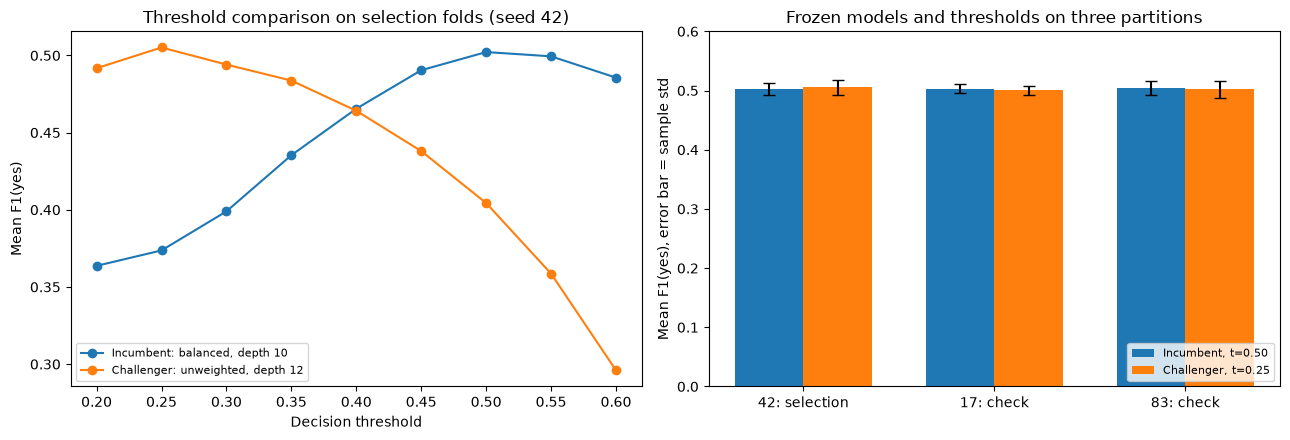

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, label in [("balanced_d10_leaf1", "Incumbent: balanced, depth 10"),
                     ("unweighted_d12_leaf1", "Challenger: unweighted, depth 12")]:
    means = [improvement_scores[(name, t)]["f1_yes"].mean() for t in IMPROVEMENT_THRESHOLDS]
    axes[0].plot(IMPROVEMENT_THRESHOLDS, means, marker="o", label=label)
axes[0].set(xlabel="Decision threshold", ylabel="Mean F1(yes)",
            title="Threshold comparison on selection folds (seed 42)")
axes[0].legend(fontsize=8)
positions = np.arange(3)
for offset, label, name, threshold in [(-0.18, "Incumbent, t=0.50", "balanced_d10_leaf1", 0.50),
                                      (0.18, "Challenger, t=0.25", "unweighted_d12_leaf1", 0.25)]:
    key = "incumbent" if name.startswith("balanced") else "challenger"
    scores = [improvement_scores[(name, threshold)],
              robustness_scores[(17, key)], robustness_scores[(83, key)]]
    axes[1].bar(positions + offset, [s["f1_yes"].mean() for s in scores], width=0.36,
                yerr=[s["f1_yes"].std() for s in scores], capsize=4, label=label)
axes[1].set(xticks=positions, xticklabels=["42: selection", "17: check", "83: check"],
            ylabel="Mean F1(yes), error bar = sample std", ylim=(0, 0.60),
            title="Frozen models and thresholds on three partitions")
axes[1].legend(fontsize=8, loc="lower right")
fig.tight_layout()
save_figure(fig, "improvement_comparison.png")

The left panel shows why unweighted forests needed their own threshold comparison: they perform
best around 0.25, whereas the balanced incumbent peaks at 0.50. The right panel shows the small
seed-42 advantage reversing on both additional partitions. Error bars describe fold variation,
without establishing significance; the outcome supports keeping the existing model.

- *What is the most important correction to the earlier report?* Class weighting helped at a
  common 0.5 threshold, but unweighted forests can reach similar F1 after their threshold is tuned.
- *What would improve the evidence next?* An evaluation planned before exploration, using an
  untouched set or a nested selection procedure; more tuning on these same folds would not supply that.

## Phase 4d — missing-value handling and split criterion

The next bounded experiment addresses alternatives the earlier depth/threshold search did not test.
Before running, the budget was ten configurations (including the incumbent), nine thresholds from
0.20 to 0.60 in steps of 0.05, and at most four targeted follow-ups. We then froze one challenger
and its threshold before checking splitter seeds 23 and 91, keeping estimator seed 42 throughout.

Missing indicators/categories are covered in Lecture 2 p.52; forest feature subsets and entropy
are in Lecture 3 pp.72–74 and the Week 3 coding guide pp.6–7. The supplied staff reply in
[Project clarifications](https://edstem.org/au/courses/37676/discussion/3628154) permits built-in
tree/forest missing-value support. Our earlier SimpleImputer-only choice was a simplification,
not a staff prohibition. No financial feature engineering, resampling or custom imputer is used.

These remain development experiments. The same clients have been explored repeatedly, so even the
additional partitions are sensitivity checks, not an independent test of hidden-test performance.
The historical conclusions in Phases 2–4c describe the model at that stage; Phase 6 below is authoritative
for the final submitted configuration.

In [56]:
def make_round2_pipeline(spec):
    numeric = spec.get('numeric', 'median')
    num = 'passthrough' if numeric == 'native' else SimpleImputer(
        strategy='median', add_indicator=numeric == 'indicator')
    missing = spec.get('categorical') == 'missing'
    impute = SimpleImputer(strategy='constant', fill_value='__missing__') if missing else SimpleImputer(strategy='most_frequent')
    demographics = Pipeline([('impute', impute), ('encode', OneHotEncoder(handle_unknown='ignore'))])
    repayment = spec.get('repayment', 'ordinal')
    if repayment == 'native':
        rep = OrdinalEncoder(categories=[STATUS_ORDER + [np.nan]] * len(repayment_columns),
                             handle_unknown='use_encoded_value', unknown_value=np.nan,
                             encoded_missing_value=np.nan)
    else:
        encoder = OneHotEncoder(handle_unknown='ignore') if repayment == 'onehot' else OrdinalEncoder(
            categories=[STATUS_ORDER] * len(repayment_columns), handle_unknown='use_encoded_value', unknown_value=-1)
        rep_impute = SimpleImputer(strategy='constant', fill_value='__missing__') if missing else SimpleImputer(strategy='most_frequent')
        rep = Pipeline([('impute', rep_impute), ('encode', encoder)])
    prep = ColumnTransformer([('numeric', num, numeric_columns),
                              ('demographic', demographics, demographic_columns),
                              ('repayment', rep, repayment_columns)], sparse_threshold=0)
    forest = RandomForestClassifier(n_estimators=spec.get('n_estimators', 100),
        max_depth=spec.get('max_depth', 10), min_samples_leaf=spec.get('min_samples_leaf', 1),
        max_features=spec.get('max_features', 'sqrt'), criterion=spec.get('criterion', 'gini'),
        class_weight=spec.get('class_weight', 'balanced'), random_state=42, n_jobs=-1)
    return Pipeline([('preprocess', prep), ('model', forest)])

The builder changes only the options named in each specification. Defaults reproduce the previous
median/mode, ordinal, balanced depth-10 forest; the numeric-indicator variant appends missingness flags,
and missing-category variants keep categorical absence distinct from observed categories.
The native variant keeps numeric NaNs and encodes missing or unseen repayment statuses as NaN, letting
each tree learn their left/right routing using only training-fold data; demographic mode imputation remains.

The sentinel trial maps missing/unseen repayment labels to -1, an explicitly artificial position before
the known statuses. Native handling avoids assigning missing values that numerical position, but still
assumes the stated order of observed repayment labels. All fitted preprocessing stays in the pipeline.
Implementation reference: [scikit-learn RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

Check your understanding:
- *What does native missing handling mean here?* The NaN reaches the forest unchanged. When a tree
  chooses a split, scikit-learn also chooses whether rows with a missing value go left or right, using
  the training rows and the split criterion.
- *How does the -1 sentinel differ?* It places every missing status below `no_balance` on the same
  numeric scale, so a split must treat it as the lowest status; NaN gets its own learned direction.
- *Does native handling use validation labels?* No. Routing is learned when each fold's forest is
  fitted on that fold's training rows only.

In [57]:
ROUND2_THRESHOLDS = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
round2_stage1_specs = [{'name': 'incumbent'},
 {'name': 'numeric_indicator', 'numeric': 'indicator'},
 {'name': 'missing_category', 'categorical': 'missing'},
 {'name': 'missing_category_onehot', 'categorical': 'missing', 'repayment': 'onehot'},
 {'name': 'native_numeric', 'numeric': 'native'},
 {'name': 'native_numeric_repayment', 'numeric': 'native', 'repayment': 'native'},
 {'name': 'half_features', 'max_features': 0.5},
 {'name': 'all_features', 'max_features': 1.0},
 {'name': 'entropy', 'criterion': 'entropy'},
 {'name': 'entropy_half_features', 'criterion': 'entropy', 'max_features': 0.5}]
round2_scores = {}
round2_probabilities = {}


def run_round2(specifications):
    """Collect held-out probabilities once, then compare thresholds without extra fitting."""
    for spec in specifications:
        probability, fold_ids = out_of_fold_yes_probabilities(make_round2_pipeline(spec))
        round2_probabilities[spec['name']] = (probability, fold_ids)
        for threshold in ROUND2_THRESHOLDS:
            round2_scores[(spec['name'], threshold)] = threshold_fold_scores(probability, fold_ids, threshold)
        print('Completed:', spec['name'])


run_round2(round2_stage1_specs)
print(metric_summary_text(round2_scores).to_string())

Completed: incumbent


Completed: numeric_indicator


Completed: missing_category


Completed: missing_category_onehot


Completed: native_numeric


Completed: native_numeric_repayment


Completed: half_features


Completed: all_features


Completed: entropy


Completed: entropy_half_features
                                      accuracy    precision_yes       recall_yes           f1_yes         macro_f1 balanced_accuracy
incumbent                0.20  0.227 +/- 0.003  0.222 +/- 0.001  0.999 +/- 0.001  0.364 +/- 0.001  0.189 +/- 0.005   0.503 +/- 0.002
                         0.25  0.267 +/- 0.009  0.230 +/- 0.002  0.989 +/- 0.002  0.374 +/- 0.003  0.245 +/- 0.011   0.525 +/- 0.005
                         0.30  0.376 +/- 0.008  0.254 +/- 0.002  0.936 +/- 0.004  0.399 +/- 0.003  0.375 +/- 0.008   0.577 +/- 0.004
                         0.35  0.505 +/- 0.010  0.291 +/- 0.004  0.863 +/- 0.005  0.435 +/- 0.005  0.497 +/- 0.009   0.633 +/- 0.007
                         0.40  0.614 +/- 0.010  0.336 +/- 0.005  0.759 +/- 0.012  0.465 +/- 0.003  0.582 +/- 0.007   0.666 +/- 0.003
                         0.45  0.707 +/- 0.005  0.398 +/- 0.006  0.638 +/- 0.008  0.490 +/- 0.006  0.642 +/- 0.005   0.682 +/- 0.005
                         0.50  0.770

Preserving missing repayment information helped more than adding a numeric indicator. Native numeric
and repayment handling reached F1 0.507594, and explicit missing categories with one-hot repayment reached
0.507557, versus 0.502192 for the incumbent. Larger feature subsets reduced F1; these are comparative
observations, not a causal explanation of the missing-data mechanism.

Four adaptive follow-ups were therefore chosen: native handling with depth 8, depth 12 or entropy,
and missing-category/one-hot handling with entropy. This choice uses the first-stage results and adds
selection bias; the complete search is disclosed rather than treating the winning trial as pre-specified.

Check your understanding:
- *Why compare thresholds for every configuration?* Different preprocessing can move the predicted
  probabilities, so each option is compared at its best tested threshold using its stored held-out probabilities.
- *Do these results show why values are missing?* No. They only show which handling gave higher
  held-out F1(yes) on these folds.

In [58]:
round2_stage2_specs = [{'name': 'native_depth8', 'numeric': 'native', 'repayment': 'native', 'max_depth': 8},
 {'name': 'native_depth12', 'numeric': 'native', 'repayment': 'native', 'max_depth': 12},
 {'name': 'native_entropy',
  'numeric': 'native',
  'repayment': 'native',
  'criterion': 'entropy'},
 {'name': 'missing_onehot_entropy',
  'categorical': 'missing',
  'repayment': 'onehot',
  'criterion': 'entropy'}]
run_round2(round2_stage2_specs)
print('Follow-ups: all six metrics for every threshold (mean +/- sample std):')
print(metric_summary_text({key: value for key, value in round2_scores.items()
                          if key[0] in [s['name'] for s in round2_stage2_specs]}).to_string())
round2_best = {s['name']: max(ROUND2_THRESHOLDS,
                  key=lambda t: round2_scores[(s['name'], t)]['f1_yes'].mean())
               for s in round2_stage1_specs + round2_stage2_specs}
print('Best tested threshold per configuration:')
print(metric_summary_text({(name, t): round2_scores[(name, t)] for name, t in round2_best.items()}).to_string())

Completed: native_depth8


Completed: native_depth12


Completed: native_entropy


Completed: missing_onehot_entropy
Follow-ups: all six metrics for every threshold (mean +/- sample std):
                                    accuracy    precision_yes       recall_yes           f1_yes         macro_f1 balanced_accuracy
native_depth8          0.20  0.221 +/- 0.001  0.221 +/- 0.000  1.000 +/- 0.000  0.362 +/- 0.000  0.182 +/- 0.001   0.500 +/- 0.000
                       0.25  0.234 +/- 0.005  0.224 +/- 0.001  0.997 +/- 0.001  0.365 +/- 0.001  0.200 +/- 0.006   0.507 +/- 0.003
                       0.30  0.316 +/- 0.007  0.240 +/- 0.001  0.966 +/- 0.007  0.385 +/- 0.002  0.308 +/- 0.009   0.549 +/- 0.003
                       0.35  0.464 +/- 0.011  0.278 +/- 0.004  0.887 +/- 0.006  0.423 +/- 0.004  0.461 +/- 0.010   0.616 +/- 0.006
                       0.40  0.600 +/- 0.013  0.329 +/- 0.007  0.776 +/- 0.014  0.462 +/- 0.006  0.572 +/- 0.010   0.663 +/- 0.006
                       0.45  0.715 +/- 0.006  0.406 +/- 0.007  0.628 +/- 0.009  0.493 +/- 0.004  0.647 +/- 0.

Native handling with entropy gave the highest mean selection-fold F1, 0.509415, at threshold 0.50.
We froze its preprocessing, 100 trees, depth 10, leaf size 1, balanced weights, sqrt feature subsets,
entropy criterion and threshold before the next checks. Splitter seeds 23 and 91 had been written into
the plan before the initial experiments; neither model nor threshold is retuned on them.

Check your understanding:
- *Why freeze before the partition checks?* If the model or threshold could change after seeing seeds
  23 and 91, those checks would become further tuning rather than a sensitivity check.
- *Why are the four follow-ups called adaptive?* They were chosen after seeing the first-stage results,
  which adds selection bias; the notebook discloses this instead of presenting them as pre-planned.

In [59]:
ROUND2_FINAL_SPEC = {'name': 'native_entropy', 'numeric': 'native', 'repayment': 'native', 'criterion': 'entropy'}
round2_robustness = {}
for split_seed in [23, 91]:
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=split_seed)
    for label, spec in [('incumbent', {'name': 'incumbent'}), ('native_entropy', ROUND2_FINAL_SPEC)]:
        probability, fold_ids = out_of_fold_yes_probabilities(make_round2_pipeline(spec), folds)
        scores = threshold_fold_scores(probability, fold_ids, 0.50)
        round2_robustness[(split_seed, label)] = scores
        print(split_seed, label)
        print(scores.round(6).to_string())
print(metric_summary_text(round2_robustness).to_string())
for seed in [23, 91]:
    difference = (round2_robustness[(seed, 'native_entropy')]['f1_yes']
                  - round2_robustness[(seed, 'incumbent')]['f1_yes'])
    print(seed, 'mean F1 change:', difference.mean(), 'paired fold wins:', (difference > 0).sum())

23 incumbent
      accuracy  precision_yes  recall_yes    f1_yes  macro_f1  balanced_accuracy
fold                                                                            
1     0.772500       0.486415    0.523091  0.504087  0.678240           0.683183
2     0.774583       0.491055    0.516949  0.503670  0.678924           0.682364
3     0.773542       0.489434    0.545198  0.515813  0.684011           0.691807
4     0.757917       0.458949    0.526365  0.490351  0.665804           0.675034
5     0.767500       0.476923    0.525424  0.500000  0.674267           0.680850


23 native_entropy
      accuracy  precision_yes  recall_yes    f1_yes  macro_f1  balanced_accuracy
fold                                                                            
1     0.776250       0.494283    0.529689  0.511374  0.683139           0.687952
2     0.779375       0.501333    0.531073  0.515775  0.686459           0.690497
3     0.776042       0.494421    0.542373  0.517288  0.685743           0.692401
4     0.763958       0.469423    0.513183  0.490328  0.668371           0.674194
5     0.771875       0.486005    0.539548  0.511379  0.681291           0.688715


91 incumbent
      accuracy  precision_yes  recall_yes    f1_yes  macro_f1  balanced_accuracy
fold                                                                            
1     0.774375       0.490534    0.537229  0.512821  0.683006           0.689449
2     0.767708       0.477331    0.525424  0.500224  0.674457           0.680984
3     0.761875       0.466165    0.525424  0.494024  0.669162           0.677238
4     0.770417       0.483193    0.541431  0.510657  0.680342           0.688452
5     0.776667       0.495520    0.520716  0.507805  0.681685           0.685050


91 native_entropy
      accuracy  precision_yes  recall_yes    f1_yes  macro_f1  balanced_accuracy
fold                                                                            
1     0.775833       0.493415    0.529689  0.510909  0.682752           0.687685
2     0.776042       0.494401    0.540490  0.516419  0.685348           0.691727
3     0.761875       0.466334    0.528249  0.495364  0.669768           0.678249
4     0.775625       0.493540    0.539548  0.515520  0.684763           0.691122
5     0.777083       0.496448    0.526365  0.510969  0.683304           0.687340
                          accuracy    precision_yes       recall_yes           f1_yes         macro_f1 balanced_accuracy
23 incumbent       0.769 +/- 0.007  0.481 +/- 0.013  0.527 +/- 0.011  0.503 +/- 0.009  0.676 +/- 0.007   0.683 +/- 0.006
   native_entropy  0.774 +/- 0.006  0.489 +/- 0.012  0.531 +/- 0.011  0.509 +/- 0.011  0.681 +/- 0.007   0.687 +/- 0.007
91 incumbent       0.770 +/- 0.006  0.483 +/- 0.011 

**Decision: adopt native numeric/repayment missing-value handling and entropy splits.**
The improvement remained positive on both additional partitions, unlike the earlier depth/threshold
challenger. It is a modest gain from two understandable changes, with no additional model family.

- Split seed 42: previous 0.502192, new 0.509415; difference +0.007223; new model wins 4/5 paired folds.
- Split seed 23: previous 0.502784, new 0.509229; difference +0.006445; new model wins 4/5 paired folds.
- Split seed 91: previous 0.505106, new 0.509836; difference +0.004730; new model wins 4/5 paired folds.

All three partitions use overlapping clients; the folds are not independent observations. We do not
claim statistical significance, an unbiased generalisation estimate, or a guaranteed hidden-test gain.
The final reported score continues to use the original seed-42 five-fold convention.

Check your understanding:
- *Why accept this change but reject the Phase 4c challenger?* This gain was larger (0.007223 versus
  0.002967) and stayed positive on both frozen partition checks; the Phase 4c gain reversed on both.
- *What changed from the previous model?* Two settings: numeric and repayment NaNs are kept rather than
  imputed, and splits use entropy rather than Gini. Trees, depth, leaf size, weights and threshold are unchanged.
- *Do 4/5 fold wins on three partitions prove the gain?* No. The partitions reuse the same clients, so
  they show the result is not tied to one fold assignment; they are not a significance test.

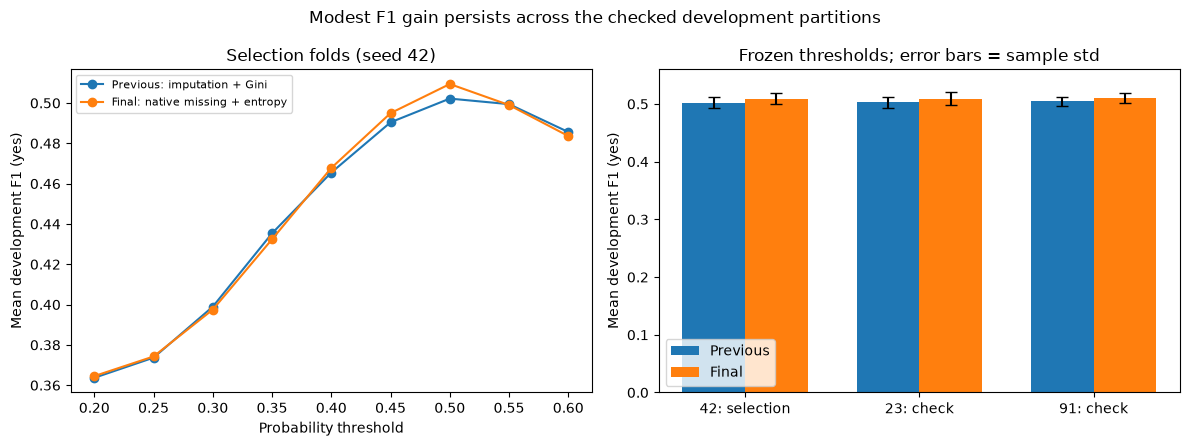

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, label in [('incumbent', 'Previous: imputation + Gini'),
                    ('native_entropy', 'Final: native missing + entropy')]:
    axes[0].plot(ROUND2_THRESHOLDS, [round2_scores[(name, t)]['f1_yes'].mean()
                 for t in ROUND2_THRESHOLDS], marker='o', label=label)
axes[0].set(xlabel='Probability threshold', ylabel='Mean development F1 (yes)', title='Selection folds (seed 42)')
axes[0].legend(fontsize=8)
for offset, name, label in [(-0.18, 'incumbent', 'Previous'), (0.18, 'native_entropy', 'Final')]:
    scores = [round2_scores[(name, .5)], round2_robustness[(23, name)], round2_robustness[(91, name)]]
    axes[1].bar(np.arange(3) + offset, [s.f1_yes.mean() for s in scores], width=.36,
                yerr=[s.f1_yes.std() for s in scores], capsize=4, label=label)
axes[1].set(xticks=np.arange(3), xticklabels=['42: selection', '23: check', '91: check'],
            ylabel='Mean development F1 (yes)', ylim=(0, .56), title='Frozen thresholds; error bars = sample std')
axes[1].legend()
fig.suptitle('Modest F1 gain persists across the checked development partitions')
fig.tight_layout()
save_figure(fig, 'missing_handling_comparison.png')

The left panel shows that 0.50 is the best tested threshold for both compared models on selection folds.
The right panel shows the new model's mean F1 is higher on each partition; error bars describe within-
partition fold variability, not confidence intervals or a significance test. These observations support
the revised final choice while leaving hidden-test performance unknown.

Check your understanding:
- *Why does the left panel matter?* Both models peak at 0.50, so the gain did not require a new threshold.
- *Are the error bars confidence intervals?* No. They show the spread of five dependent fold scores.

## Phase 4e — final parameter check

This check asks whether small changes to the selected forest improve F1. Six variants of the
native-missing/entropy forest were specified before running: 300 trees, depth 8/12, leaf size 5/10, or max_features=0.5.
The current model is included as the reference. All seven configurations compare thresholds
0.46–0.56 in steps of 0.01 on the original seed-42 stratified folds. Model seed remains 42.

There are no adaptive follow-ups. A challenger would need at least 0.002 higher selection-fold F1
before it could be frozen and checked on predeclared splitter seeds 137 and 211. It would replace
the incumbent only if the gain remained positive on both checks. This practical margin is not a
significance test. 

The notebook reuses the current model's already computed out-of-fold probabilities and fits six
new configurations, then evaluates all 77 configuration/threshold combinations. An initial exploratory
run of the same plan outside the notebook also refitted the current model (35 fits); this cell makes 30 new fits.
These are further reused-data comparisons and increase selection bias, rather than adding an
independent evaluation. The final reporting convention does not change.

In [61]:

ROUND3_THRESHOLDS = [0.46, 0.47, 0.48, 0.49, 0.5, 0.51, 0.52, 0.53, 0.54, 0.55, 0.56]
round3_specs = [{'name': 'current'},
 {'name': 'trees300', 'n_estimators': 300},
 {'name': 'entropy_depth8', 'max_depth': 8},
 {'name': 'entropy_depth12', 'max_depth': 12},
 {'name': 'entropy_leaf5', 'min_samples_leaf': 5},
 {'name': 'entropy_leaf10', 'min_samples_leaf': 10},
 {'name': 'native_entropy_half_features', 'max_features': 0.5}]
round3_scores = {}
for spec in round3_specs:
    if spec['name'] == 'current':
        probability, fold_ids = round2_probabilities['native_entropy']
    else:
        full_spec = {'numeric': 'native', 'repayment': 'native', 'criterion': 'entropy', **spec}
        probability, fold_ids = out_of_fold_yes_probabilities(make_round2_pipeline(full_spec))
    for threshold in ROUND3_THRESHOLDS:
        round3_scores[(spec['name'], threshold)] = threshold_fold_scores(probability, fold_ids, threshold)
print('Every tested combination; all six metrics as mean +/- sample std:')
print(metric_summary_text(round3_scores).to_string())
round3_leader = max(round3_scores, key=lambda key: round3_scores[key]['f1_yes'].mean())
round3_gain = (round3_scores[round3_leader]['f1_yes'].mean()
               - round3_scores[('current', .5)]['f1_yes'].mean())
print('Best tested:', round3_leader, 'F1:', round3_scores[round3_leader]['f1_yes'].mean())
print('Gain over current:', round3_gain)
assert round3_leader == ('entropy_depth12', .49)
assert round3_gain < .002
print('Decision: retain current pipeline and threshold. No further partition checks triggered.')

Every tested combination; all six metrics as mean +/- sample std:
                                          accuracy    precision_yes       recall_yes           f1_yes         macro_f1 balanced_accuracy
current                      0.46  0.726 +/- 0.004  0.419 +/- 0.005  0.616 +/- 0.006  0.499 +/- 0.004  0.655 +/- 0.003   0.687 +/- 0.003
                             0.47  0.740 +/- 0.003  0.436 +/- 0.004  0.592 +/- 0.008  0.502 +/- 0.004  0.663 +/- 0.003   0.687 +/- 0.003
                             0.48  0.752 +/- 0.004  0.453 +/- 0.006  0.572 +/- 0.008  0.506 +/- 0.007  0.670 +/- 0.005   0.688 +/- 0.005
                             0.49  0.763 +/- 0.004  0.470 +/- 0.008  0.553 +/- 0.009  0.508 +/- 0.008  0.676 +/- 0.005   0.688 +/- 0.006
                             0.50  0.772 +/- 0.005  0.487 +/- 0.010  0.535 +/- 0.012  0.509 +/- 0.010  0.681 +/- 0.007   0.687 +/- 0.007
                             0.51  0.779 +/- 0.006  0.501 +/- 0.014  0.516 +/- 0.013  0.508 +/- 0.012  0.683 +/-

**Decision: retain the 100-tree, depth-10, leaf-1 native-missing/entropy forest at threshold 0.50.**
The best new combination was depth 12 at threshold 0.49, F1 0.509592
+/- 0.009042. Its gain was only 0.000177, below the declared 0.002 margin.
It would add depth and a changed threshold for almost no demonstrated benefit. The original model
also peaks at 0.50 within the finer threshold comparison. Neither 300 trees nor larger leaf sizes
improved the selection-fold mean. No additional partition checks were triggered and no test data
were used for these choices. This result does not prove that all future permitted approaches must fail.

Check your understanding:
- *Why not adopt depth 12 at 0.49?* Its gain (0.000177) is far smaller than the fold standard deviation
  (about 0.010) and below the declared 0.002 margin; it would add depth and a new threshold for no demonstrated benefit.
- *Why fix the margin before running?* Choosing it after seeing the results would make it easy to accept
  whichever small difference happened to favour a challenger.

## Phase 4f — further preprocessing and model checks

This round tests different choices from the preceding depth/threshold refinement: explicit demographic absence,
one-hot repayment with its own missing category, both together, unweighted native-missing forests,
two regularisation settings, and k-NN with 15/31 neighbours. These are the same taught imputation,
encoding, scaling, classifier and tree-growth concepts; no additional model family is introduced.

Before running, the fixed budget was ten configurations (including the incumbent), each at thresholds
0.20–0.60 in steps of 0.05: 90 combinations from 50 fits. There are no adaptive follow-ups. A challenger
must improve mean selection-fold F1 by at least 0.002 before a frozen configuration/threshold is checked
on predeclared splitter seeds 307 and 509. Both must retain a positive gain before replacement.
All selection uses development data, original five stratified folds (seed 42) and model seed 42 where
the estimator supports one. Additional partitions would still reuse clients and not remove selection bias.

In [62]:
def make_audit_pipeline(spec):
    """Compare a named missing-category choice or classifier setting inside one pipeline."""
    if spec.get('family')=='knn':
        numeric=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
        categorical=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                              ('encode',OneHotEncoder(handle_unknown='ignore'))])
        prep=ColumnTransformer([('numeric',numeric,numeric_columns),
             ('categorical',categorical,demographic_columns+repayment_columns)],sparse_threshold=0)
        model=KNeighborsClassifier(n_neighbors=spec['n_neighbors'],weights='uniform',p=2,n_jobs=-1)
        return Pipeline([('preprocess',prep),('model',model)])
    demo_imputer=(SimpleImputer(strategy='constant',fill_value='__missing__')
                  if spec.get('demographic_missing') else SimpleImputer(strategy='most_frequent'))
    demographics=Pipeline([('impute',demo_imputer),('one_hot',OneHotEncoder(handle_unknown='ignore'))])
    if spec.get('status_onehot'):
        repayment=Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='__missing__')),
                             ('encode',OneHotEncoder(handle_unknown='ignore'))])
    else:
        repayment=OrdinalEncoder(categories=[STATUS_ORDER+[np.nan]]*len(repayment_columns),
            handle_unknown='use_encoded_value',unknown_value=np.nan,encoded_missing_value=np.nan)
    prep=ColumnTransformer([('numeric','passthrough',numeric_columns),
        ('demographic',demographics,demographic_columns),
        ('repayment',repayment,repayment_columns)],sparse_threshold=0)
    model=RandomForestClassifier(n_estimators=100,criterion='entropy',max_depth=spec.get('max_depth',10),
        min_samples_leaf=spec.get('min_samples_leaf',1),class_weight=spec.get('class_weight','balanced'),
        random_state=42,n_jobs=-1)
    return Pipeline([('preprocess',prep),('model',model)])

The builder keeps numeric NaNs for every new forest. A named choice changes only demographic
imputation, repayment encoding or the stated forest parameters; missing repayment indicators here
are ordinary one-hot category columns, not reconstructed financial features. The two k-NN variants
instead use the same median/mode, one-hot and numeric standardisation as the original k=5 baseline,
so their distances use comparable units and their missing values are filled inside each training fold.

Check your understanding:
- Why try a missing category? It distinguishes absence from an observed common label; validation must
  establish whether that helps rather than assuming missingness predicts default.
- Why fill/scale for k-NN but retain NaNs for the forest? These are estimator-specific pipelines;
  this k-NN implementation needs finite numeric distances, while the permitted forest handles NaNs.
- Why no random_state on k-NN? Its neighbour rule is deterministic; random_state is not its parameter.

In [63]:
AUDIT_THRESHOLDS = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]
audit_specs = [{'name': 'current'},
 {'name': 'demographic_missing', 'demographic_missing': True},
 {'name': 'status_onehot_missing', 'status_onehot': True},
 {'name': 'all_categorical_missing', 'demographic_missing': True, 'status_onehot': True},
 {'name': 'native_unweighted', 'class_weight': None},
 {'name': 'native_unweighted_full_leaf10',
  'class_weight': None,
  'max_depth': None,
  'min_samples_leaf': 10},
 {'name': 'native_shallow_leaf5', 'max_depth': 6, 'min_samples_leaf': 5},
 {'name': 'native_full_leaf10', 'max_depth': None, 'min_samples_leaf': 10},
 {'name': 'knn15', 'family': 'knn', 'n_neighbors': 15},
 {'name': 'knn31', 'family': 'knn', 'n_neighbors': 31}]
audit_scores = {}
for spec in audit_specs:
    probability, fold_ids = out_of_fold_yes_probabilities(make_audit_pipeline(spec))
    for threshold in AUDIT_THRESHOLDS:
        audit_scores[(spec['name'], threshold)] = threshold_fold_scores(probability, fold_ids, threshold)
    print('Completed:', spec['name'])
print('All 90 comparisons: six metric means and sample standard deviations')
print(metric_summary_text(audit_scores).to_string())
audit_best_thresholds = {
    spec['name']: max(AUDIT_THRESHOLDS,
        key=lambda threshold: audit_scores[(spec['name'], threshold)]['f1_yes'].mean())
    for spec in audit_specs
}
print('Best tested threshold per configuration:')
print(metric_summary_text({(name, threshold): audit_scores[(name, threshold)]
    for name, threshold in audit_best_thresholds.items()}).to_string())
audit_leader = max(audit_scores, key=lambda key: audit_scores[key]['f1_yes'].mean())
audit_gain = (audit_scores[audit_leader]['f1_yes'].mean()
              - audit_scores[('current', .5)]['f1_yes'].mean())
assert audit_gain < .002
print('Retain the current forest: no challenger met the declared replacement margin.')

Completed: current


Completed: demographic_missing


Completed: status_onehot_missing


Completed: all_categorical_missing


Completed: native_unweighted


Completed: native_unweighted_full_leaf10


Completed: native_shallow_leaf5


Completed: native_full_leaf10


Completed: knn15


Completed: knn31
All 90 comparisons: six metric means and sample standard deviations
                                           accuracy    precision_yes       recall_yes           f1_yes         macro_f1 balanced_accuracy
current                       0.20  0.230 +/- 0.005  0.223 +/- 0.001  0.998 +/- 0.002  0.365 +/- 0.001  0.194 +/- 0.007   0.505 +/- 0.003
                              0.25  0.270 +/- 0.011  0.231 +/- 0.002  0.987 +/- 0.006  0.374 +/- 0.002  0.249 +/- 0.015   0.527 +/- 0.005
                              0.30  0.371 +/- 0.009  0.252 +/- 0.002  0.938 +/- 0.008  0.398 +/- 0.002  0.370 +/- 0.009   0.574 +/- 0.004
                              0.35  0.500 +/- 0.012  0.289 +/- 0.005  0.860 +/- 0.006  0.432 +/- 0.006  0.493 +/- 0.011   0.629 +/- 0.008
                              0.40  0.617 +/- 0.014  0.338 +/- 0.009  0.761 +/- 0.007  0.468 +/- 0.007  0.584 +/- 0.011   0.668 +/- 0.007
                              0.45  0.710 +/- 0.005  0.403 +/- 0.005  0.641 +/- 0.006  

The incumbent remained the strongest tested pipeline at F1 0.509415. Explicit demographic absence
reached 0.506840, one-hot/missing repayment 0.507684, and both categorical changes 0.508705.
The two unweighted native forests reached about 0.506; shallow/full-tree regularisation did not help.
Larger k-NN neighbourhoods with their own threshold comparisons improved that family's development
F1 to 0.426725 (k=15) and 0.436384 (k=31), but remained below the final forest. These k-NN differences
combine changes in k and threshold relative to the original default-rule k=5 baseline, not a pure k effect.

No candidate met the replacement margin, so no extra partitions were triggered. The final pipeline
and threshold remain fixed. All six metrics at every tested threshold are retained above; no failed
trial was silently removed. This is a bounded investigation, not proof of the globally best model.

Check your understanding:
- *Why report options that clearly lost, such as k-NN?* Unsuccessful trials are part of the evidence;
  removing them would make the final choice look more carefully established than it is.
- *Did Phase 4f change the submission?* No. No option met the 0.002 margin, so the pipeline, threshold
  and all 6,000 labels are unchanged.

## Phase 5 — ensembles

**No separate ensemble model is built, by design.** Staff recommend using only Random Forest for ensemble
techniques (Clarification E). The random forest in Phases 3-4 is that ensemble: 100 trees, each trained on
a bootstrap sample with random feature subsets at each split, combined by averaging their probabilities.
An earlier project plan proposed an optional hard-vote ensemble of different classifiers; that plan is
superseded and was not run. No bagging, boosting, voting or stacking model was built.

## Phase 6 — final model

The final model is the **native-missing, entropy-split random forest** selected in Phase 4d.
It uses all 23 supplied predictors, excludes client_id, keeps numeric NaNs, mode-imputes and one-hot
encodes demographics, and ordinal-encodes repayment status while retaining missing/unseen statuses as
NaN. STATUS_ORDER still places no_balance, paid_on_time, revolving_credit before increasing delay lengths;
the first three labels' order remains an assumption. No scaling is required for tree splits.

The forest uses 100 trees, max_depth=10, min_samples_leaf=1, criterion="entropy", max_features="sqrt",
bootstrap=True, class_weight="balanced", random_state=42 and n_jobs=-1. The prediction rule is
yes when P(yes) >= 0.50. The final program fixes these choices and performs no search.

On the original five folds, F1 improves from 0.502192 to 0.509415; the gain persists on the two
additional partitions. The native handler learns missing-value routing inside each training fold,
without validation labels entering preprocessing. This relies on the documented scikit-learn version.

In [64]:
def build_final_pipeline():
    """The final preprocessing and model; every learned step is fitted only on the data passed to fit()."""
    # Numeric NaNs are retained: each tree learns their routing from its training data.
    demographic_steps = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ])
    # Encode known statuses in their stated order; preserve missing/unknown status as NaN.
    repayment_steps = OrdinalEncoder(
        categories=[STATUS_ORDER + [np.nan]] * len(repayment_columns),
        handle_unknown="use_encoded_value",
        unknown_value=np.nan,
        encoded_missing_value=np.nan,
    )
    preprocessor = ColumnTransformer(
        [
            ("numeric", "passthrough", numeric_columns),
            ("demographic", demographic_steps, demographic_columns),
            ("repayment", repayment_steps, repayment_columns),
        ],
        sparse_threshold=0,
    )
    forest = RandomForestClassifier(
        n_estimators=100,
        criterion="entropy",
        max_depth=10,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    return Pipeline([("preprocess", preprocessor), ("model", forest)])

# Frozen final configuration and its development CV metrics, computed exactly as main.py does.
FINAL_THRESHOLD = 0.5
final_pipeline = build_final_pipeline()
final_yes_probability, final_fold_of_row = out_of_fold_yes_probabilities(final_pipeline)
final_fold_scores = threshold_fold_scores(final_yes_probability, final_fold_of_row, FINAL_THRESHOLD)
print(final_fold_scores.round(3))

# The five metrics in the order required for the last row of the output file.
OUTPUT_METRICS = ["accuracy", "precision_yes", "recall_yes", "f1_yes", "macro_f1"]
final_metric_row = ",".join(f"{final_fold_scores[m].mean():.3f}" for m in OUTPUT_METRICS) + ","
print("\nExpected last row of the output file:", final_metric_row)
summarise(final_fold_scores)

      accuracy  precision_yes  recall_yes  f1_yes  macro_f1  balanced_accuracy
fold                                                                          
1        0.778          0.499       0.541   0.519     0.687              0.693
2        0.775          0.493       0.551   0.520     0.687              0.695
3        0.767          0.476       0.519   0.497     0.673              0.678
4        0.768          0.477       0.534   0.504     0.676              0.684
5        0.773          0.487       0.528   0.507     0.680              0.685

Expected last row of the output file: 0.772,0.487,0.535,0.509,0.681,


,mean,std
accuracy,0.772,0.005
precision_yes,0.487,0.010
recall_yes,0.535,0.012
f1_yes,0.509,0.010
macro_f1,0.681,0.007
balanced_accuracy,0.687,0.007


The six final metrics are calculated again from true/false positive/negative counts, using no
scikit-learn scoring function. This catches a copied scoring mistake that notebook/program agreement
alone might miss. The always-no control illustrates why high accuracy is insufficient for this task.

Check your understanding:
- Why is F1(yes) different from macro-F1? Macro-F1 averages the separate class F1 values; this project
  grades the F1 for default cases only.
- Why can the control have high accuracy but zero F1? Most clients are no, while it detects no yes cases.
- Are fold standard deviations confidence intervals? No; they describe variation among these dependent
  fold scores, and repeated tuning can still make their means optimistic.

In [65]:
# A second calculation uses raw confusion counts, independently of sklearn's metric functions.
manual_rows = []
majority_rows = []
for fold in range(1, 6):
    mask = final_fold_of_row == fold
    actual_yes = y.to_numpy()[mask] == POSITIVE_CLASS
    predicted_yes = final_yes_probability[mask] >= FINAL_THRESHOLD
    tp = int((actual_yes & predicted_yes).sum())
    tn = int((~actual_yes & ~predicted_yes).sum())
    fp = int((~actual_yes & predicted_yes).sum())
    fn = int((actual_yes & ~predicted_yes).sum())
    positive_f1 = 2 * tp / (2 * tp + fp + fn)
    negative_f1 = 2 * tn / (2 * tn + fp + fn)
    manual_rows.append({
        'accuracy': (tp + tn) / mask.sum(),
        'precision_yes': tp / (tp + fp),
        'recall_yes': tp / (tp + fn),
        'f1_yes': positive_f1,
        'macro_f1': (positive_f1 + negative_f1) / 2,
        'balanced_accuracy': (tp / (tp + fn) + tn / (tn + fp)) / 2,
    })
    majority_rows.append({'accuracy': (~actual_yes).mean(), 'f1_yes': 0., 'balanced_accuracy': .5})
manual_scores = pd.DataFrame(manual_rows, index=final_fold_scores.index)
np.testing.assert_allclose(manual_scores, final_fold_scores, rtol=0, atol=1e-15)
print('All six fold metrics agree with the independent confusion-count calculation.')
print('Always-no control (mean and sample std):')
print(pd.DataFrame(majority_rows).agg(['mean', 'std']).T.round(6))

All six fold metrics agree with the independent confusion-count calculation.
Always-no control (mean and sample std):
                       mean       std
accuracy           0.778792  0.000093
f1_yes             0.000000  0.000000
balanced_accuracy  0.500000  0.000000


In [66]:
# Check the actual probability/threshold rule, not an estimator's potentially different tie rule.
single_core_pipeline = clone(final_pipeline).set_params(model__n_jobs=1)
single_probability, single_fold_ids = out_of_fold_yes_probabilities(single_core_pipeline)
single_scores = threshold_fold_scores(single_probability, single_fold_ids, FINAL_THRESHOLD)
pd.testing.assert_frame_equal(single_scores, final_fold_scores, check_exact=True)
np.testing.assert_allclose(single_probability, final_yes_probability, rtol=0, atol=1e-12)
print("n_jobs=1 and n_jobs=-1: identical fold metrics; probabilities agree within 1e-12")

n_jobs=1 and n_jobs=-1: identical fold metrics; probabilities agree within 1e-12


In [67]:
# Fit the fixed final pipeline on all development rows; preserve the original test row order.
final_model = clone(final_pipeline).fit(X, y)
final_yes_column = list(final_model.classes_).index(POSITIVE_CLASS)
test_labels = labels_from_probability(
    final_model.predict_proba(test[predictor_columns])[:, final_yes_column], FINAL_THRESHOLD)
print("Test predictions:", len(test_labels), "| predicted yes:", (test_labels == POSITIVE_CLASS).sum())

# Run main.py first: compare every prediction and the correctly ordered metric row.
output_file = Path("s4976995.infs7203")
assert output_file.is_file(), "run python main.py before the notebook"
expected_lines = [f"{label}," for label in test_labels] + [final_metric_row]
assert output_file.read_text().splitlines() == expected_lines, "program/notebook output differs"
print(output_file.name, ": all 6,000 labels and the metric row match")

Test predictions: 6000 | predicted yes: 1420
s4976995.infs7203 : all 6,000 labels and the metric row match


In [68]:
# main.py is loaded independently; its fixed pipeline must reproduce the notebook's exact results.
import importlib.util
spec = importlib.util.spec_from_file_location("submission_main", Path("main.py").resolve())
submission_main = importlib.util.module_from_spec(spec)
spec.loader.exec_module(submission_main)
program_scores = submission_main.cross_validated_scores(X, y)
pd.testing.assert_frame_equal(program_scores, final_fold_scores, check_exact=True)
program_model = submission_main.build_pipeline().fit(X, y)
program_labels = submission_main.predict_labels(program_model, test[predictor_columns])
np.testing.assert_array_equal(program_labels, test_labels)
print("Independent main.py pipeline: exact six-metric fold parity and all 6,000 labels match")

Independent main.py pipeline: exact six-metric fold parity and all 6,000 labels match


This check imports the final program independently and recomputes all six fold metrics, so agreement
is checked before rounding rather than inferred from matching printed means. It also fits the
program's pipeline on all development rows and checks all 6,000 labels in original test order.
Assertions stop the notebook if either implementation drifts.

- *Why compare before rounding?* Two different calculations can round to the same three decimals;
  exact fold comparisons provide stronger evidence that the implementations agree.
- *What does this not establish?* Matching programs can still share modelling limitations, and
  neither reveals the hidden test labels or guarantees hidden-test performance.

**What these cells do.** `final-cv` rebuilds the chosen pipeline from scratch, recomputes its
out-of-fold probabilities on the same folds and applies the 0.5 rule; the result must match the Phase 4d
`native_entropy` row at threshold 0.50. It also builds the exact metric row that `main.py` writes as row 6,001.
`final-njobs-check` confirms that using all CPU cores does not change the results. `final-predict` fits
the pipeline on all development rows, predicts all 6,000 test rows in file order, and compares the notebook's labels and metric row with the file written by `main.py`;
the cell stops with an error if `main.py` has not been run first. The test file is
only used for prediction; nothing is fitted or chosen on it.

**Likely questions:**
- *Why refit on all development data?* The brief requires it (p.3); CV models each saw 80% of the data,
  and the final model should learn from all 24,000 labelled clients.
- *Why do notebook and `main.py` both contain the pipeline?* The notebook documents how it was chosen;
  `main.py` is the fixed recipe the markers run. The cross-check shows they produce identical output.
- *What would change the predictions?* Different data, parameters, column order or library versions. The
  seed, fixed folds and recorded versions make reruns identical in the documented environment.

## Phase 7 — summary, limitations and acknowledgement

Pipelines in the figure: 19


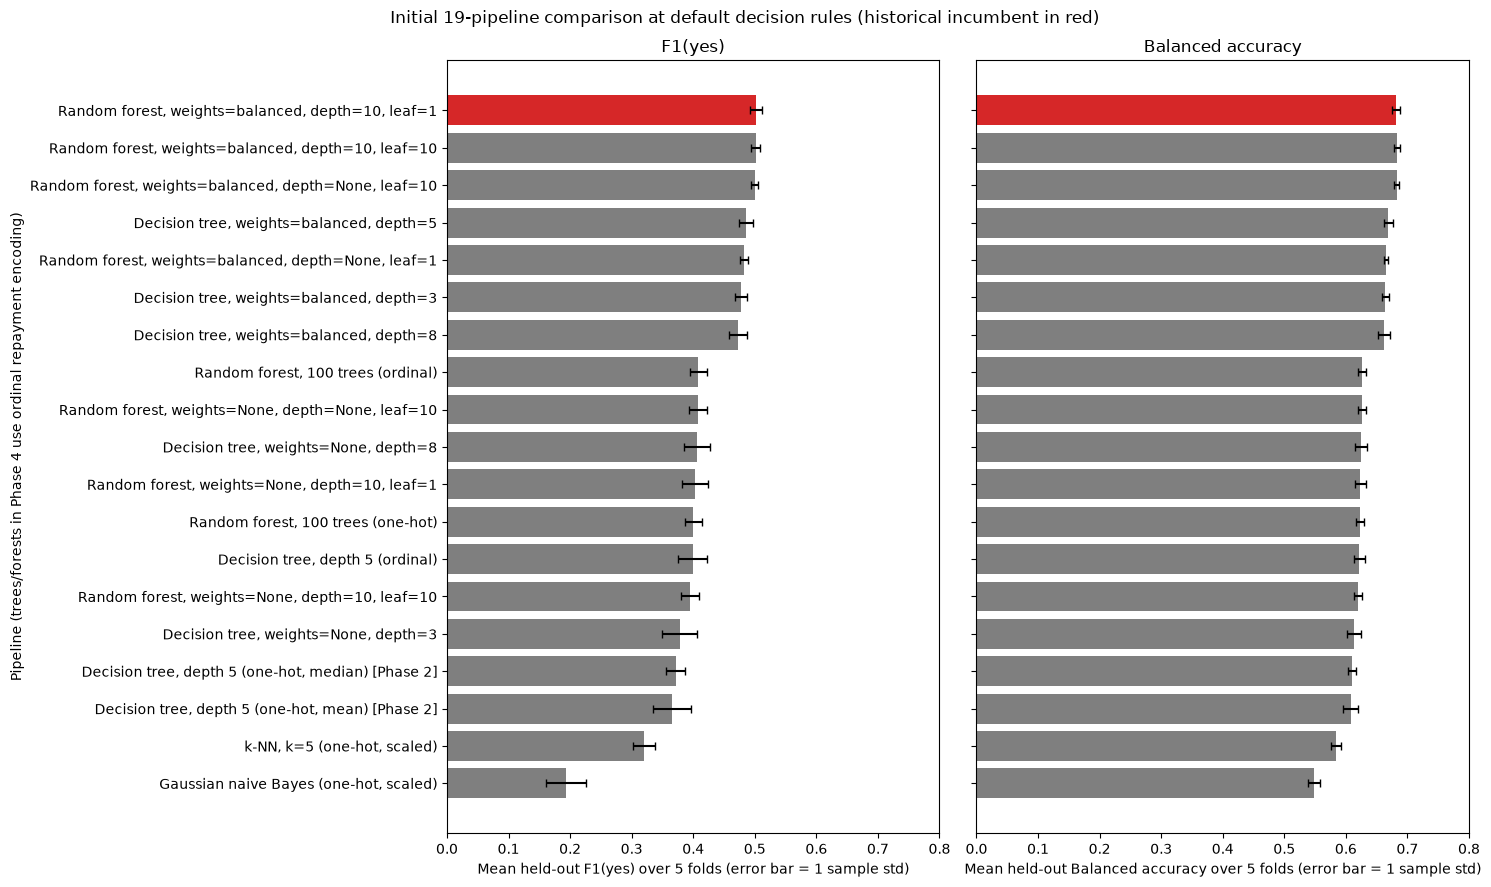

In [69]:
# Validation-performance comparison of the original 19 pipelines at their default decision rules (historical incumbent in red).
all_pipeline_scores = {
    "Decision tree, depth 5 (one-hot, median) [Phase 2]": median_fold_scores,
    "Decision tree, depth 5 (one-hot, mean) [Phase 2]": mean_fold_scores,
    **baseline_fold_scores,
}
repeated_baselines = ["Random forest, weights=None, depth=None, leaf=1", "Decision tree, weights=None, depth=5"]
for name, fold_scores in tuning_fold_scores.items():
    if name not in repeated_baselines:
        all_pipeline_scores[name] = fold_scores
print("Pipelines in the figure:", len(all_pipeline_scores))

ordered_names = sorted(all_pipeline_scores, key=lambda name: all_pipeline_scores[name]["f1_yes"].mean())
bar_colours = ["tab:red" if name == CANDIDATE_NAME else "tab:gray" for name in ordered_names]
fig, axes = plt.subplots(1, 2, figsize=(15, 9), sharey=True)
for ax, metric, label in [(axes[0], "f1_yes", "F1(yes)"), (axes[1], "balanced_accuracy", "Balanced accuracy")]:
    ax.barh(ordered_names,
            [all_pipeline_scores[name][metric].mean() for name in ordered_names],
            xerr=[all_pipeline_scores[name][metric].std() for name in ordered_names],
            color=bar_colours, capsize=3)
    ax.set_xlim(0, 0.8)
    ax.set_xlabel(f"Mean held-out {label} over 5 folds (error bar = 1 sample std)")
    ax.set_title(label)
axes[0].set_ylabel("Pipeline (trees/forests in Phase 4 use ordinal repayment encoding)")
fig.suptitle("Initial 19-pipeline comparison at default decision rules (historical incumbent in red)")
fig.tight_layout()
save_figure(fig, "model_comparison.png")

Historical figure: these are the initial 19 pipelines, before Phase 4d. The red bar is the previous model, not the revised final pipeline.

**What the figure shows.** The original 19 pipelines at their default decision rules, sorted by mean F1(yes), with balanced
accuracy alongside and one-standard-deviation error bars. The balanced random forests cluster at the top
(about 0.50), balanced trees next (about 0.47-0.49), unweighted trees and forests around 0.37-0.41, then
k-NN and naive Bayes. The later Phase 4c figure supplies the added threshold and partition checks. The original figure supports two decisions: the class-weighted forest family was carried forward,
and differences inside the top cluster are too small to rank confidently. Overlapping error bars are not
a significance test; they only show fold-to-fold variation.

Check your understanding:
- *Why keep a figure of historical models?* It records the comparison that selected the balanced forest
  family; Phase 4d later changed that forest's missing-value handling and split criterion.
- *Why sort the bars by mean F1(yes)?* F1(yes) is the selection metric, so the order shows which
  pipelines led on the assessed measure.

### Final result

Final pipeline: balanced random forest with 100 trees, depth 10, entropy splits, native numeric/repayment
missing-value handling, mode/one-hot demographics and threshold 0.50. All six metrics below use the
original five stratified folds (splitter/model seed 42); ± is the sample standard deviation (ddof=1).

- **Accuracy: 0.772 ± 0.005**.
- **Precision (yes): 0.487 ± 0.010**.
- **Recall (yes): 0.535 ± 0.012**.
- **F1 (yes): 0.509 ± 0.010**.
- **Macro-F1: 0.681 ± 0.007**.
- **Balanced accuracy: 0.687 ± 0.007**.

Output-file metric row: `0.772,0.487,0.535,0.509,0.681,`.

### What improved and what did not

The original median/mode and Gini forest reached F1 0.502192. Phase 4c's unweighted depth-12 challenger
reached 0.505159 but lost its gain on seeds 17 and 83, so it was rejected. Phase 4d's new native-missing
and entropy forest reaches 0.509415 and improves on both additional partition checks:

- Split seed 42: previous 0.502192, new 0.509415; difference +0.007223; new model wins 4/5 paired folds.
- Split seed 23: previous 0.502784, new 0.509229; difference +0.006445; new model wins 4/5 paired folds.
- Split seed 91: previous 0.505106, new 0.509836; difference +0.004730; new model wins 4/5 paired folds.

Numeric indicators alone (0.502435) and larger feature subsets (0.495863 / 0.494144) did not help enough.
Explicit missing categories with one-hot repayment reached 0.507557; native handling plus entropy gave
the highest selection-fold F1. Depth 8 or 12 with native handling was below native depth 10 plus entropy.
Earlier baselines, unsuccessful trials and all six metrics for every new threshold remain above.

A final parameter check (Phase 4e) tested six new variants and a finer threshold range.
Its best F1 was 0.509592, only 0.000177 higher, below the predeclared 0.002
replacement margin. The final pipeline and all 6,000 labels therefore remain unchanged.

Phase 4f tried nine further variants across missing-category choices, native unweighted forests,
regularisation and larger k-NN neighbourhoods. The selected model remained best at 0.509415; its pipeline
and threshold were retained. Phase 6 also checks fold coverage and
recomputes every final metric from confusion counts. Predictions are written to `s4976995.infs7203`
(UQ username s4976995; student number 49769959).

### Limitations

- The same clients/folds were repeatedly used for selection. Scores can be optimistic by an unknown
  amount; additional partitions do not remove selection bias. No statistical significance is claimed.
- Development predictors each have 40% missing values; test features have none. This mismatch may
  change the relationship between validation and hidden-test performance. Test data did not select methods.
- The ordering of the three non-delay repayment labels is assumed. Unknown repayment labels are treated
  as missing by the final encoder. Demographic absence is still mode-imputed.
- GaussianNB received baseline settings only. k-NN compared k=5, 15 and 31 with Euclidean distance;
  other distances and broader searches were not explored. GaussianNB on one-hot/skewed data makes
  distributional approximations.
- Random forests are less directly interpretable than a single tree. The code explains each processing stage, but 100 trees
  do not reduce to one simple human-readable rule.
- Unusual bills/payments and status mismatches were retained without speculative financial corrections.
- Native missing-value support is version-sensitive; use the recorded dependencies for reproduction.

### Course evidence

L2 pp.47–62: encoding, imputation, missing indicators/categories, scaling; L3 pp.9–20 and 55–74 plus
Week 3 coding guide pp.5–7: trees, pruning, forests, Gini/entropy; L4 pp.8–24 and 50–61 plus Week 4
coding guide pp.1–5: k-NN, naive Bayes and small parameter comparisons. Staff replies permit class
weights, development threshold selection and built-in forest missing-value support. No financial
engineered features, resampling, KNNImputer or separate ensemble is used.

### AI acknowledgement

OpenAI Codex and Cursor's AI coding assistant were used **under my direction and supervision** to
assist with organising source material, writing Python code, running experiments and reproducibility
checks, and drafting explanations and documentation. I supplied the course materials and staff
clarifications and directed the scope of the work.

In [70]:
# Exact environment used for these results (also listed in the README).
import platform
import sys

import matplotlib
import sklearn

print("OS:", platform.platform())
print("Python:", sys.version.split()[0])
print("numpy:", np.__version__, "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__, "| matplotlib:", matplotlib.__version__)
print("Random seed (folds and estimators):", RANDOM_STATE)

OS: Windows-11-10.0.26200-SP0
Python: 3.13.13
numpy: 2.5.4 | pandas: 3.0.6 | scikit-learn: 1.9.1 | matplotlib: 3.11.2
Random seed (folds and estimators): 42
